In [2]:
import pandas as pd
import numpy as np

In [3]:
# IMPORTAR BASE DE DATOS 
df = pd.read_excel(r'../data/raw/copy_dbsirima_v4.xlsx', header=1, engine='calamine')

In [4]:
df.iloc[:,11:30].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 19 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   Municipality                              1866 non-null   object
 1   Number of sinkholes                       1841 non-null   object
 2    Impacted surface (m²)                    41 non-null     object
 3   Length / diameter (m)                     1724 non-null   object
 4   Width (m)                                 890 non-null    object
 5   Depth of the sinkhole (m)                 1642 non-null   object
 6   In-situ measurement or estimation         1683 non-null   object
 7   Date of appearance of the sinkhole        1867 non-null   object
 8   Uncertainty of date
(years)               405 non-null    object
 9   Origin of collapse                        1778 non-null   object
 10  Similar phenomena known nearby            1661 n

In [5]:
# LIMPIAR NOMBRE DE COLUMNAS
def clean_col_names(df):
    """Limpia los nombres de las columnas (minúsculas, sin espacios, sin caracteres especiales)."""
    cols = []
    for col in df.columns:
        # Reemplazar espacios y caracteres especiales por un guion bajo
        clean_name = col.lower().replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '').replace('%', 'pct').replace('.', '').replace('m²', 'm2')
        # Eliminar guiones bajos duplicados
        while '__' in clean_name:
            clean_name = clean_name.replace('__', '_')
        # Limpiar el guion bajo inicial o final
        clean_name = clean_name.strip('_')
        cols.append(clean_name)
    df.columns = cols
    return df

df = clean_col_names(df.copy())

In [6]:
df.iloc[:, 30:45].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 13 columns):
 #   Column                                        Non-Null Count  Dtype 
---  ------                                        --------------  ----- 
 0   depth_of_the_drift_relative_to_the_surface_m  1708 non-null   object
 1   uncertainity_m                                432 non-null    object
 2   ground_support                                503 non-null    object
 3   accessibility                                 1597 non-null   object
 4   geology_of_the_overburden                     1868 non-null   object
 5   roof_fracture_condition                       513 non-null    object
 6   material_overbuden_resistance                 823 non-null    object
 7   water_conditions_in_the_minig_work            1684 non-null   object
 8   presence_of_an_aquifer_in_the_overburden      1349 non-null   object
 9   presence_of_buildings_or_infrastructure       1232 non-null   object
 10  

In [7]:
# ELIMINAR VARIABLES CON < 40% DE DATOS
# 1. Definimos la "Lista Negra" de variables

cols_to_drop = [
    # Escasez extrema
    'impacted_surface_m2', 
    'width_m', 
    'measurement_uncertainty_m',
    "uncertainty_of_date_years",
    "accuracy_of_date",
    "width_diameter",
    "void_density",
    "uncertainity_m",
    "ground_support",
    "roof_fracture_condition",
    "damage_observed",
    "observations",

    # Redundancia Espacial (Nos quedamos con WGS84)
    'coordinate_x', 
    'coordinate_y', 
    'projected_coordinate_system'
]

# Verificamos que existan antes de borrar para evitar errores
cols_to_drop_final = [c for c in cols_to_drop if c in df.columns]

# 2. Eliminamos
df_clean = df.drop(columns=cols_to_drop_final)


In [8]:
df_clean.columns.tolist()

['id_bd_sinkhole',
 'name',
 'id_sinkhole',
 'coordinate\nx',
 'coordinate\ny',
 'x_wgs84',
 'y_wgs84',
 'name_of_the_mine',
 'country',
 'municipality',
 'number_of_sinkholes',
 'length_diameter_m',
 'depth_of_the_sinkhole_m',
 'in-situ_measurement_or_estimation',
 'date_of_appearance_of_the_sinkhole',
 'uncertainty_of_date\nyears',
 'origin_of_collapse',
 'similar_phenomena_known_nearby',
 'start_date_of_the_mining',
 'end_date_of_the_mining',
 'dip_of_the_exploited_layer_degree',
 'type_of_mining_work_shaft_cavity-drift',
 'working_thickness_shaft_deep',
 'depth_of_the_drift_relative_to_the_surface_m',
 'accessibility',
 'geology_of_the_overburden',
 'material_overbuden_resistance',
 'water_conditions_in_the_minig_work',
 'presence_of_an_aquifer_in_the_overburden',
 'presence_of_buildings_or_infrastructure',
 'bibliographic_references']

In [9]:
# ESCOJER UN DATASET DE LA BASE DE DATOS FILTRADA
cols = ["id_bd_sinkhole",
        "x_wgs84",
        "y_wgs84",
        "number_of_sinkholes",
        "length_diameter_m",
        "depth_of_the_sinkhole_m",
        "in-situ_measurement_or_estimation",
        "date_of_appearance_of_the_sinkhole",
        "origin_of_collapse",
        "start_date_of_the_mining",
        "end_date_of_the_mining",
        "dip_of_the_exploited_layer_degree",
        'type_of_mining_work_shaft_cavity-drift',
        "working_thickness_shaft_deep",
        "depth_of_the_drift_relative_to_the_surface_m",
        "material_overbuden_resistance",
        "geology_of_the_overburden",
        "presence_of_buildings_or_infrastructure"
        ]

#Creamos un df nuevo
df_risk = df_clean[cols].copy()


In [10]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 18 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1868 non-null   object 
 1   x_wgs84                                       1868 non-null   float64
 2   y_wgs84                                       1868 non-null   float64
 3   number_of_sinkholes                           1841 non-null   object 
 4   length_diameter_m                             1724 non-null   object 
 5   depth_of_the_sinkhole_m                       1642 non-null   object 
 6   in-situ_measurement_or_estimation             1683 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object 
 8   origin_of_collapse                            1778 non-null   object 
 9   start_date_of_the_mining                      1838 non-null   o

## LMPIEZA DE VARIABLES CONDICIONANTES

### 1. MATERIAL OVERBURDEN RESISTANCE

In [11]:
df_risk.material_overbuden_resistance.unique()

array(['weakly resistant', nan, 'powdery', 'resistant',
       'mildly resistant', 'highly resistant',
       'oderate to high resistance due to compacted layers, but water inflows were significant in early years',
       'unknown'], dtype=object)

In [12]:
# IMPUTACION GEOLOGICA
# Imputacion de variable material_overburden_resistance usando geology_of_the_overburden

# 1. Limpieza preliminar de texto para evitar errores de mayúsculas/espacios
df_risk['geo_clean'] = df_risk['geology_of_the_overburden'].astype(str).str.lower().str.strip()
df_risk['res_clean'] = df_risk['material_overbuden_resistance'].astype(str).str.lower().str.strip()

# --- PASO A: Convertir la columna original de Resistencia a Números ---
existing_res_map = {
    'weakly resistant': 1,
    'powdery': 1,
    'mildly resistant': 2,
    'oderate to high resistance due to compacted layers, but water inflows were significant in early year': 2,
    'highly resistant': 3,
    'resistant': 3,
    'nan': np.nan,
    'unknown': np.nan
}

df_risk['resistance_numeric'] = df_risk['res_clean'].map(existing_res_map)


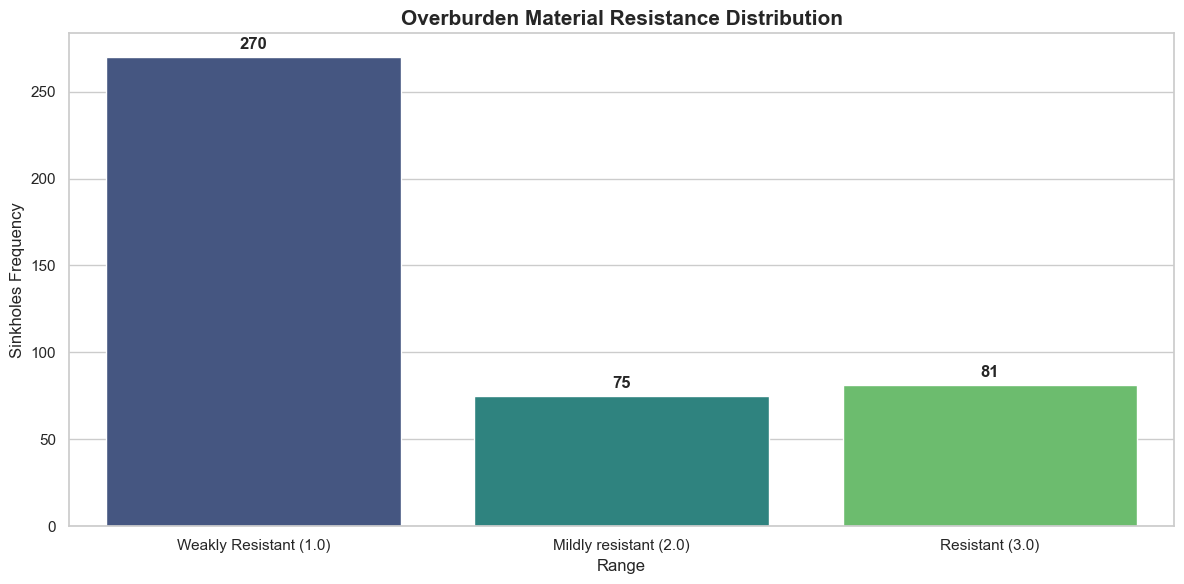


--- RESUMEN DE RESISTENCIA ---
   Resistencia  Frecuencia
0          1.0         270
1          2.0          75
2          3.0          81


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar los datos para el gráfico
# Contamos las frecuencias de cada clase de resistencia (1.0, 2.0, 3.0)
df_res_plot = df_risk['resistance_numeric'].value_counts().sort_index().reset_index()
df_res_plot.columns = ['Resistencia', 'Frecuencia']

# Mapeamos a etiquetas descriptivas para una mejor interpretación geológica
labels_map = {
    1.0: 'Weakly Resistant (1.0)',
    2.0: 'Mildly resistant (2.0)',
    3.0: 'Resistant (3.0)'
}
df_res_plot['Descripción'] = df_res_plot['Resistencia'].map(labels_map)

# 2. Crear la visualización
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Usamos 'Descripción' como hue para evitar el Future Warning
ax = sns.barplot(
    x='Descripción', 
    y='Frecuencia', 
    data=df_res_plot, 
    hue='Descripción', 
    palette='viridis', 
    legend=False
)

# Añadir etiquetas de conteo sobre las barras
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 9), 
                textcoords='offset points', fontweight='bold')

plt.title('Overburden Material Resistance Distribution', fontsize=15, fontweight='bold')
plt.ylabel('Sinkholes Frequency', fontsize=12)
plt.xlabel('Range', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Mostrar tabla de resumen
print("\n--- RESUMEN DE RESISTENCIA ---")
print(df_res_plot[['Resistencia', 'Frecuencia']])

In [14]:
df_risk["material_overbuden_resistance"].unique()

array(['weakly resistant', nan, 'powdery', 'resistant',
       'mildly resistant', 'highly resistant',
       'oderate to high resistance due to compacted layers, but water inflows were significant in early years',
       'unknown'], dtype=object)

In [15]:
# --- PASO B: Verificar la relacion entre geology_of_the_overburden y material_overburden_resistance ---

# 1. Preparamos un DataFrame temporal solo para el análisis
df_analisis = df_risk.copy()

# 2. Estandarizamos la Resistencia para agrupar el "ruido"
# Usamos el mapeo que ya verificamos antes para tener 3 grupos claros
mapa_estandar = {
    'weakly resistant': '1_BAJA',
    'powdery': '1_BAJA',
    
    'mildly resistant': '2_MEDIA',
    'moderately resistant': '2_MEDIA',
    'medium': '2_MEDIA',
    'oderate to high resistance due to compacted layers, but water inflows were significant in early years': '2_MEDIA',
    
    'resistant': '3_ALTA',
    'highly resistant': '3_ALTA'
}

# Crear nivel de resistencia cualitativa de los materiales overburden
df_analisis['nivel_resistencia'] = df_analisis['material_overbuden_resistance'].str.lower().str.strip().map(mapa_estandar)

# 3. Seleccionamos solo las filas que tienen nivel de resistencia junto con litologia para la imputacion
grupos = df_analisis.dropna(subset=['nivel_resistencia', 'geology_of_the_overburden'])

print(f"Analizando {len(grupos)} coincidencias encontradas...\n")

#Iteramos para cada nivel de resistencia y contabilizamos la frecuencia de cada nivel 
for nivel in sorted(grupos['nivel_resistencia'].unique()):
    print(f"=== ROCAS CLASIFICADAS COMO: {nivel} ===")
    # Mostramos las 15 descripciones geológicas más frecuentes en cada grupo
    top_geo = grupos[grupos['nivel_resistencia'] == nivel]['geology_of_the_overburden'].value_counts().head(15)
    print(top_geo)
    print("-" * 100 + "\n")


print(f"=== TOTAL DE ROCAS CLASIFICADAS POR: {grupos['nivel_resistencia'].value_counts().sort_index()}")

Analizando 427 coincidencias encontradas...

=== ROCAS CLASIFICADAS COMO: 1_BAJA ===
geology_of_the_overburden
Carboniferous sandstone and shale                                                                            53
Middle Stephanian - Puddingstone, clayey-silty sandstone                                                     53
Permian sandstone. Triassic clays and sandstone                                                              46
Molasse and sands                                                                                            36
Permian sandstone and shale                                                                                  32
Coalfields (conglomerates, sandstones, shales) locally topped with clayey sand of Eocene Age and alluvium    23
Labradorite then Carboniferous sandstone and shale                                                           11
Carboniferous levels with predominantly conglomeratic, sandstone or schistose facies                     

In [16]:
# ANALISIS DE PALABRAS CLAVE (ANALISIS DE FRECUENCIA)
# Vamos a ver qué palabras dominan matemáticamente en cada grupo
print("=== PALABRAS CLAVE DOMINANTES (Análisis de Frecuencia) ===")
keywords = ['sandstone', 
            'shale', 
            'clay', 
            'carboniferous', 
            'limestone', 
            'sand', 
            'coal', 
            'conglomerates'
            ]

result = []
for word in keywords:
    row = {'Keyword': word}
    for nivel in ['1_BAJA', '2_MEDIA', '3_ALTA']:
        # Filtramos el grupo
        subset = grupos[grupos['nivel_resistencia'] == nivel]
        # Contamos cuántas veces aparece la palabra en ese grupo
        count = subset['geology_of_the_overburden'].str.lower().str.contains(word).sum()
        row[nivel] = count
    result.append(row)

df_keywords = pd.DataFrame(result)
print(df_keywords)

#Conclusion: Realizar un analisis con palabras resulta un poco cimplicado porque muchas palabras se repiten en los 3 niveles de resistencia.
# Solo se puede notar que las descripciones que tengas limestone son puramente clasificadas como 3_ALTA

=== PALABRAS CLAVE DOMINANTES (Análisis de Frecuencia) ===
         Keyword  1_BAJA  2_MEDIA  3_ALTA
0      sandstone     234       76      63
1          shale     122       76      27
2           clay     122        1      25
3  carboniferous      77        0      31
4      limestone       0        0      17
5           sand     270       76      63
6           coal      23       59      11
7  conglomerates      23       75      11


In [17]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 21 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1868 non-null   object 
 1   x_wgs84                                       1868 non-null   float64
 2   y_wgs84                                       1868 non-null   float64
 3   number_of_sinkholes                           1841 non-null   object 
 4   length_diameter_m                             1724 non-null   object 
 5   depth_of_the_sinkhole_m                       1642 non-null   object 
 6   in-situ_measurement_or_estimation             1683 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object 
 8   origin_of_collapse                            1778 non-null   object 
 9   start_date_of_the_mining                      1838 non-null   o

In [18]:
df_risk["material_overbuden_resistance"].unique()

array(['weakly resistant', nan, 'powdery', 'resistant',
       'mildly resistant', 'highly resistant',
       'oderate to high resistance due to compacted layers, but water inflows were significant in early years',
       'unknown'], dtype=object)

In [19]:
# MODELO DE CLASIFICACION NO SUPERVISADA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# --- 1. PREPARACIÓN DE DATOS ---
#Creamos una copia del df_risk con geology_of_the_overburden y material_overburden_resistance
df_ml = df_risk[["id_bd_sinkhole","geology_of_the_overburden", "material_overbuden_resistance", "resistance_numeric"]].copy()

#ELiminamos las descripciones litologicas con "unknown"
df_ml = df_ml[~df_ml["geology_of_the_overburden"].str.contains('unknow', case=False, na=False)]
df_ml = df_ml.reset_index(drop=True)

# Limpieza básica del texto
df_ml['text_for_ml'] = df_ml['geology_of_the_overburden'].astype(str).str.lower().str.strip()

# Mapeamos la resistencia conocida a números para poder calcular promedios después
res_map = {
    'weakly resistant': 1,
    'powdery': 1,
    'mildly resistant': 2,
    'oderate to high resistance due to compacted layers, but water inflows were significant in early year': 2,
    'resistant': 3,
    'highly resistant': 3,
    'nan': np.nan,
    'unknown': np.nan
}

df_ml['target_res'] = df_ml['material_overbuden_resistance'].map(res_map)

# --- 2. VECTORIZACIÓN (NLP) ---
# Convertimos texto a matriz numérica.
# min_df=5: Ignora palabras que aparezcan en menos de 5 filas (quita ruido/typos)
vectorizer = TfidfVectorizer(stop_words='english', min_df=4)
X_text = vectorizer.fit_transform(df_ml['text_for_ml'])

print(f"Matriz generada: {X_text.shape} (Filas x Palabras únicas)")

# --- 3. MODELADO (K-MEANS) ---
# Probamos con 4 clusters para capturar matices (ej. Arenisca pura vs Arenisca arcillosa)
n_clusters=4
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
df_ml['cluster'] = kmeans.fit_predict(X_text)

# --- 4. ANÁLISIS DE LOS CLUSTERS ---
print(f"\n--- ANÁLISIS DE LOS {n_clusters} GRUPOS (CLUSTERS) GENERADOS ---")
print("="*70)

# Para cada cluster, calculamos la resistencia promedio de los datos que SI tienen etiqueta
cluster_profile = df_ml.groupby('cluster')['target_res'].agg(['mean', 'count', lambda x: x.isnull().sum()])
cluster_profile.columns = ['Average_Resistance', 'Known_Data', 'Missing_Data']

# Agregamos las palabras clave principales de cada cluster para entender qué son
def get_top_keywords(data, cluster_id, vectorizer, n_terms=100):
    # Obtenemos las filas del cluster
    idx = data.index[data['cluster'] == cluster_id].tolist()
    # Calculamos el promedio de sus vectores TF-IDF
    mean_tfidf = X_text[idx].mean(axis=0).A1
    # Buscamos las palabras con mayor puntaje
    terms = vectorizer.get_feature_names_out()
    sorted_indices = mean_tfidf.argsort()[::-1]
    return ", ".join([terms[i] for i in sorted_indices[:n_terms]])

cluster_profile['Keywords'] = [get_top_keywords(df_ml, i, vectorizer) for i in range(n_clusters)]
cluster_profile

Matriz generada: (1475, 53) (Filas x Palabras únicas)


c:\Users\gbenavides\AppData\Local\miniforge3\envs\sinkhole_env\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)



--- ANÁLISIS DE LOS 4 GRUPOS (CLUSTERS) GENERADOS ---


,Average_Resistance,Known_Data,Missing_Data,Keywords
cluster,,,,
0,1.000000,53,887,"carboniferous, quaternary, shale, sands, clays..."
1,1.668449,187,45,"molasse, middle, westphalian, silty, puddingst..."
2,1.869565,92,40,"shales, sandstones, coalfields, conglomerates,..."
3,1.340426,94,77,"permian, sandstone, shale, triassic, clays, ca..."


In [20]:
pd.set_option('display.max_colwidth', None)
cluster_profile

,Average_Resistance,Known_Data,Missing_Data,Keywords
cluster,,,,
0,1.000000,53,887,"carboniferous, quaternary, shale, sands, clays, sandstone, triassic, topped, westphalian, shales, siltstones, upper, silty, sandstones, schistose, sand, quartz, puddingstone, predominantly, stephanian, whesphalien, pebbles, permian, molasse, middle, locally, limestones, mezozic, marls, labradorite, keuper, iridescent, glacial, geological, fragments, limestone, levels, formation, formed, followed, facies, dolomite, deposits, eocene, dolomites, conglomerates, conglomeratic, clayey, coalfields, clay, bituminous, alluvium, age"
1,1.668449,187,45,"molasse, middle, westphalian, silty, puddingstone, stephanian, sandstone, clayey, limestone, clay, schistose, facies, levels, sands, quartz, geological, followed, formation, whesphalien, labradorite, predominantly, conglomeratic, dolomite, shale, marls, keuper, conglomerates, glacial, deposits, carboniferous, pebbles, fragments, bituminous, formed, upper, iridescent, limestones, dolomites, triassic, shales, quaternary, clays, topped, siltstones, sandstones, permian, sand, mezozic, locally, eocene, coalfields, alluvium, age"
2,1.869565,92,40,"shales, sandstones, coalfields, conglomerates, topped, locally, age, alluvium, eocene, sand, limestone, clayey, mezozic, siltstones, clays, carboniferous, triassic, stephanian, upper, westphalian, whesphalien, pebbles, permian, predominantly, puddingstone, quartz, quaternary, sands, sandstone, silty, schistose, shale, molasse, marls, middle, limestones, levels, formation, formed, fragments, geological, glacial, iridescent, keuper, labradorite, conglomeratic, deposits, dolomite, dolomites, followed, facies, clay, bituminous"
3,1.340426,94,77,"permian, sandstone, shale, triassic, clays, carboniferous, quaternary, sands, limestone, topped, upper, westphalian, whesphalien, sandstones, schistose, siltstones, sand, quartz, shales, stephanian, silty, pebbles, predominantly, puddingstone, molasse, marls, locally, mezozic, middle, labradorite, keuper, iridescent, glacial, geological, fragments, limestones, levels, formation, formed, followed, facies, dolomite, deposits, eocene, dolomites, conglomerates, conglomeratic, clayey, coalfields, clay, bituminous, alluvium, age"


In [21]:
# --- 5. IMPUTACIÓN DE VALORES FALTANTES ---

# 1. Definimos las reglas de imputacion
# Tomamos el promedio calculado, lo redondeamos al entero más cercano y lo pasamos a diccionario
reglas_imputacion = cluster_profile['Average_Resistance'].round().astype(int).to_dict()

print("--- REGLAS DE IMPUTACIÓN GENERADAS (PROMEDIO REDONDEADO) ---")
for cluster_id, valor in reglas_imputacion.items():
    print(f"Cluster {cluster_id} -> Se imputará con Nivel {valor}")

# 2. Imputamos los valores faltantes
# Tomamos la columna original y llenamos los NaN mapeando el cluster a nuestra regla calculada.
df_ml['overburden_resistance_numeric'] = df_ml['resistance_numeric'].fillna(
    df_ml['cluster'].map(reglas_imputacion)
)

# 3. Verificamos cuántos datos hemos recuperado
nulos_antes = df_ml['resistance_numeric'].isnull().sum()
nulos_ahora = df_ml['overburden_resistance_numeric'].isnull().sum()
recuperados = nulos_antes - nulos_ahora

print(f"\n--- RESULTADO DE LA IMPUTACIÓN ---")
print(f"Datos faltantes originales: {nulos_antes}")
print(f"Datos faltantes actuales:   {nulos_ahora}")
print(f"¡Se han recuperado {recuperados} registros!\n")

# 4. Mapeamos a los niveles de texto finales (1_BAJA, 2_MEDIA, 3_ALTA)
mapa_niveles = {
    1: '1_BAJA',
    2: '2_MEDIA',
    3: '3_ALTA',
}

df_ml['resistencia_imputada'] = df_ml['overburden_resistance_numeric'].map(mapa_niveles)

# 5. Resumen Final
print("=== DISTRIBUCIÓN FINAL DE RESISTENCIAS (POST-IMPUTACIÓN) ===")
print(df_ml['resistencia_imputada'].value_counts().sort_index())


--- REGLAS DE IMPUTACIÓN GENERADAS (PROMEDIO REDONDEADO) ---
Cluster 0 -> Se imputará con Nivel 1
Cluster 1 -> Se imputará con Nivel 2
Cluster 2 -> Se imputará con Nivel 2
Cluster 3 -> Se imputará con Nivel 1

--- RESULTADO DE LA IMPUTACIÓN ---
Datos faltantes originales: 1049
Datos faltantes actuales:   0
¡Se han recuperado 1049 registros!

=== DISTRIBUCIÓN FINAL DE RESISTENCIAS (POST-IMPUTACIÓN) ===
resistencia_imputada
1_BAJA     1234
2_MEDIA     160
3_ALTA       81
Name: count, dtype: int64


In [22]:
df_ml.overburden_resistance_numeric.unique()

array([1., 2., 3.])

In [23]:
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1475 non-null   object 
 1   geology_of_the_overburden      1475 non-null   object 
 2   material_overbuden_resistance  430 non-null    object 
 3   resistance_numeric             426 non-null    float64
 4   text_for_ml                    1475 non-null   object 
 5   target_res                     426 non-null    float64
 6   cluster                        1475 non-null   int32  
 7   overburden_resistance_numeric  1475 non-null   float64
 8   resistencia_imputada           1475 non-null   object 
dtypes: float64(3), int32(1), object(5)
memory usage: 98.1+ KB


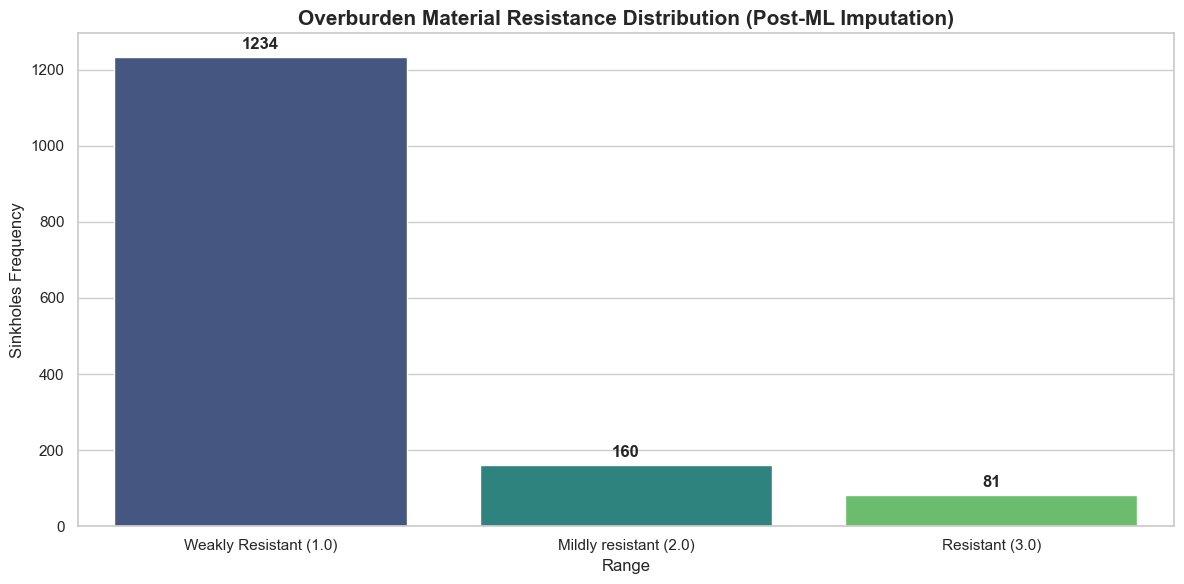


--- RESUMEN DE RESISTENCIA ---
   Resistencia  Frecuencia
0          1.0        1234
1          2.0         160
2          3.0          81


In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar los datos para el gráfico
# Contamos las frecuencias de cada clase de resistencia (1.0, 2.0, 3.0)
df_res_plot = df_ml['overburden_resistance_numeric'].value_counts().sort_index().reset_index()
df_res_plot.columns = ['Resistencia', 'Frecuencia']

# Mapeamos a etiquetas descriptivas para una mejor interpretación geológica
labels_map = {
    1.0: 'Weakly Resistant (1.0)',
    2.0: 'Mildly resistant (2.0)',
    3.0: 'Resistant (3.0)'
}
df_res_plot['Descripción'] = df_res_plot['Resistencia'].map(labels_map)

# 2. Crear la visualización
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Usamos 'Descripción' como hue para evitar el Future Warning
ax = sns.barplot(
    x='Descripción', 
    y='Frecuencia', 
    data=df_res_plot, 
    hue='Descripción', 
    palette='viridis', 
    legend=False
)

# Añadir etiquetas de conteo sobre las barras
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 9), 
                textcoords='offset points', fontweight='bold')

plt.title('Overburden Material Resistance Distribution (Post-ML Imputation)', fontsize=15, fontweight='bold')
plt.ylabel('Sinkholes Frequency', fontsize=12)
plt.xlabel('Range', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Mostrar tabla de resumen
print("\n--- RESUMEN DE RESISTENCIA ---")
print(df_res_plot[['Resistencia', 'Frecuencia']])

### 2. DEPTH OF THE DRIFT RELATIVE TO THE SURFACE

In [25]:
# CONTINUAR CON EN ANALISIS DEL RESTO DE VARIABLES QUE VAN A FORMAR PARTE DEL MODELO DE SUSCEPTIBILIDAD
# DE ACUERDO A LA PROFUNDIDAD DE LA MINA
# INCLUIR LA DENSIDAD DE SINKHOLES (hay zonas que tienen enjambres de sinkholes - verificar si hay cambios con respecto a la profundidad en los enjambres) 
# -> CREAMOS UNA VARIABLE DENSIDAD O USAR UN MODELO DE ML PARA ASIGNAR UN ID CLUSTER A CADA GRUPO

In [26]:
df_risk["depth_of_the_drift_relative_to_the_surface_m"].unique()

array(['<40', '>50', 25, 12.5, 's.o.', 15, '<10', 20, 'unknown', '25-50',
       '<50', 100, '> 50', 10, 40, 37, 5, 'so', nan, 1, 37.5, 0, 3, 2.5,
       11, '<5', '<25', '< 30', '30-50', '30-51', '< 5 m', '<10 m',
       '< 15 m', ' 20 m', '< 10 m', '10 m', '< 40m', '16 m', '<30 m',
       '15 to 30', '<15', '30-40', '20 - 50', '0-20', '<20', '<18',
       '15-20', '<33', 'up to 760 m ', '50 - 200 m',
       'early drifts shallow up to 50 m, deeper reached 300-350 m ', 90,
       93, 42, 97, 46, 30, 35, 45, 163, 50, 21, 22, 55, 60, 70, 57, 135,
       125, 95, 240, 220, 210, 85, 75, 65, 80, 145, 105, 16, 115, 120,
       130, 205, 150, 165, 160, 170, 190, 180, 175, 116, 187, 185, 252,
       47, 41, 38, 33, 44, 36, 32, 28, 24, 39, 92, 67, 128, 9, 76, 14, 17,
       23, 54, 68, 6, 26, 8, 12, 18, 82, 13, 52, 110, 7, 53, 14.5, 2, 225,
       58, 34, 19, 330, 43, 48, 'Open pit mine', 83, 73, 59, 10.5],
      dtype=object)

In [27]:
import re
import numpy as np

def parse_depth(text):
    text = str(text).lower().strip()
    
    # 1. Manejo de nulos y desconocidos
    if text in ['nan', 'unknown', 's.o.', 'so', '?']:
        return np.nan
    if 'open pit' in text:
        return 0.0

    # 2. Manejo de Rangos (ej. '25-50' o '25 to 50')
    range_match = re.findall(r'(\d+\.?\d*)\s*(?:-|to)\s*(\d+\.?\d*)', text)
    if range_match:
        val1, val2 = map(float, range_match[0])
        return (val1 + val2) / 2

    # 3. Manejo de Operadores (ej. '<40', '>50', 'up to 50')
    # Extraemos el primer número que aparezca
    numbers = re.findall(r'(\d+\.?\d*)', text)
    if numbers:
        return float(numbers[0])

    return np.nan

# Aplicar la limpieza
df_risk['depth_drift_clean'] = df_risk['depth_of_the_drift_relative_to_the_surface_m'].apply(parse_depth)

In [28]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 22 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1868 non-null   object 
 1   x_wgs84                                       1868 non-null   float64
 2   y_wgs84                                       1868 non-null   float64
 3   number_of_sinkholes                           1841 non-null   object 
 4   length_diameter_m                             1724 non-null   object 
 5   depth_of_the_sinkhole_m                       1642 non-null   object 
 6   in-situ_measurement_or_estimation             1683 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object 
 8   origin_of_collapse                            1778 non-null   object 
 9   start_date_of_the_mining                      1838 non-null   o

In [29]:
df_clean.y_wgs84.unique()

array([45.61004286, 45.61094363, 45.61100164, ..., 50.2535448 ,
       50.25979883, 50.22644365], shape=(1820,))

### VISUALIZACION DE DENSIDAD DE SINKHOLES

In [30]:
import folium
from folium.plugins import HeatMap, MarkerCluster

# 1. Crear el mapa base centrado en el promedio de tus coordenadas
# Cualquier texto que no sea un número se convertirá en NaN
df_risk['y_wgs84'] = pd.to_numeric(df_risk['y_wgs84'], errors='coerce')
df_risk['x_wgs84'] = pd.to_numeric(df_risk['x_wgs84'], errors='coerce')

mapa_sinkholes = folium.Map(
    location=[df_risk['y_wgs84'].mean(), df_risk['x_wgs84'].mean()], 
    zoom_start=12,
    tiles='CartoDB positron'
)

# 2. Opción A: Marcadores Agrupados (MarkerCluster)
# Esto agrupa los puntos automáticamente (verás círculos con números como "73", "49", etc.)
marker_cluster = MarkerCluster(name="Agrupación de Sinkholes").add_to(mapa_sinkholes)

for idx, row in df_risk.iterrows():
    if not np.isnan(row['y_wgs84']) and not np.isnan(row['x_wgs84']):
        folium.CircleMarker(
            location=[row['y_wgs84'], row['x_wgs84']],
            radius=3,
            color='red',
            fill=True,
            fill_color='red',
            # Añadimos información al hacer click (tu variable limpia de profundidad)
            popup=f"ID: {row['id_bd_sinkhole']} <br> Depth of the drift: {row['depth_drift_clean']}m <br> Working thickness: {row['working_thickness_shaft_deep']}"
        ).add_to(marker_cluster)

# 3. Opción B: Mapa de Calor (HeatMap)
# Esto cumple con la parte de "análisis probabilístico" mostrando zonas de mayor ocurrencia
heat_data = [[row['y_wgs84'], row['x_wgs84']] for idx, row in df_risk.iterrows() if not np.isnan(row['y_wgs84'])]
HeatMap(heat_data, name="Mapa de Calor (Densidad)", radius=15, blur=10).add_to(mapa_sinkholes)

# Añadir control de capas para encender/apagar el mapa de calor
folium.LayerControl().add_to(mapa_sinkholes)

# Guardar y mostrar
mapa_sinkholes.save('mapa_sinkholes_lille.html')

### 3. PROFUNDIDAD DE GALERIA

In [31]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 22 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1868 non-null   object 
 1   x_wgs84                                       1868 non-null   float64
 2   y_wgs84                                       1868 non-null   float64
 3   number_of_sinkholes                           1841 non-null   object 
 4   length_diameter_m                             1724 non-null   object 
 5   depth_of_the_sinkhole_m                       1642 non-null   object 
 6   in-situ_measurement_or_estimation             1683 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object 
 8   origin_of_collapse                            1778 non-null   object 
 9   start_date_of_the_mining                      1838 non-null   o

In [32]:
# ANALISIS DE OCURRENCIA CON LA PRODUNDIDAD DE GALERIA
# Hay que tomar en cuenta que NO estamos tomando en cuenta el sesgo estadistico potencial debido a dos aspectos importantes:
# 1. Sesgo observacional (venta de observacion - completitud del catalogo). Es mas probable que un sinkhole somero (30m) sea detectado que uno de 200 m + eventos en minas antiguas (<30m) no tienen registros oficiales + 
# en mineas profundas es menos probable que se evidencie en superficie (factor de esponjamiento)
# 2. Sesgo por tecnicas de explotacion. La mineria somera es historicamente la mas facil de explotar historicamente y probablemente se usaban metodos menos tecnificados? 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Definimos los rangos (bins) basados en criterios geotécnicos comunes
# 0-15m: Muy somero (Crítico)
# 15-30m: Somero (Alto)
# 30-60m: Media profundidad (Moderado)
# >60m: Profundo (Bajo)
bins = [0, 15, 30, 60, 1000]
labels = ['Very Shallow (0-15m)', 'Shallow (15-30m)', 'Intermediate (30-60m)', 'Deep (>60m)']

# 2. Categorizamos los datos limpios de profundidad
df_risk['depth_range'] = pd.cut(df_risk['depth_drift_clean'], bins=bins, labels=labels)

# 3. Cálculo de la Probabilidad de Frecuencia (P_f)
# Calculamos cuántos sinkholes hay en cada rango y lo normalizamos de 0 a 1
frecuencia_counts = df_risk['depth_range'].value_counts().sort_index()

# Creamos un DataFrame de referencia para los pesos
tabla_pesos_profundidad = frecuencia_counts.reset_index()
tabla_pesos_profundidad.columns = ['Rango_Profundidad', 'Frecuencia']

# Normalizamos el peso para que el rango más peligroso sea 1.0 (Puntaje de Susceptibilidad)
max_freq = tabla_pesos_profundidad['Frecuencia'].max()
tabla_pesos_profundidad['Susceptibility_Score'] = (tabla_pesos_profundidad['Frecuencia'] / max_freq).round(2)

print("--- Tabla de Susceptibilidad por Profundidad ---")
print(tabla_pesos_profundidad)

--- Tabla de Susceptibilidad por Profundidad ---
       Rango_Profundidad  Frecuencia  Susceptibility_Score
0   Very Shallow (0-15m)         234                  0.38
1       Shallow (15-30m)         271                  0.44
2  Intermediate (30-60m)         615                  1.00
3            Deep (>60m)         178                  0.29


In [33]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 23 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   id_bd_sinkhole                                1868 non-null   object  
 1   x_wgs84                                       1868 non-null   float64 
 2   y_wgs84                                       1868 non-null   float64 
 3   number_of_sinkholes                           1841 non-null   object  
 4   length_diameter_m                             1724 non-null   object  
 5   depth_of_the_sinkhole_m                       1642 non-null   object  
 6   in-situ_measurement_or_estimation             1683 non-null   object  
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object  
 8   origin_of_collapse                            1778 non-null   object  
 9   start_date_of_the_mining                      1838 n

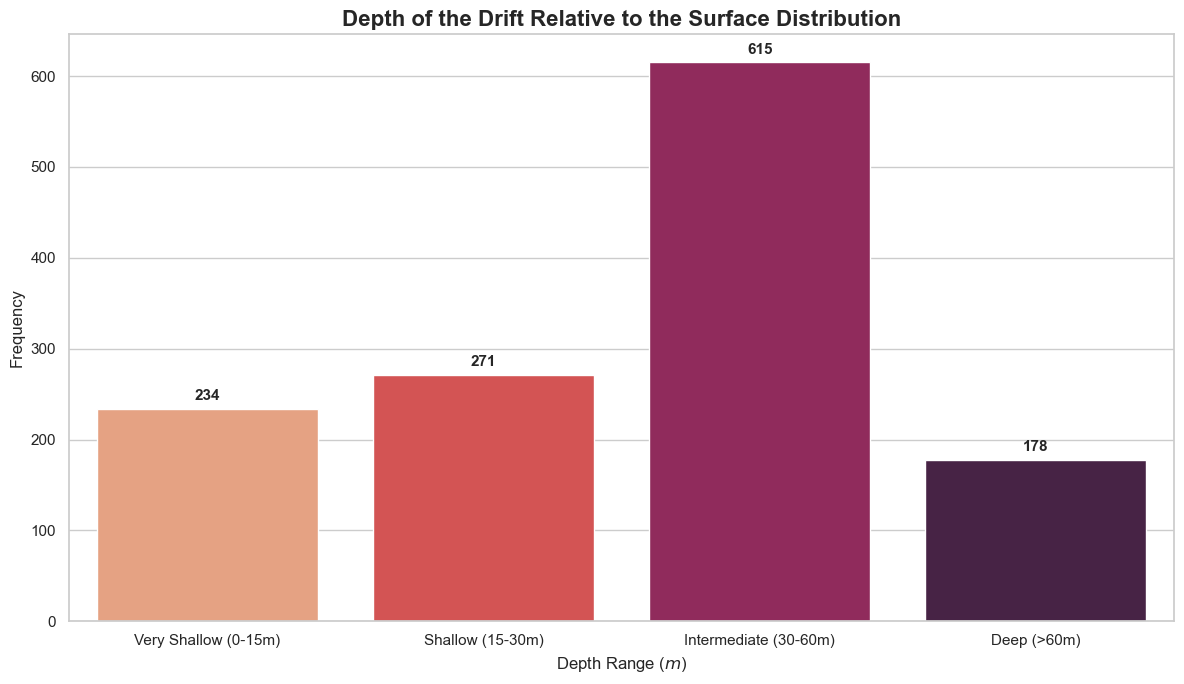

In [34]:
# Graficar la frecuencia de profundidades

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df_plot = pd.DataFrame(tabla_pesos_profundidad)

# Set the style
sns.set_theme(style="whitegrid")

# Create the figure
plt.figure(figsize=(12, 7))

# Plotting Normalized Frequency (Peso Probabilistico)
# Using a color palette that emphasizes depth/severity

ax = sns.barplot(
    x='Rango_Profundidad', 
    y='Frecuencia', 
    data=df_plot,
    hue = "Rango_Profundidad",
    palette= "rocket_r",
    legend = False)

# Add title and labels
plt.title('Depth of the Drift Relative to the Surface Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Depth Range ($m$)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Add values on top of bars
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points',
                   fontsize=11, fontweight='bold')

#plt.ylim(0, 0.55)
plt.tight_layout()
plt.show()

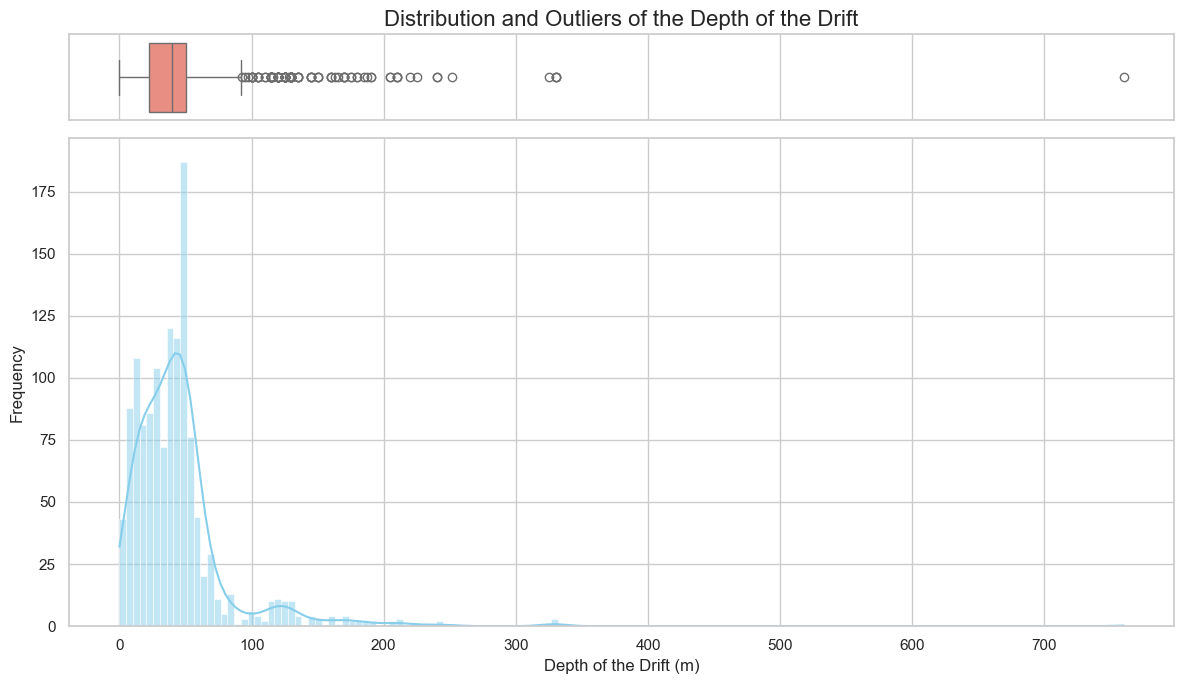

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo profesional
sns.set_theme(style="whitegrid")

# Crear una figura con dos subplots: Histograma y Boxplot
# El boxplot ayuda a identificar visualmente los valores atípicos como el 760
fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, 
                                      gridspec_kw={"height_ratios": (.15, .85)}, 
                                      figsize=(12, 7))

# 1. Boxplot (Diagrama de caja)
sns.boxplot(data=df_risk, x="depth_drift_clean", ax=ax_box, color="salmon")
ax_box.set(xlabel='') # Eliminar etiqueta del eje X para el boxplot
ax_box.set_title('Distribution and Outliers of the Depth of the Drift', fontsize=16)

# 2. Histograma con curva de densidad (KDE)
sns.histplot(data=df_risk, x="depth_drift_clean", kde=True, ax=ax_hist, color="skyblue")
ax_hist.set_xlabel('Depth of the Drift (m)', fontsize=12)
ax_hist.set_ylabel('Frequency', fontsize=12)

# Ajustar diseño
plt.tight_layout()

### 2. ANALISIS DE WORKING THICKNESS

In [36]:
df_risk["working_thickness_shaft_deep"].unique()

array(['2 to 3 m', nan, '2 - 2,5', 2.5, 43, 2, '1,8 to 3,5', '< 2 m', 1,
       3, 20, '1,7', 100, 50, 45, 40, 36, '<1,5', 19, 47, 81, 15, 48, 95,
       85, 157, 1.7, '1 to 2', 94, 170, 'up to 730 m ', 'up to 339 m',
       'shaft depth: 162 m and tunnel length: 5 km', '234 m (in 1922)',
       'working seams: 1-3 m, shaft depth up tp 344 m ', 'unknown',
       'deepest reached -810 m above sea level', 'max. 606 m', 4, 3.9,
       5.5, 4.2, 4.7, 2.6, 2.65, 2.2, 2.3, 2.8, 4.9, 1.5, 1.8, 5, 3.8,
       2.9, 4.6, 6, 2.25, 2.7, 5.8, 1.4, 80, 4.8, 4.1, 37, 10, 1.6, 3.6,
       3.3, 23, 44, 3.1, 3.5, 8, 1.9, 1.85, 2.4, 3.2, 2.1, 3.4, 1.75, 38,
       1.3, 1.65, 3.15, 28.7, 1.2, 19.5, 0.8, '1,6-2,0', '1,7-2,0', 16,
       7.2, 7.5, 7, 59, 30], dtype=object)

In [37]:
import re
import numpy as np

#1. LIMPIEZA INICIAL

def clean_working_thickness(val):
    # Convertir a minúsculas y quitar espacios
    val = str(val).lower().strip()
    
    # 1. Manejo de nulos y desconocidos
    if val in ['nan', 'unknown', 's.o.', 'so', '?', 'none']:
        return np.nan

    # 2. Manejo de Rangos (ej. '1.5-2.0', '1.5 to 2', '1,5 - 2')
    # Reemplazamos coma por punto para estandarizar decimales
    val = val.replace(',', '.')
    range_match = re.findall(r'(\d+\.?\d*)\s*(?:-|to)\s*(\d+\.?\d*)', val)
    if range_match:
        v1, v2 = map(float, range_match[0])
        return (v1 + v2) / 2

    # 3. Manejo de prefijos y sufijos (ej. '< 2m', '> 1.5', '2 mts')
    # Buscamos todos los números con decimales
    numbers = re.findall(r'(\d+\.?\d*)', val)
    if numbers:
        # Si hay varios números y no era un rango, tomamos el primero
        # (Suele ser el valor principal en descripciones tipo '2m deep')
        return float(numbers[0])

    return np.nan

# Aplicar la limpieza al DataFrame
df_risk['working_thickness_numeric'] = df_risk['working_thickness_shaft_deep'].apply(clean_working_thickness)

# Estadísticas descriptivas básicas para detectar errores (Outliers)
print("\n--- Statistical Description ---")
print(df_risk['working_thickness_numeric'].describe())


--- Statistical Description ---
count    1175.000000
mean       22.816170
std       118.159155
min         0.800000
25%         2.000000
50%         3.000000
75%         4.000000
max       810.000000
Name: working_thickness_numeric, dtype: float64


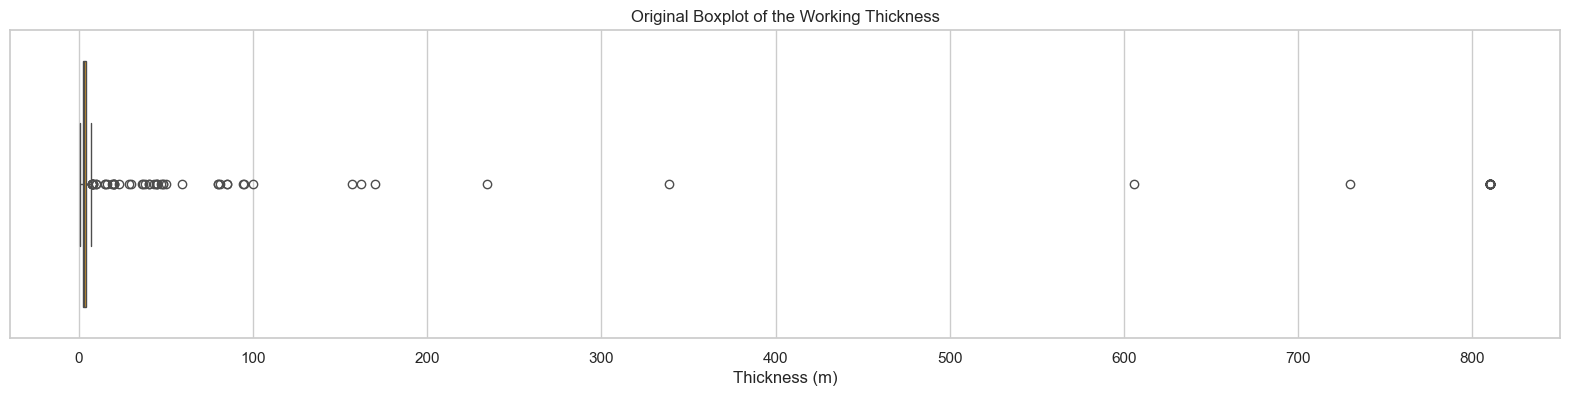

In [38]:
# 2. VISUALIZAR DISTRIBUCION
# VERIFICAR QUE HAY VALORES QUE SON PROFUNDIDADES Y NO THICKNESS

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Visualización de Outliers (Boxplot)
plt.figure(figsize=(20, 4))
sns.boxplot(x=df_risk['working_thickness_numeric'].dropna(), color='orange')
plt.title('Original Boxplot of the Working Thickness')
plt.xlabel('Thickness (m)')
plt.show()


In [39]:
# 3. VALORES SOSPECHOSOS

# Listado de Valores Sospechosos (> 5m)
# El límite de 5m es un buen punto de corte para vetas de carbón europeas (working_thickness)
threshold = 5.0
suspect_values = df_risk[df_risk['working_thickness_numeric'] >= threshold]

print(f"\n--- Análisis de Valores Mayores a {threshold} m ---")
print(f"Cantidad de valores sospechosos: {len(suspect_values)}")
cols_to_show = ['depth_drift_clean', 'working_thickness_numeric']
# Mostramos también la profundidad para ver si hay correlación
print(suspect_values[cols_to_show].sort_values(by='working_thickness_numeric', ascending=False))


--- Análisis de Valores Mayores a 5.0 m ---
Cantidad de valores sospechosos: 107
      depth_drift_clean  working_thickness_numeric
731                 NaN                      810.0
732                 NaN                      810.0
733                 NaN                      810.0
734                 NaN                      810.0
735                 NaN                      810.0
...                 ...                        ...
1822               40.0                        5.0
1838               60.0                        5.0
1858               30.0                        5.0
1859               43.0                        5.0
1863               60.0                        5.0

[107 rows x 2 columns]


Podemos ver que hay valores muy altos de working_thickness_numeric que son anomalos. Ya que un espesor de capa de carbon de 162m es imposible. Por otro lado podemos ver que existen capas de 5m a profundidades de >100 m. Mientras que existen observaciones donde la profundidad es igual al espesor de capa (Tiene sentido esto? - Son explotaciones a cielo abierto? - Esta mal llenada la informacion). Yo me inclino a que no se entendio bien como habia que llenar la informacion y hubo un mal llenado de la informacion.

In [40]:
# 4. LIMPIEZA DE VALORES CON PROFUNDIDA Y ESPESOR IGUAL O APROXIMADAMENTE IGUAL
 
# 1. Definimos la lógica de error
# Si el espesor es "sospechosamente grande" (> 5m) Y se parece a la profundidad
# (Usamos una tolerancia de 2m para la imputacion)
def is_data_error(row):
    th = row['working_thickness_numeric']
    dp = row['depth_drift_clean']
    
    if pd.isna(th) or pd.isna(dp):
        return False
        
    # Tu criterio: Valores grandes donde Thickness ≈ Depth
    if th >= 5 and abs(th - dp) < 2.0: 
        return True
        
    return False

# Creamos una copia del df original para evaluar diferencias
df_risk_prof_espesor = df_risk.copy()

# 2. Identificamos los errores
errores_mask = df_risk_prof_espesor.apply(is_data_error, axis=1)
print(f"Detectados {errores_mask.sum()} registros donde Espesor ≈ Profundidad.")

# Visualizamos algunos antes de borrarlos para estar seguros
if errores_mask.sum() > 0:
    print(df_risk_prof_espesor.loc[errores_mask, ["id_bd_sinkhole",'working_thickness_numeric', 'depth_drift_clean']].head())

# 3. CORRECCIÓN: Convertimos esos espesores erróneos a NaN
df_risk_prof_espesor.loc[errores_mask, 'working_thickness_numeric'] = np.nan


Detectados 24 registros donde Espesor ≈ Profundidad.
     id_bd_sinkhole  working_thickness_numeric  depth_drift_clean
339      FR-SIN-347                       36.0               35.0
1420   POL-SIN- 519                       80.0               80.0
1421   POL-SIN- 520                       80.0               80.0
1458   POL-SIN- 557                       37.0               37.0
1459   POL-SIN- 558                       10.0                9.0


In [41]:
df_risk_prof_espesor[df_risk_prof_espesor["id_bd_sinkhole"] == "FR-SIN-347"]

,id_bd_sinkhole,x_wgs84,y_wgs84,number_of_sinkholes,length_diameter_m,depth_of_the_sinkhole_m,in-situ_measurement_or_estimation,date_of_appearance_of_the_sinkhole,origin_of_collapse,start_date_of_the_mining,...,depth_of_the_drift_relative_to_the_surface_m,material_overbuden_resistance,geology_of_the_overburden,presence_of_buildings_or_infrastructure,geo_clean,res_clean,resistance_numeric,depth_drift_clean,depth_range,working_thickness_numeric
339,FR-SIN-347,6.48721,47.596997,1,2.5,1.5,In-situ measurement,Unknown,Collapse of the shaft filling material,1827,...,20 - 50,resistant,Iridescent clay marls and dolomite of Middle Keuper and marls and dolomite of Upper Keuper,no,iridescent clay marls and dolomite of middle keuper and marls and dolomite of upper keuper,resistant,3.0,35.0,Intermediate (30-60m),NaN


In [42]:
# 5. IMPUTACION DE VALORES NULOS EN depth_drift_clean CON VALORES ALTOS DE working_thickness

# 1. Definimos la máscara para los valores con profundidades anomalas
mask_transposicion = df_risk_prof_espesor['working_thickness_numeric'] >= 8.0

# 2. Imputamos en depth_drift_numeric SOLO donde sea nulo
df_risk_prof_espesor.loc[mask_transposicion, 'depth_drift_clean'] = \
    df_risk_prof_espesor.loc[mask_transposicion, 'depth_drift_clean'].fillna(df_risk_prof_espesor['working_thickness_numeric'])

# 3. Limpiamos la columna de espesor 
# Ahora que ya rescatamos el dato, lo borramos de thickness para que no ensucie el análisis posterior
df_risk_prof_espesor.loc[mask_transposicion, 'working_thickness_numeric'] = np.nan

# --- Verificación de la operación ---
print(f"Registros corregidos: {mask_transposicion.sum()}")
print(f"Valores nulos actuales en profundidad: {df_risk_prof_espesor['depth_drift_clean'].isnull().sum()}")
print(f"Máximo espesor tras la limpieza: {df_risk_prof_espesor['working_thickness_numeric'].max()} m")

Registros corregidos: 49
Valores nulos actuales en profundidad: 529
Máximo espesor tras la limpieza: 7.5 m


In [43]:
df_risk_prof_espesor.iloc[:,5:].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 19 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   depth_of_the_sinkhole_m                       1642 non-null   object  
 1   in-situ_measurement_or_estimation             1683 non-null   object  
 2   date_of_appearance_of_the_sinkhole            1867 non-null   object  
 3   origin_of_collapse                            1778 non-null   object  
 4   start_date_of_the_mining                      1838 non-null   object  
 5   end_date_of_the_mining                        1858 non-null   object  
 6   dip_of_the_exploited_layer_degree             1664 non-null   object  
 7   type_of_mining_work_shaft_cavity-drift        1825 non-null   object  
 8   working_thickness_shaft_deep                  1542 non-null   object  
 9   depth_of_the_drift_relative_to_the_surface_m  1708 n

In [44]:
df_risk_prof_espesor.tail()

,id_bd_sinkhole,x_wgs84,y_wgs84,number_of_sinkholes,length_diameter_m,depth_of_the_sinkhole_m,in-situ_measurement_or_estimation,date_of_appearance_of_the_sinkhole,origin_of_collapse,start_date_of_the_mining,...,depth_of_the_drift_relative_to_the_surface_m,material_overbuden_resistance,geology_of_the_overburden,presence_of_buildings_or_infrastructure,geo_clean,res_clean,resistance_numeric,depth_drift_clean,depth_range,working_thickness_numeric
1863,POL-SIN-962,19.170597,50.260066,9,5,1.5,In situ measurement,1994-04-11 00:00:00,Faillure of the roof room or roof gallery,1833,...,60,NaN,"Carboniferous sandstone and shale, quaternary sands and clays",no,"carboniferous sandstone and shale, quaternary sands and clays",nan,NaN,60.0,Intermediate (30-60m),5.0
1864,POL-SIN-963,19.154009,50.229036,2,1.2,2.5,In situ measurement,1994-04-12 00:00:00,Faillure of the roof room or roof gallery,1833,...,10,NaN,"Carboniferous sandstone and shale, quaternary sands and clays",yes,"carboniferous sandstone and shale, quaternary sands and clays",nan,NaN,10.0,Very Shallow (0-15m),3.0
1865,POL-SIN-964,19.167440,50.253545,3,1.2,1.5,In situ measurement,1994-06-20 00:00:00,Faillure of the roof room or roof gallery,1833,...,10,NaN,"Carboniferous sandstone and shale, quaternary sands and clays",no,"carboniferous sandstone and shale, quaternary sands and clays",nan,NaN,10.0,Very Shallow (0-15m),1.6
1866,POL-SIN-965,19.182348,50.259799,4,1,1.5,In situ measurement,1999-04-07 00:00:00,Faillure of the roof room or roof gallery,1833,...,30,NaN,"Carboniferous sandstone and shale, quaternary sands and clays",no,"carboniferous sandstone and shale, quaternary sands and clays",nan,NaN,30.0,Shallow (15-30m),1.5
1867,POL-SIN-966,19.150139,50.226444,6,0.2,1,In situ measurement,2000-04-06 00:00:00,Faillure of the roof room or roof gallery,1833,...,25,NaN,"Carboniferous sandstone and shale, quaternary sands and clays",no,"carboniferous sandstone and shale, quaternary sands and clays",nan,NaN,25.0,Shallow (15-30m),1.3


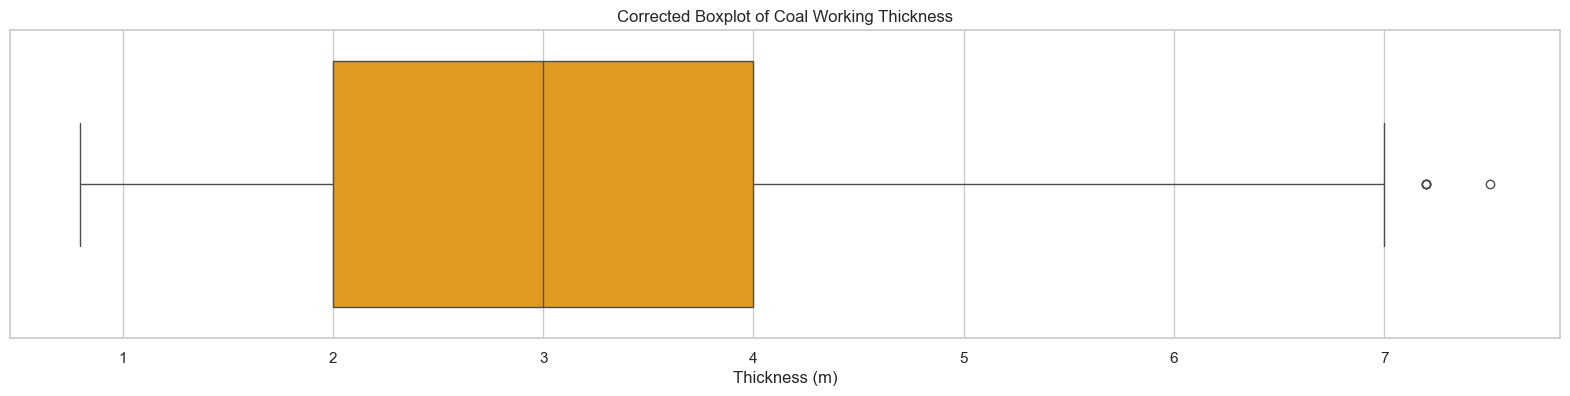

In [45]:
# 6 VISUALIZACION DE DISTRIBUCION POST IMPUTACION Y LIMPIEZA

plt.figure(figsize=(20, 4))
sns.boxplot(x=df_risk_prof_espesor['working_thickness_numeric'].dropna(), color='orange')
plt.title('Corrected Boxplot of Coal Working Thickness')
plt.xlabel('Thickness (m)')
plt.show()


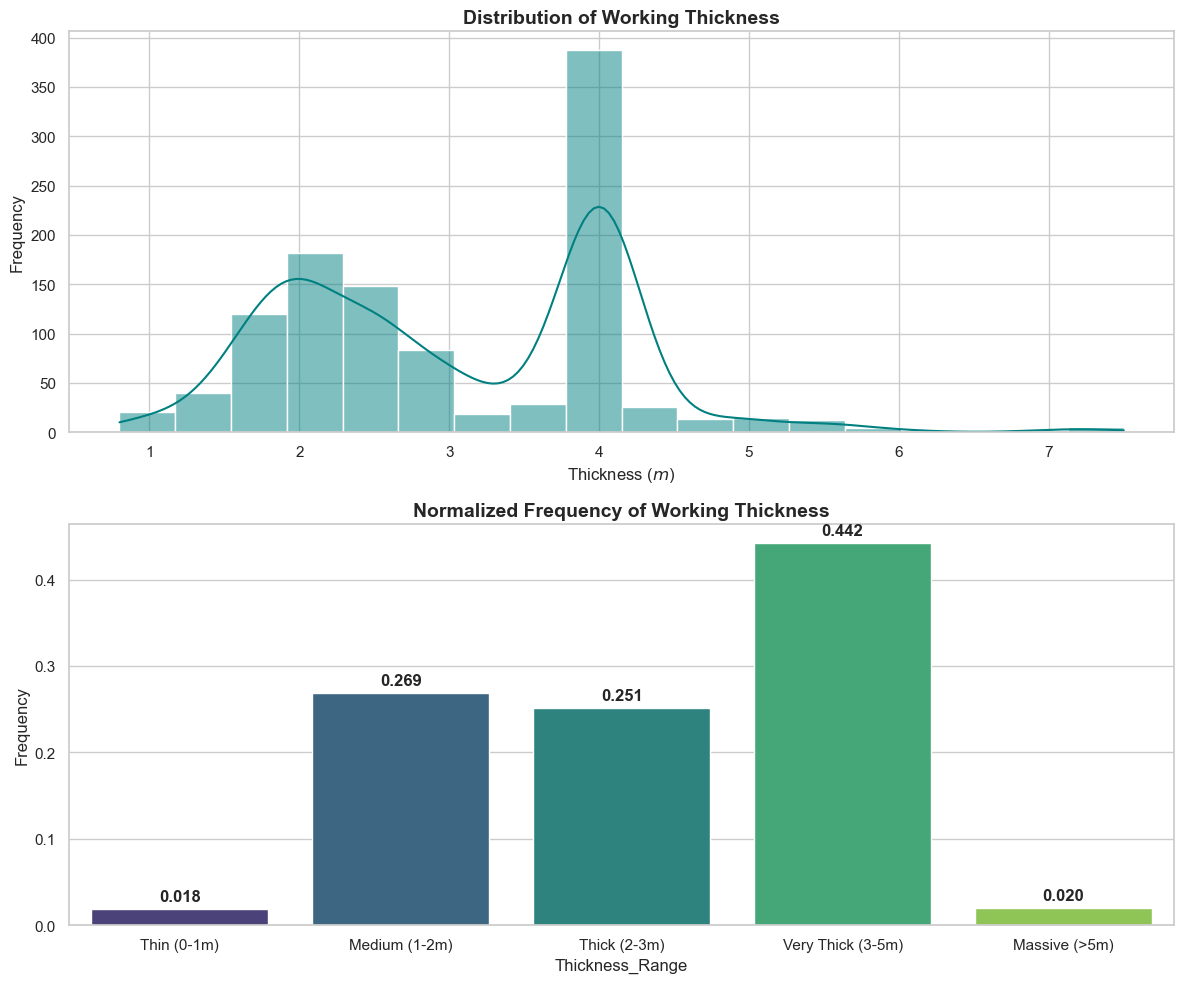


--- TABLA DE SUSCEPTIBILIDAD POR ESPESOR ---
     Thickness_Range  Frecuencia
0        Thin (0-1m)    0.018149
1      Medium (1-2m)    0.268603
2       Thick (2-3m)    0.251361
3  Very Thick (3-5m)    0.441924
4      Massive (>5m)    0.019964


In [46]:
# 7. VISUALIZACION DE DISTRIBUCION DE WORKING THICKNESS

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Configuración de estilo
sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# --- GRÁFICO 1: DISTRIBUCIÓN CONTINUA (KDE + Histogram) ---
sns.histplot(df_risk_prof_espesor['working_thickness_numeric'].dropna(), kde=True, color='teal', ax=ax1)
ax1.set_title('Distribution of Working Thickness', fontsize=14, fontweight='bold')
ax1.set_xlabel('Thickness ($m$)')
ax1.set_ylabel('Frequency')

# --- GRÁFICO 2: PESOS PROBABILÍSTICOS POR RANGOS ---
# Recalculamos los rangos con los datos limpios
bins_thick = [0, 1, 2, 3, 5, 10] # Ajustamos el máximo a 10m tras la limpieza
labels_thick = ['Thin (0-1m)', 'Medium (1-2m)', 'Thick (2-3m)', 'Very Thick (3-5m)', 'Massive (>5m)']

df_risk_prof_espesor['thickness_range'] = pd.cut(df_risk_prof_espesor['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

# Calculamos la tabla de pesos
tabla_pesos_espesor = df_risk_prof_espesor['thickness_range'].value_counts(normalize=True).sort_index().reset_index()
tabla_pesos_espesor.columns = ['Thickness_Range', 'Frecuencia']

# Graficamos
sns.barplot(
    x='Thickness_Range', 
    y='Frecuencia', 
    data=tabla_pesos_espesor, 
    hue='Thickness_Range', 
    palette="viridis", 
    ax=ax2, 
    legend=False
)

# Añadimos etiquetas de valor
for p in ax2.patches:
    ax2.annotate(format(p.get_height(), '.3f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontweight='bold')

ax2.set_title('Normalized Frequency of Working Thickness', fontsize=14, fontweight='bold')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Mostramos la tabla para tu reporte
print("\n--- TABLA DE SUSCEPTIBILIDAD POR ESPESOR ---")
print(tabla_pesos_espesor)


### **RESUMEN**
De aqui se puede complicar el estudio realizando un analisis geoespacial de los puntos de cada sinkhole (se puede crear una variable adicional llamada densidad de sinkhole). Pero en este caso vamos a realizar directamente el MODELO DE SUSCEPTIBILIDAD para analizar resultados. Este modelo se va a realizar con las 3 variables analizadas previamente: resistencia de material (overburden_resistance_numeric), profundidad de galeria (depth_of_the_dritft_relative_to_the_surface) y espesor de capa (working_thickness_numeric)

Las variables de interes para el analisis de susceptibilidad son:

- overburden_resistance_numeric
- working_thickness_numeric
- depth_drift_clean

Podemos notar que las variables de interes no tienen una completitud en cada fila. Por lo tanto, es necesario realizar una imputacion para rellenar los datos faltantes a partir de un analisis a partir del analisis geologico previo. Esto es, utilizar el analisis de cluster geologico realizado anteriormente para rellenar los datos faltantes

# IMPUTACION EN VARIABLES DEL MODELO POR DISTANCIAS ENTRE VECINOS

In [47]:
# UNION DE DATAFRAMES GENERADOS ANTERIORMENTE (df_risk_prof_espesor y df_ml)
# Incluir variable overburden_resistance_numeric al df final
df_risk_completo = df_risk_prof_espesor.merge(
    df_ml[['id_bd_sinkhole', 'overburden_resistance_numeric']], 
    on='id_bd_sinkhole', 
    how='left'
)

In [48]:
# Antes de realizar la imputacion, tomamos un subset del df_risk_completo con solo las variables de interes:

variables_interes = ["id_bd_sinkhole",
                     "x_wgs84",
                     "y_wgs84",
                        "overburden_resistance_numeric",
                        "depth_drift_clean",
                        "working_thickness_numeric"]

df_susceptibilidad = df_risk_completo[variables_interes].copy()

In [49]:
# Podemos notar que las variables para el modelo tienen "huecos" entre si. Si fuera una matriz de las 3 variables predictoras existieran valores NaN entre si. Por lo tanto la imputacion es necesaria
df_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1868 non-null   object 
 1   x_wgs84                        1868 non-null   float64
 2   y_wgs84                        1868 non-null   float64
 3   overburden_resistance_numeric  1475 non-null   float64
 4   depth_drift_clean              1339 non-null   float64
 5   working_thickness_numeric      1102 non-null   float64
dtypes: float64(5), object(1)
memory usage: 87.7+ KB


Debido a que las capas de carbon y la geologia TIENEN UNA CORRELACION ESPACIAL, se decide realizar una imputacion espacial de los datos faltantes. (TOMAR EN CUENTA EL BUZAMIENTO PARA ESTE ANALISIS. Si es un buzamiento alto, va a ver una variacion mayor con depth_drift_clean)

Para implementar esto, utilizaremos el KNNImputer (K-Nearest Neighbors) de scikit-learn. Este algoritmo buscará los $k$ registros más cercanos geográficamente y promediará sus valores para rellenar el hueco.

In [50]:
# 1. Definimos las variables críticas para el modelo
variables_modelo = [
    'overburden_resistance_numeric', 
    'depth_drift_clean', 
    'working_thickness_numeric'
]

# 2. Eliminamos filas donde TODAS las variables del modelo sean NaN
# El parámetro 'how="all"' asegura que solo borramos si no hay ningún dato útil.
df_susceptibilidad_clean = df_susceptibilidad.dropna(subset=variables_modelo, how='all').copy()

n_eliminados = len(df_susceptibilidad) - len(df_susceptibilidad_clean)
print(f"Se eliminaron {n_eliminados} registros por no tener ningún dato en las variables del modelo.")

Se eliminaron 367 registros por no tener ningún dato en las variables del modelo.


In [51]:
# Este DF tiene filas donde existe al menos un valor duro de las 3 variables de interes
df_susceptibilidad_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1501 non-null   object 
 1   x_wgs84                        1501 non-null   float64
 2   y_wgs84                        1501 non-null   float64
 3   overburden_resistance_numeric  1475 non-null   float64
 4   depth_drift_clean              1339 non-null   float64
 5   working_thickness_numeric      1102 non-null   float64
dtypes: float64(5), object(1)
memory usage: 82.1+ KB


Para la transformacion a coordenadas UTM, el estándar de la Unión Europea es utilizar la proyección ETRS89-LAEA (Lambert Azimuthal Equal Area), conocida por su código EPSG:3035

In [52]:
# MEDIR LAS DISTANCIAS DE IMPUTACION
# 1. Transformar coordenadas geograficas a UTM

from pyproj import Transformer

# Creamos el transformador de WGS84 (4326) a ETRS89-LAEA (3035)
# Nota: pyproj usa (lat, lon) o (y, x) según el estándar
transformer = Transformer.from_crs("epsg:4326", "epsg:3035", always_xy=True)

# 2. Convertimos las coordenadas a metros europeos
# x_wgs84 es longitud, y_wgs84 es latitud
df_susceptibilidad_clean['x_laea'], df_susceptibilidad_clean['y_laea'] = transformer.transform(
    df_susceptibilidad_clean['x_wgs84'].values, 
    df_susceptibilidad_clean['y_wgs84'].values
)

In [53]:
df_susceptibilidad_clean.head()

,id_bd_sinkhole,x_wgs84,y_wgs84,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_laea,y_laea
0,FR-SIN-08,2.558499,45.610043,1.0,40.0,2.5,3.740790e+06,2.528731e+06
1,FR-SIN-09,2.558569,45.610944,1.0,40.0,2.5,3.740805e+06,2.528830e+06
2,FR-SIN-10,2.561892,45.611002,1.0,50.0,2.5,3.741064e+06,2.528811e+06
3,FR-SIN-11,2.554737,45.605589,1.0,50.0,2.5,3.740451e+06,2.528268e+06
4,FR-SIN-12,2.556017,45.606026,1.0,25.0,2.5,3.740555e+06,2.528307e+06


In [54]:
# 3. (OPCION 2) Realizamos la Imputacion con KNNImputer segun la distancia a sus vecinos

from sklearn.neighbors import NearestNeighbors
from sklearn.impute import KNNImputer

"""
Descripcion de los valores imputados

- True: Significa que el dato no existía originalmente y fue imputado
- False: Es un dato real que ya existia

La imputacion se realizó como el Promedio Ponderado por el Inverso de la Distancia (IDW) usando weights = 'distance'. El procedimiento es el siguiente:

1. Para cada valor faltante, el algoritmo busca segun las coordendas los 5 pountos mas cercanos que si tengan ese dato
2. Calcula la distancia fisica real entre el punto faltante y cada uno de sus 5 vecinos
3. Se le asigna un peso basado en su cercania. Es decir, si el vecino es muy cercano,se le asigna un peso muy grande, y si es lejano se le asigna un peso muy pequeño
4. El calculo final es la suma ponderada de los vecinos por sus pesos (SUMATORIA de valore_vecino_i*w_i), dividida para la suma total de los pesos (SUMATORIA w_i)
"""

# 1. Definimos las columnas que usaremos para la "distancia" y las que queremos rellenar
coords = ['x_laea', 'y_laea']
variables = ['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric', 'x_wgs84', 'y_wgs84']
# Esto nos servirá como "memoria" de lo que estaba vacío
mask_nan = df_susceptibilidad_clean[variables].isna()

# 2. Preparamos el imputador KNN
# Usamos 5 vecinos y pesamos por distancia (más cerca = más influencia)
imputer = KNNImputer(n_neighbors=5, weights='distance')

# 3. Aplicamos la imputación sobre el dataframe limpio
# Solo imputamos sobre las columnas numéricas de interés
df_imputado_vals = imputer.fit_transform(df_susceptibilidad_clean[coords + variables])

# 4. Creamos el dataframe final con los huecos ya rellenos
df_final_imputed = pd.DataFrame(df_imputado_vals, columns=coords + variables, index=df_susceptibilidad_clean.index)

# Recuperamos el ID original
df_final_imputed['id_bd_sinkhole'] = df_susceptibilidad_clean['id_bd_sinkhole']

# 5. CÁLCULO DE LA DISTANCIA DE VECINDAD (La pieza que faltaba)
# Buscamos los 5 vecinos más cercanos para cada punto en el espacio LAEA (metros)
nn = NearestNeighbors(n_neighbors=5).fit(df_susceptibilidad_clean[coords])
distancias, _ = nn.kneighbors(df_final_imputed[coords])

# Calculamos la distancia media de la vecindad y la integramos al DataFrame
df_final_imputed['distancia_promedio_al_vecino_m'] = distancias.mean(axis=1)
df_final_imputed['id_bd_sinkhole'] = df_susceptibilidad_clean['id_bd_sinkhole']

# 6. CREACIÓN DEL REPORTE DE AUDITORÍA
# Filtramos para ver solo las filas que tuvieron al menos un cambio
filas_imputadas = df_final_imputed[mask_nan.any(axis=1)].copy()

# Para cada variable, creamos una columna indicadora que diga si fue imputada o no
for var in variables:
    filas_imputadas[f'{var}_was_nan'] = mask_nan[var]

# 7. RESULTADOS
# Mostramos las primeras filas para verificar
print(f"Total de filas con algún valor imputado: {len(filas_imputadas)}")
qc_df_final = filas_imputadas[['id_bd_sinkhole'] + variables + [v + '_was_nan' for v in variables] + ['distancia_promedio_al_vecino_m']]
display(qc_df_final.sort_values(by=["distancia_promedio_al_vecino_m"], ascending= False).head(20))

Total de filas con algún valor imputado: 428


,id_bd_sinkhole,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_wgs84,y_wgs84,overburden_resistance_numeric_was_nan,depth_drift_clean_was_nan,working_thickness_numeric_was_nan,x_wgs84_was_nan,y_wgs84_was_nan,distancia_promedio_al_vecino_m
363,FR-SIN-371,2.000000,85.000000,2.250000,-4.122974,48.034194,False,False,True,False,False,50385.938345
365,FR-SIN-373,2.000000,157.000000,2.250000,-4.082253,47.997950,False,False,True,False,False,50294.534036
364,FR-SIN-372,2.000000,138.520083,2.250000,-4.092747,47.998409,False,True,True,False,False,50232.434892
362,FR-SIN-370,2.000000,95.000000,2.250000,-4.113809,48.029563,False,False,True,False,False,50018.058527
116,FR-SIN-124,1.000000,25.000000,2.299972,2.557929,46.038474,False,False,True,False,False,23968.977308
507,DEU-SIN-03,2.000000,162.000000,1.940920,7.458279,51.485549,False,False,True,False,False,13370.802589
506,DEU-SIN-02,2.000000,125.000000,1.957569,7.362299,51.449671,False,False,True,False,False,8827.905261
313,FR-SIN-321,1.000000,50.000000,2.250000,-0.794940,48.022501,False,False,True,False,False,7992.133942
312,FR-SIN-320,1.000000,50.000000,2.250000,-0.789848,48.026792,False,False,True,False,False,7856.601561
314,FR-SIN-322,1.000000,50.000000,2.250000,-0.769502,48.008130,False,True,True,False,False,7676.842461


In [55]:
df_final_imputed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   x_laea                          1501 non-null   float64
 1   y_laea                          1501 non-null   float64
 2   overburden_resistance_numeric   1501 non-null   float64
 3   depth_drift_clean               1501 non-null   float64
 4   working_thickness_numeric       1501 non-null   float64
 5   x_wgs84                         1501 non-null   float64
 6   y_wgs84                         1501 non-null   float64
 7   id_bd_sinkhole                  1501 non-null   object 
 8   distancia_promedio_al_vecino_m  1501 non-null   float64
dtypes: float64(8), object(1)
memory usage: 149.6+ KB


In [56]:
# (OPCION 3) EN LUGAR DE USAR LOS 5 MAS CERCANOS, USAMOS LOS QUE ESTAN A UNA X DISTANCIA DE RADIO

from sklearn.neighbors import RadiusNeighborsRegressor

# 1. Parámetros del modelo
RADIO_MAXIMO = 5000  # 5 kilómetros en metros
variables = ['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']
coords = ['x_laea', 'y_laea']

# Creamos una copia para no alterar el original durante el bucle
df_final_radius = df_susceptibilidad_clean.copy()

# 2. Iteramos por cada variable para realizar la imputación por radio
for var in variables:
    # Separamos filas con datos (entrenamiento) y filas sin datos (a predecir)
    train = df_susceptibilidad_clean.dropna(subset=[var])
    test = df_susceptibilidad_clean[df_susceptibilidad_clean[var].isna()]
    
    if not test.empty:
        # Configuramos el regresor por radio
        # weights='distance' mantiene la lógica de que el vecino más cercano pese más
        rnr = RadiusNeighborsRegressor(radius=RADIO_MAXIMO, weights='distance')
        
        # Entrenamos con las coordenadas y el valor real de la variable
        rnr.fit(train[coords], train[var])
        
        # Intentamos predecir. Si no hay vecinos en el radio, devolverá NaN por defecto
        try:
            predicciones = rnr.predict(test[coords])
            df_final_radius.loc[test.index, var] = predicciones
        except ValueError:
            # Este error ocurre si algunos puntos no tienen ABSOLUTAMENTE NINGÚN vecino a 5km
            # En ese caso, dejamos esos puntos como NaN (que es lo que buscas por seguridad)
            pass


c:\Users\gbenavides\AppData\Local\miniforge3\envs\sinkhole_env\lib\site-packages\sklearn\neighbors\_regression.py:508: UserWarning: One or more samples have no neighbors within specified radius; predicting NaN.
  warnings.warn(empty_warning_msg)
c:\Users\gbenavides\AppData\Local\miniforge3\envs\sinkhole_env\lib\site-packages\sklearn\neighbors\_regression.py:508: UserWarning: One or more samples have no neighbors within specified radius; predicting NaN.
  warnings.warn(empty_warning_msg)
c:\Users\gbenavides\AppData\Local\miniforge3\envs\sinkhole_env\lib\site-packages\sklearn\neighbors\_regression.py:508: UserWarning: One or more samples have no neighbors within specified radius; predicting NaN.
  warnings.warn(empty_warning_msg)


In [57]:
df_final_radius.tail()

,id_bd_sinkhole,x_wgs84,y_wgs84,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_laea,y_laea
1863,POL-SIN-962,19.170597,50.260066,1.0,60.0,5.0,4.973030e+06,3.057292e+06
1864,POL-SIN-963,19.154009,50.229036,1.0,10.0,3.0,4.972283e+06,3.053716e+06
1865,POL-SIN-964,19.167440,50.253545,1.0,10.0,1.6,4.972896e+06,3.056543e+06
1866,POL-SIN-965,19.182348,50.259799,1.0,30.0,1.5,4.973864e+06,3.057367e+06
1867,POL-SIN-966,19.150139,50.226444,1.0,25.0,1.3,4.972045e+06,3.053395e+06


In [58]:
df_susceptibilidad_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1501 non-null   object 
 1   x_wgs84                        1501 non-null   float64
 2   y_wgs84                        1501 non-null   float64
 3   overburden_resistance_numeric  1475 non-null   float64
 4   depth_drift_clean              1339 non-null   float64
 5   working_thickness_numeric      1102 non-null   float64
 6   x_laea                         1501 non-null   float64
 7   y_laea                         1501 non-null   float64
dtypes: float64(7), object(1)
memory usage: 137.8+ KB


In [59]:
# (OPCION 4) ESTE ES UN METODO HIBRIDO
# Lo que se busca es escoger los K vecinos mas cercanos, pero si laguno de esos K vecinos mas cercanos esta mas lejos que digamos 5 km, que no lo tome en cuenta para la imputacion
# Ya que no existe una libreria que haga esto, se calculo los vecinos mas cerca con NearestNeighbors junto con un poco de álgebra vectorial en numpy para lograr lo requerido
from sklearn.neighbors import NearestNeighbors
import numpy as np

# 1. Definición de parámetros
MAX_VECINOS = 5
RADIO_MAXIMO = 5000  # metros
variables = ['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']
coords_m = ['x_laea', 'y_laea']

df_hibrido = df_susceptibilidad_clean.copy()

# 2. Iteramos por cada variable para imputar
for var in variables:
    # Separar datos reales (entrenamiento) y nulos (a predecir)
    datos_reales = df_hibrido.dropna(subset=[var])
    datos_nulos = df_hibrido[df_hibrido[var].isna()]
    
    if datos_nulos.empty:
        continue
        
    # a. Entrenamos el buscador para encontrar exactamente 5 vecinos
    nn = NearestNeighbors(n_neighbors=MAX_VECINOS)
    nn.fit(datos_reales[coords_m])
    
    # b. Obtenemos distancias e índices de los 5 vecinos más cercanos
    distancias, indices = nn.kneighbors(datos_nulos[coords_m])
    
    valores_imputados = []
    
    # c. Evaluamos vecino por vecino para cada registro nulo
    for dist_fila, idx_fila in zip(distancias, indices):
        
        # EL FILTRO MÁGICO: Nos quedamos SOLO con las distancias <= 5000m
        mascara_validos = dist_fila <= RADIO_MAXIMO
        dist_validas = dist_fila[mascara_validos]
        idx_validos = idx_fila[mascara_validos]
        
        # Si ningún vecino de los 5 cumplió la regla de los 5km...
        if len(dist_validas) == 0:
            valores_imputados.append(np.nan)
        else:
            # Si hay vecinos válidos (1 a 5), hacemos el cálculo ponderado por distancia (IDW)
            # Prevenimos división por cero si la distancia es exactamente 0
            dist_validas = np.where(dist_validas == 0, 1e-10, dist_validas)
            pesos = 1.0 / dist_validas
            
            # Extraemos los valores reales de la variable para esos vecinos
            valores_vecinos = datos_reales[var].iloc[idx_validos].values
            
            # Promedio ponderado: (Valor * Peso) / Suma(Pesos)
            promedio_ponderado = np.sum(pesos * valores_vecinos) / np.sum(pesos)
            valores_imputados.append(promedio_ponderado)
            
    # Asignamos los valores calculados de vuelta al DataFrame
    df_hibrido.loc[datos_nulos.index, var] = valores_imputados

# 3. Verificamos el resultado final
print("--- RESULTADO DE IMPUTACIÓN HÍBRIDA (K=5, Max=5km) ---")
print(df_hibrido[variables].isna().sum())

--- RESULTADO DE IMPUTACIÓN HÍBRIDA (K=5, Max=5km) ---
overburden_resistance_numeric     26
depth_drift_clean                 30
working_thickness_numeric        169
dtype: int64


In [60]:
df_hibrido.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1501 non-null   object 
 1   x_wgs84                        1501 non-null   float64
 2   y_wgs84                        1501 non-null   float64
 3   overburden_resistance_numeric  1475 non-null   float64
 4   depth_drift_clean              1471 non-null   float64
 5   working_thickness_numeric      1332 non-null   float64
 6   x_laea                         1501 non-null   float64
 7   y_laea                         1501 non-null   float64
dtypes: float64(7), object(1)
memory usage: 137.8+ KB


### EXPLICACION DE LOS DIFERENTES METODOS EVALUADOS

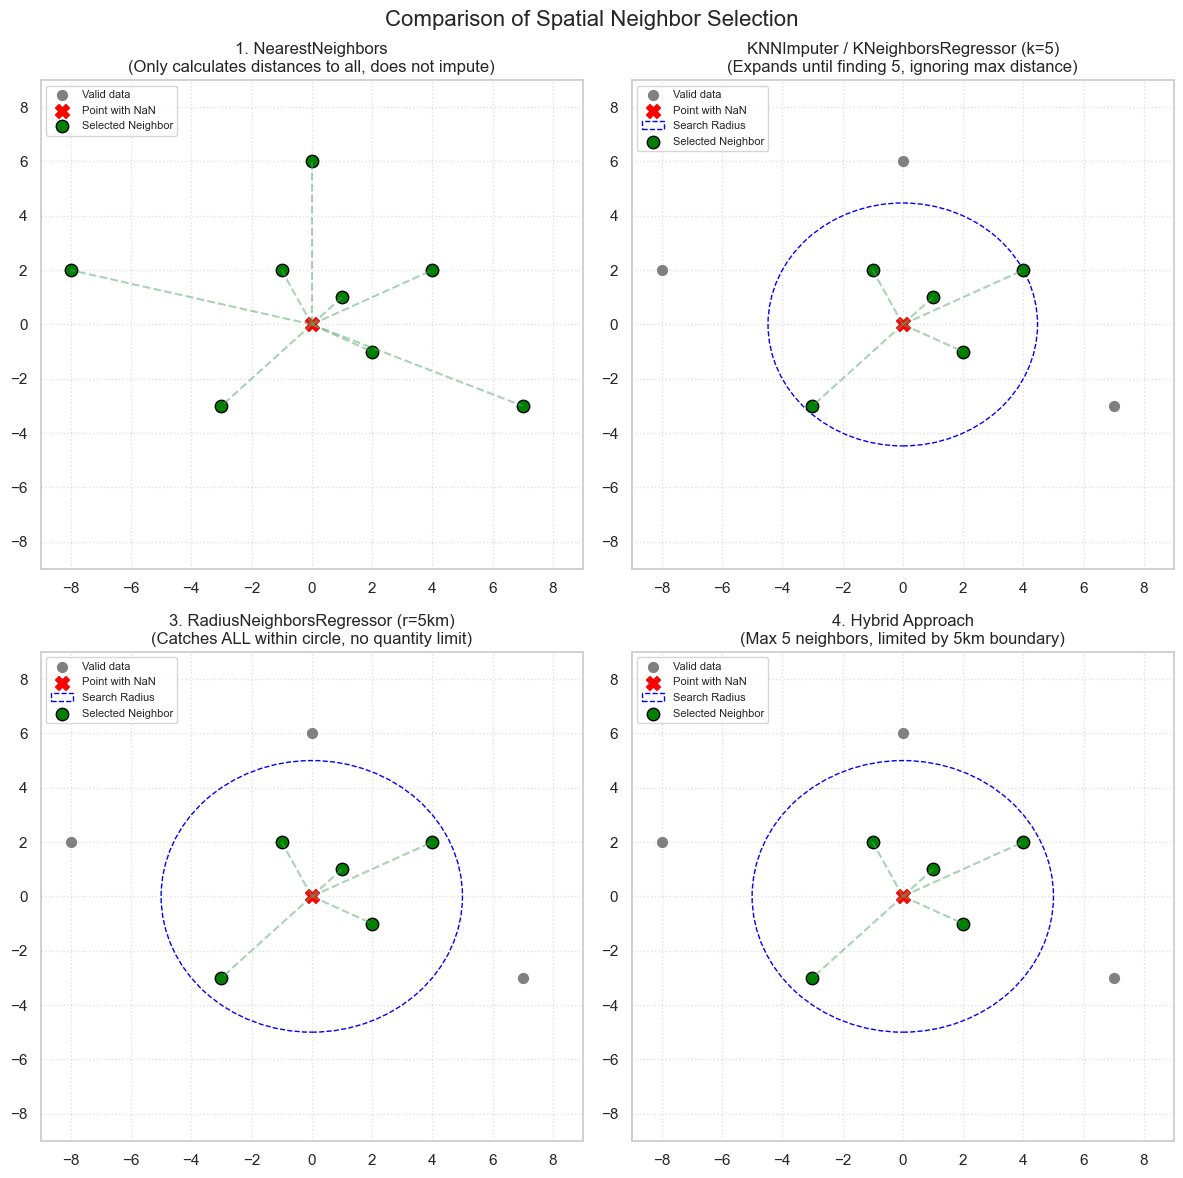

In [61]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Simulate a geographical scenario
# Central point (the one with NaN that we want to impute)
punto_objetivo = np.array([[0, 0]])

# Real neighbors with data (x, y coordinates in thousands of meters)
vecinos = np.array([
    [1, 1], [-1, 2], [2, -1],  # 3 very close neighbors (< 3 km)
    [-3, -3], [4, 2],          # 2 mid-distance neighbors (~4.5 km)
    [0, 6], [7, -3], [-8, 2]   # 3 very far neighbors (> 6 km)
])

# 2. Plot configuration
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
fig.suptitle('Comparison of Spatial Neighbor Selection', fontsize=16)

# Helper function for drawing
def plot_scenario(ax, title, circle_radius=None, selected_indices=[]):
    ax.scatter(vecinos[:, 0], vecinos[:, 1], c='gray', label='Valid data', s=50)
    ax.scatter(punto_objetivo[:, 0], punto_objetivo[:, 1], c='red', marker='X', s=100, label='Point with NaN')
    
    if circle_radius:
        circle = plt.Circle((0, 0), circle_radius, color='blue', fill=False, linestyle='--', label=f'Search Radius')
        ax.add_patch(circle)
        
    for idx in selected_indices:
        ax.scatter(vecinos[idx, 0], vecinos[idx, 1], c='green', s=80, edgecolors='black', label='Selected Neighbor' if idx==selected_indices[0] else "")
        ax.plot([0, vecinos[idx, 0]], [0, vecinos[idx, 1]], 'g--', alpha=0.5)
        
    ax.set_xlim(-9, 9)
    ax.set_ylim(-9, 9)
    ax.set_title(title)
    ax.grid(True, linestyle=':', alpha=0.6)
    
    # Avoid duplicated legends
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper left', fontsize=8)

# --- PANEL 1: NearestNeighbors (Only measures) ---
# Calculates distances to ALL, but does not impute anything.
plot_scenario(axs[0, 0], '1. NearestNeighbors\n(Only calculates distances to all, does not impute)', selected_indices=range(8))

# --- PANEL 2: KNNImputer / KNeighborsRegressor (k=5) ---
# Expands blindly until catching exactly 5 points.
distancias = np.linalg.norm(vecinos, axis=1)
indices_knn = np.argsort(distancias)[:5]
radio_knn = distancias[indices_knn[-1]] # Radius of the furthest neighbor out of the 5
plot_scenario(axs[0, 1], 'KNNImputer / KNeighborsRegressor (k=5)\n(Expands until finding 5, ignoring max distance)', circle_radius=radio_knn, selected_indices=indices_knn)

# --- PANEL 3: RadiusNeighborsRegressor (Radius = 5km) ---
# Takes absolutely ALL points within 5km (could be 3, 5, or 20).
radio_fijo = 5.0
indices_radius = np.where(distancias <= radio_fijo)[0]
plot_scenario(axs[1, 0], '3. RadiusNeighborsRegressor (r=5km)\n(Catches ALL within circle, no quantity limit)', circle_radius=radio_fijo, selected_indices=indices_radius)

# --- PANEL 4: Hybrid Approach (k=5 and max_dist=5km) ---
# Maximum 5 points, but discards those outside the 5km radius.
indices_hibridos = [idx for idx in indices_knn if distancias[idx] <= radio_fijo]
plot_scenario(axs[1, 1], '4. Hybrid Approach\n(Max 5 neighbors, limited by 5km boundary)', circle_radius=radio_fijo, selected_indices=indices_hibridos)

plt.tight_layout()
plt.show()

# QC DE VALORES IMPUTADOS

### 1. Inspeccion visual en mapa

Se procede a realizar un QC de los valores imputados de acuerdo a distancias. Esto es para inspeccionar si hay valores que fueron imputados con valores vecinos que estan muy lejos de ellos. Lo cual no tendria sentido desde el punto de vista geologico. Se considera una distancia de 5 Km como un criterio geologico de distancia afectable

In [62]:
qc_df_final.sort_values(by="distancia_promedio_al_vecino_m", ascending=False).head(15)

,id_bd_sinkhole,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_wgs84,y_wgs84,overburden_resistance_numeric_was_nan,depth_drift_clean_was_nan,working_thickness_numeric_was_nan,x_wgs84_was_nan,y_wgs84_was_nan,distancia_promedio_al_vecino_m
363,FR-SIN-371,2.000000,85.000000,2.250000,-4.122974,48.034194,False,False,True,False,False,50385.938345
365,FR-SIN-373,2.000000,157.000000,2.250000,-4.082253,47.997950,False,False,True,False,False,50294.534036
364,FR-SIN-372,2.000000,138.520083,2.250000,-4.092747,47.998409,False,True,True,False,False,50232.434892
362,FR-SIN-370,2.000000,95.000000,2.250000,-4.113809,48.029563,False,False,True,False,False,50018.058527
116,FR-SIN-124,1.000000,25.000000,2.299972,2.557929,46.038474,False,False,True,False,False,23968.977308
507,DEU-SIN-03,2.000000,162.000000,1.940920,7.458279,51.485549,False,False,True,False,False,13370.802589
506,DEU-SIN-02,2.000000,125.000000,1.957569,7.362299,51.449671,False,False,True,False,False,8827.905261
313,FR-SIN-321,1.000000,50.000000,2.250000,-0.794940,48.022501,False,False,True,False,False,7992.133942
312,FR-SIN-320,1.000000,50.000000,2.250000,-0.789848,48.026792,False,False,True,False,False,7856.601561
314,FR-SIN-322,1.000000,50.000000,2.250000,-0.769502,48.008130,False,True,True,False,False,7676.842461


Valores por arriba de 5000 metros seran eliminados para la imputacion? 
O a su vez, se podria decirle al k-means que cuando tengamos valores mas lejanos de 5km no los tome en cuenta? Tiene sentido esto?

In [63]:
df_final_imputed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   x_laea                          1501 non-null   float64
 1   y_laea                          1501 non-null   float64
 2   overburden_resistance_numeric   1501 non-null   float64
 3   depth_drift_clean               1501 non-null   float64
 4   working_thickness_numeric       1501 non-null   float64
 5   x_wgs84                         1501 non-null   float64
 6   y_wgs84                         1501 non-null   float64
 7   id_bd_sinkhole                  1501 non-null   object 
 8   distancia_promedio_al_vecino_m  1501 non-null   float64
dtypes: float64(8), object(1)
memory usage: 149.6+ KB


In [64]:
import folium
from folium.plugins import HeatMap, MarkerCluster

# 1. Crear el mapa base centrado en el promedio de tus coordenadas
# Cualquier texto que no sea un número se convertirá en NaN
df_final_imputed['y_wgs84'] = pd.to_numeric(df_final_imputed['y_wgs84'], errors='coerce')
df_final_imputed['x_wgs84'] = pd.to_numeric(df_final_imputed['x_wgs84'], errors='coerce')

mapa_sinkholes = folium.Map(
    location=[df_final_imputed['y_wgs84'].mean(), df_final_imputed['x_wgs84'].mean()], 
    zoom_start=12,
    tiles='CartoDB positron'
)

# 2. Opción A: Marcadores Agrupados (MarkerCluster)
# Esto agrupa los puntos automáticamente (verás círculos con números como "73", "49", etc.)
marker_cluster = MarkerCluster(name="Agrupación de Sinkholes").add_to(mapa_sinkholes)

for idx, row in df_final_imputed.iterrows():
    if not np.isnan(row['y_wgs84']) and not np.isnan(row['x_wgs84']):
        folium.CircleMarker(
            location=[row['y_wgs84'], row['x_wgs84']],
            radius=3,
            color='red',
            fill=True,
            fill_color='red',
            # Añadimos información al hacer click (tu variable limpia de profundidad)
            popup=f"ID: {row['id_bd_sinkhole']} <br> Depth of the drift: {row['depth_drift_clean']}m <br> Working thickness: {row['working_thickness_numeric']} <br> Overburden Resistance: {row['overburden_resistance_numeric']}"
        ).add_to(marker_cluster)

# 3. Opción B: Mapa de Calor (HeatMap)
# Esto cumple con la parte de "análisis probabilístico" mostrando zonas de mayor ocurrencia
heat_data = [[row['y_wgs84'], row['x_wgs84']] for idx, row in df_final_imputed.iterrows() if not np.isnan(row['y_wgs84'])]
HeatMap(heat_data, name="Mapa de Calor (Densidad)", radius=15, blur=10).add_to(mapa_sinkholes)

# Añadir control de capas para encender/apagar el mapa de calor
folium.LayerControl().add_to(mapa_sinkholes)

# Guardar y mostrar
mapa_sinkholes.save('map_after_imputation.html')

### 2. Matriz de correlacion

#### 2.1. Antes de la imputacion

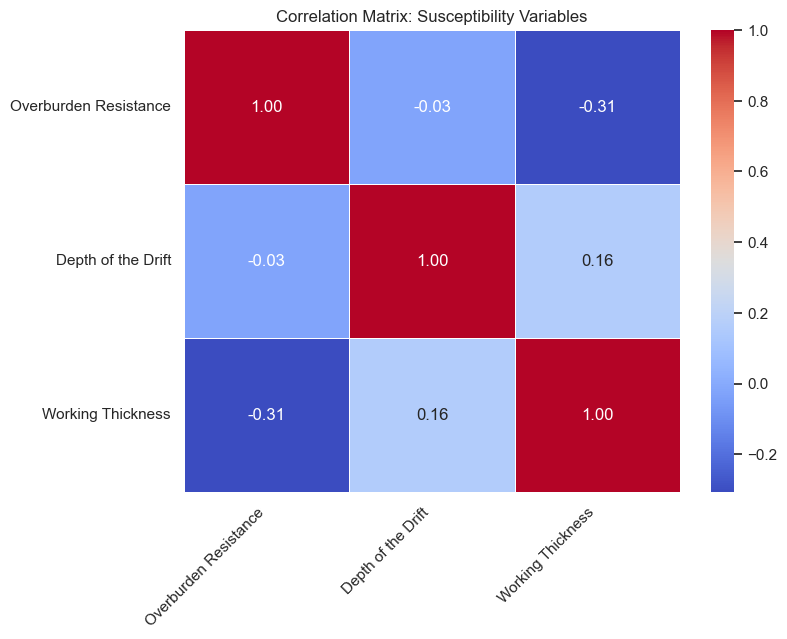

In [65]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Definimos las variables del modelo
columnas_modelo = [
    'overburden_resistance_numeric', 
    'depth_drift_clean', 
    'working_thickness_numeric'
]

# 2. Creamos una lista con los nombres que queremos visualizar
etiquetas_limpias = [
    'Overburden Resistance', 
    'Depth of the Drift', 
    'Working Thickness'
]

# Calculamos la matriz de correlación
matriz_corr = df_susceptibilidad[columnas_modelo].corr()

plt.figure(figsize=(8, 6))

# 3. Añadimos xticklabels y yticklabels al heatmap
sns.heatmap(
    matriz_corr, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=0.5,
    xticklabels=etiquetas_limpias,
    yticklabels=etiquetas_limpias
)

# 4. Rotamos las etiquetas para mejorar la legibilidad (opcional)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.title('Correlation Matrix: Susceptibility Variables')
plt.show()

### 2.2. Despues de la imputacion

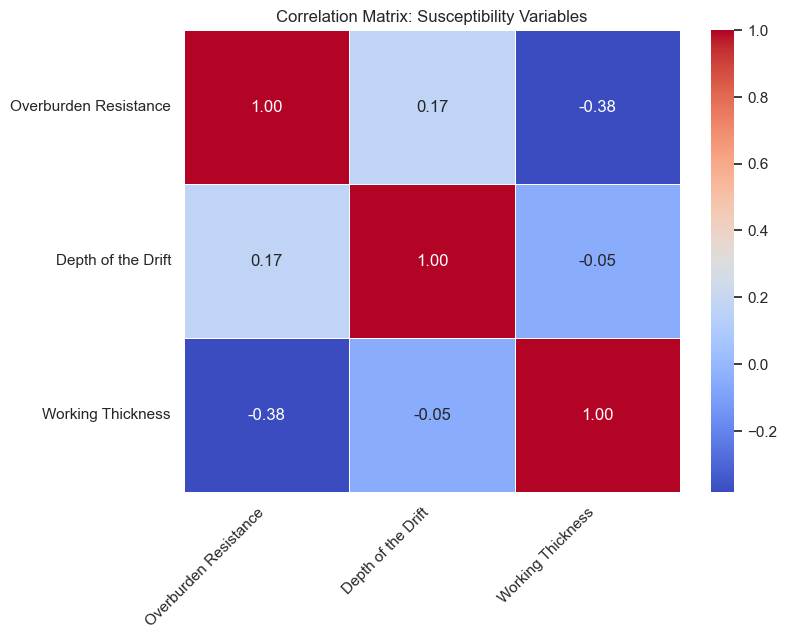

In [66]:
# 1. Definimos las variables del modelo
columnas_modelo = [
    'overburden_resistance_numeric', 
    'depth_drift_clean', 
    'working_thickness_numeric'
]

# 2. Creamos una lista con los nombres que queremos visualizar
etiquetas_limpias = [
    'Overburden Resistance', 
    'Depth of the Drift', 
    'Working Thickness'
]

# Calculamos la matriz de correlación
matriz_corr = df_final_imputed[columnas_modelo].corr()

plt.figure(figsize=(8, 6))

# 3. Añadimos xticklabels y yticklabels al heatmap
sns.heatmap(
    matriz_corr, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=0.5,
    xticklabels=etiquetas_limpias,
    yticklabels=etiquetas_limpias
)

# 4. Rotamos las etiquetas para mejorar la legibilidad (opcional)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)

plt.title('Correlation Matrix: Susceptibility Variables')
plt.show()

### 3. ANALISIS DE COLINEALIDAD

### 3.1 Antes de la imputacion

In [67]:
# ANALISIS DE COLINEALIDAD
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Calculo del VIF (Variance Inflation Factor)

"""
- VIF = 1: No correlation.
- 1 < VIF < 5: Moderate correlation. Generally acceptable and does not requiere variable elimination.
- VIF > 5: Critical multicollinearity. The model coefficients may be unreliable.
- VIF > 10: You must eliminate one of the variables involved because they are redundant.
"""

# 1. Filtramos solo las variables de interés y eliminamos filas con nulos para el test
df_vif = df_susceptibilidad[['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']].dropna()

# 2. Es obligatorio añadir una columna constante para el cálculo matemático
X = add_constant(df_vif)

# 3. Calculamos el VIF para cada variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

# Mostramos resultados (quitando la fila de la constante)
print("--- RESULTADOS DEL ANÁLISIS VIF ---")
print(vif_data[vif_data["Variable"] != "const"].sort_values(by="VIF", ascending=False))

--- RESULTADOS DEL ANÁLISIS VIF ---
                        Variable       VIF
3      working_thickness_numeric  1.132173
1  overburden_resistance_numeric  1.108614
2              depth_drift_clean  1.027587


### 3.2. Despues de la imputacion

In [68]:
# 1. Filtramos solo las variables de interés y eliminamos filas con nulos para el test
df_vif_imputed = df_final_imputed[['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']].dropna()

# 2. Es obligatorio añadir una columna constante para el cálculo matemático
X = add_constant(df_vif_imputed)

# 3. Calculamos el VIF para cada variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

# Mostramos resultados (quitando la fila de la constante)
print("---------------- VIF RESULTS-----------------")
print(vif_data[vif_data["Variable"] != "const"].sort_values(by="VIF", ascending=False))

---------------- VIF RESULTS-----------------
                        Variable       VIF
1  overburden_resistance_numeric  1.206257
3      working_thickness_numeric  1.173203
2              depth_drift_clean  1.030999


### 4. CORRECCION DE OVERBURDEN RESISTANCE NUMERIC

In [69]:
df_final_imputed.overburden_resistance_numeric.unique()

array([1.        , 2.        , 3.        , 2.00578871, 2.01104111,
       2.00883719, 2.00941099, 2.00885643, 2.00859195, 2.01202019,
       2.01173265, 2.0111063 , 2.01112932, 2.01112745, 2.01112244,
       2.01125235, 2.0115987 , 2.01160619, 2.01100186, 2.0110078 ,
       2.0114563 , 2.01150161, 2.01127817, 2.01130892, 2.01105069,
       2.01105072, 2.01138351, 2.01106917, 2.01229295])

In [70]:
#  CORRECION DE LA VARIABLE CATEGORICA
# 1. Redondeamos los valores al entero más cercano y forzamos el tipo a 'int'
df_final_imputed['overburden_resistance_numeric'] = df_final_imputed['overburden_resistance_numeric'].round().astype(int)

# 2. Verificamos que ahora solo existan las categorías 1, 2 y 3
valores_unicos = df_final_imputed['overburden_resistance_numeric'].unique()
print(f"Valores únicos tras la corrección: {valores_unicos}")

# 3. Vemos cuántos registros quedaron en cada categoría
print("\nDistribución de la variable:")
print(df_final_imputed['overburden_resistance_numeric'].value_counts().sort_index())

Valores únicos tras la corrección: [1 2 3]

Distribución de la variable:
overburden_resistance_numeric
1    1234
2     186
3      81
Name: count, dtype: int64


In [71]:
df_final_imputed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 9 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   x_laea                          1501 non-null   float64
 1   y_laea                          1501 non-null   float64
 2   overburden_resistance_numeric   1501 non-null   int64  
 3   depth_drift_clean               1501 non-null   float64
 4   working_thickness_numeric       1501 non-null   float64
 5   x_wgs84                         1501 non-null   float64
 6   y_wgs84                         1501 non-null   float64
 7   id_bd_sinkhole                  1501 non-null   object 
 8   distancia_promedio_al_vecino_m  1501 non-null   float64
dtypes: float64(7), int64(1), object(1)
memory usage: 149.6+ KB


In [72]:
df_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1868 non-null   object 
 1   x_wgs84                        1868 non-null   float64
 2   y_wgs84                        1868 non-null   float64
 3   overburden_resistance_numeric  1475 non-null   float64
 4   depth_drift_clean              1339 non-null   float64
 5   working_thickness_numeric      1102 non-null   float64
dtypes: float64(5), object(1)
memory usage: 87.7+ KB


In [73]:
df_susceptibilidad_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1501 non-null   object 
 1   x_wgs84                        1501 non-null   float64
 2   y_wgs84                        1501 non-null   float64
 3   overburden_resistance_numeric  1475 non-null   float64
 4   depth_drift_clean              1339 non-null   float64
 5   working_thickness_numeric      1102 non-null   float64
 6   x_laea                         1501 non-null   float64
 7   y_laea                         1501 non-null   float64
dtypes: float64(7), object(1)
memory usage: 137.8+ KB


### 5. CORRELACION ENTRE VARIABLES

### RELACION ENTRE VARIABLES DEL MODELO

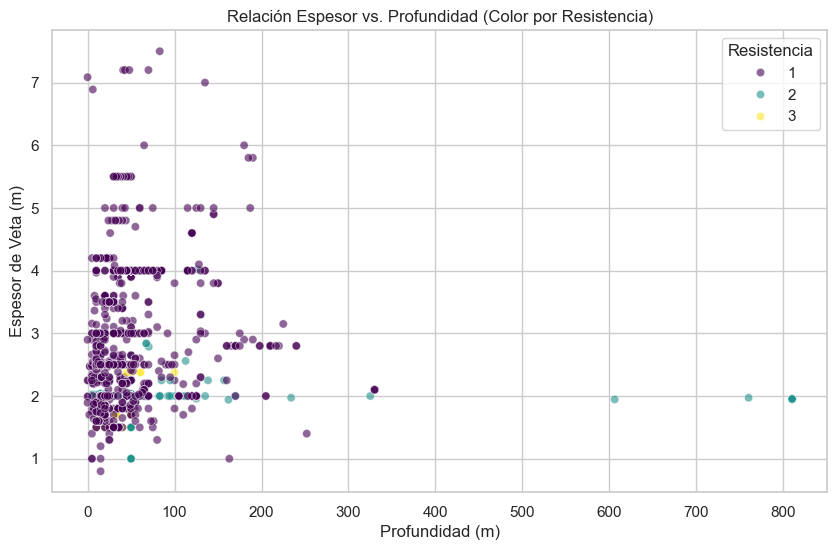

In [74]:
# 2. RELACION ESPESOR DE CAPA VS PROFUNDIDAD

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_final_imputed, 
    x='depth_drift_clean', 
    y='working_thickness_numeric', 
    hue='overburden_resistance_numeric', 
    palette='viridis',
    alpha=0.6
)

plt.title('Relación Espesor vs. Profundidad (Color por Resistencia)')
plt.xlabel('Profundidad (m)')
plt.ylabel('Espesor de Veta (m)')
plt.legend(title='Resistencia')
plt.show()


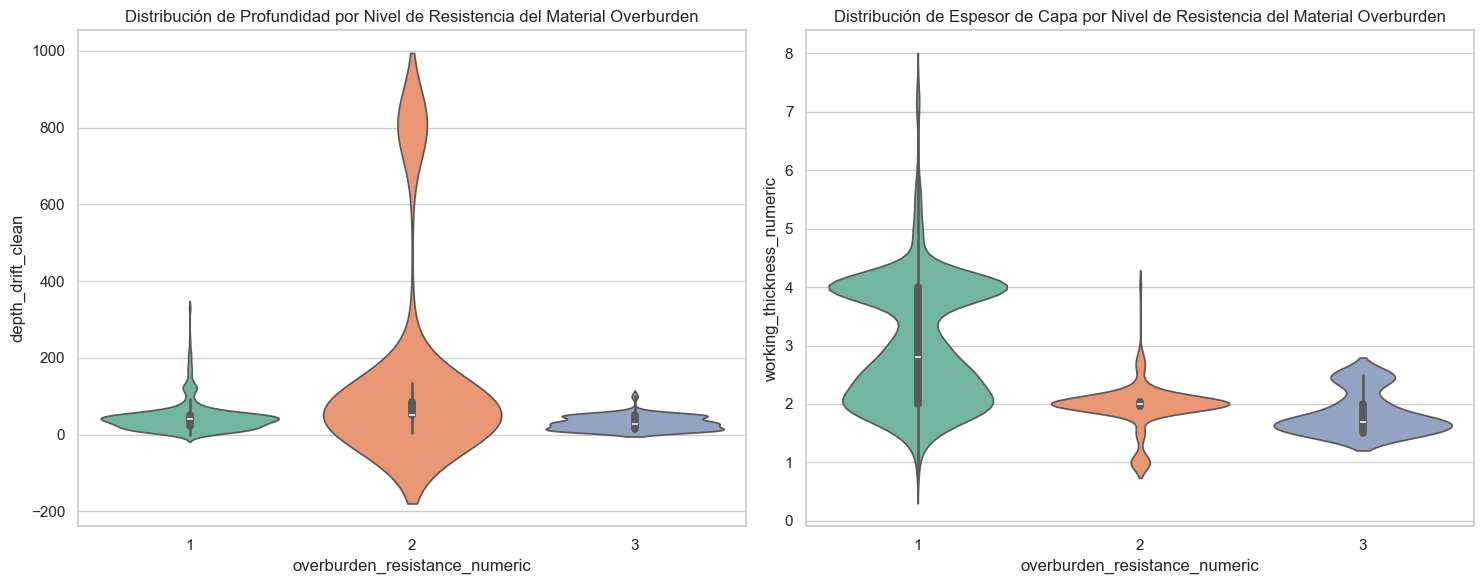

In [75]:
# 3. DISTRIBUCION DE DENSIDADES

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Distribución de Profundidad por Resistencia
sns.violinplot(
    x='overburden_resistance_numeric', 
    y='depth_drift_clean', 
    data=df_final_imputed, 
    ax=ax1, palette='Set2', 
    hue='overburden_resistance_numeric', 
    legend=False  )

ax1.set_title('Distribución de Profundidad por Nivel de Resistencia del Material Overburden')

# Distribución de Espesor por Resistencia
sns.violinplot(
    x='overburden_resistance_numeric', 
    y='working_thickness_numeric', 
    data=df_final_imputed, 
    ax=ax2, palette='Set2', 
    hue='overburden_resistance_numeric', 
    legend=False  )

ax2.set_title('Distribución de Espesor de Capa por Nivel de Resistencia del Material Overburden')

plt.tight_layout()
plt.show()

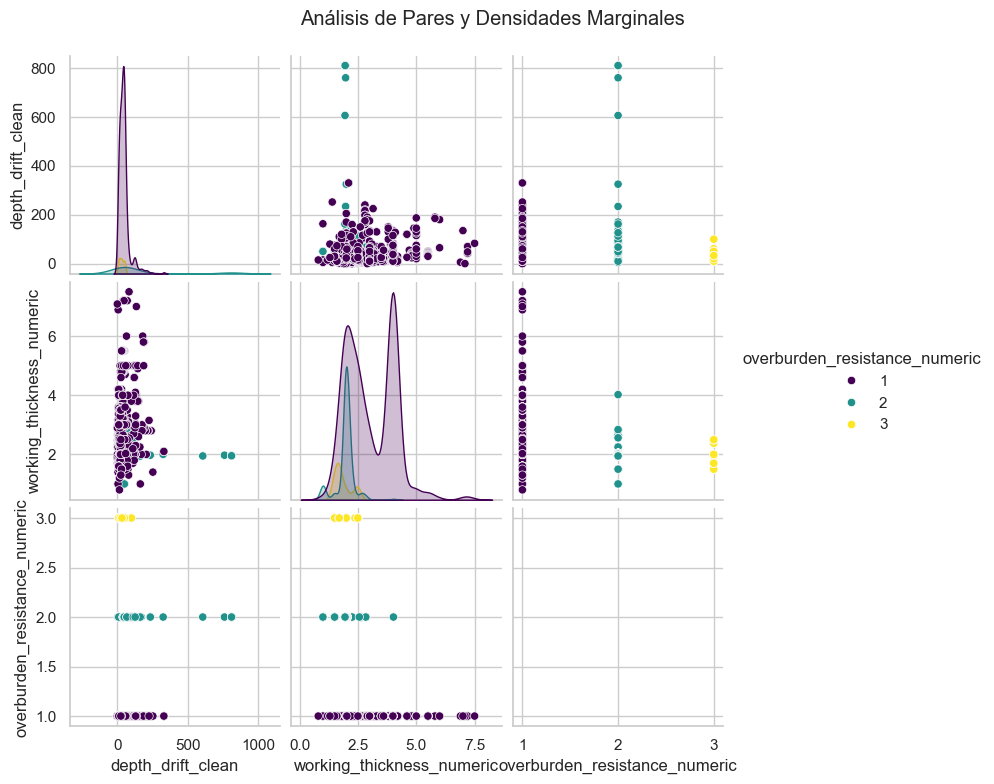

In [76]:
# PAIRPLOT DE TENDENCIAS

sns.pairplot(df_final_imputed, 
             vars=['depth_drift_clean', 'working_thickness_numeric', 'overburden_resistance_numeric'], 
             hue='overburden_resistance_numeric', 
             palette='viridis', 
             diag_kind='kde'
             )

plt.suptitle('Análisis de Pares y Densidades Marginales', y=1.04)
plt.show()

# MODELO DE SUSCEPTIBILIDAD

In [77]:
df_final_imputed.overburden_resistance_numeric.unique()

array([1, 2, 3])

In [78]:
modelo_granular_susceptibilidad = df_final_imputed.copy()
modelo_granular_susceptibilidad.head()

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_wgs84,y_wgs84,id_bd_sinkhole,distancia_promedio_al_vecino_m
0,3.740790e+06,2.528731e+06,1,40.0,2.5,2.558499,45.610043,FR-SIN-08,182.492584
1,3.740805e+06,2.528830e+06,1,40.0,2.5,2.558569,45.610944,FR-SIN-09,154.678877
2,3.741064e+06,2.528811e+06,1,50.0,2.5,2.561892,45.611002,FR-SIN-10,204.627655
3,3.740451e+06,2.528268e+06,1,50.0,2.5,2.554737,45.605589,FR-SIN-11,100.520552
4,3.740555e+06,2.528307e+06,1,25.0,2.5,2.556017,45.606026,FR-SIN-12,39.284693


## 1. Normalizacion de variable depth_drift_clean

In [79]:
import numpy as np

# 1. Transformación logarítmica para reducir el sesgo
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'])

# 2. Normalización Min-Max Inversa sobre el logaritmo
log_min, log_max = log_depth.min(), log_depth.max()
modelo_granular_susceptibilidad['depth_drift_norm'] = (log_max - log_depth) / (log_max - log_min)

# 3. Visualizar resultados
modelo_granular_susceptibilidad[["depth_drift_clean", "depth_drift_norm"]]

,depth_drift_clean,depth_drift_norm
0,40.0,0.445592
1,40.0,0.445592
2,50.0,0.413009
3,50.0,0.413009
4,25.0,0.513591
...,...,...
1863,60.0,0.386278
1864,10.0,0.642013
1865,10.0,0.642013
1866,30.0,0.487332


## 2. Normalizacion de variable working_thickness_numeric

En este caso a diferencia de depth_drift_clean, esta variable no tiene valores atípicos extremos (el máximo está cerca del grueso de los datos) y el rango es pequeño. La normalización lineal preservará perfectamente la estructura bimodal, lo cual es útil si esos dos picos representan dos tipos diferentes de vetas o métodos de minería.

In [80]:
# 1. Definimos los límites basados en tus datos
thickness_min = modelo_granular_susceptibilidad['working_thickness_numeric'].min()
thickness_max = modelo_granular_susceptibilidad['working_thickness_numeric'].max()

# 2. Realizamos una normalización directa (Mayor espesor = Mayor Susceptibilidad)
modelo_granular_susceptibilidad['working_thickness_norm'] = (
    (modelo_granular_susceptibilidad['working_thickness_numeric'] - thickness_min) / 
    (thickness_max - thickness_min)
)

# 3. Visualizamos resultados
modelo_granular_susceptibilidad[["working_thickness_numeric", "working_thickness_norm"]]

,working_thickness_numeric,working_thickness_norm
0,2.5,0.253731
1,2.5,0.253731
2,2.5,0.253731
3,2.5,0.253731
4,2.5,0.253731
...,...,...
1863,5.0,0.626866
1864,3.0,0.328358
1865,1.6,0.119403
1866,1.5,0.104478


## 3. Normalizacion de variable overburden_resistance_numeric

In [81]:
# 1. Funcion de normalizacion por frecuencia
def get_weights(df, column_name):
    # Calculamos la frecuencia normalizada
    freq = df[column_name].value_counts(normalize=True)
    # Creamos el score normalizado (Max = 1.0)
    score = (freq / freq.max()).to_dict()
    return score

# 2. aplicamos la funcion
weights_res = get_weights(modelo_granular_susceptibilidad, 'overburden_resistance_numeric')

# 3. Mapeo la funcion en cada sinkhole
modelo_granular_susceptibilidad['overburden_resistance_norm'] = modelo_granular_susceptibilidad['overburden_resistance_numeric'].map(weights_res).astype(float)

In [82]:
modelo_granular_susceptibilidad.overburden_resistance_norm.unique()

array([1.        , 0.15072934, 0.06564019])

In [83]:
# Normalizacion por criterio experto
# 1 (Weak) -> 1.0 (Max Susceptibilidad)
# 2 (Medium) -> 0.35
# 3 (Resistant) -> 0.10 (Min Susceptibilidad)

# Si se asigna de acuerdo a la frecuencia normalizada, la distribucion seria (1, 0.14, 0.069)

# En este caso se decide asignar valores mas equilibrados para que el peso de los valores con susecptibilidad 1 no sea tan determinante en la asignacion del "riesgo" 
mapeo_riesgo = {1: 1.0, 2: 0.35, 3: 0.10}

modelo_granular_susceptibilidad['overburden_resistance_norm_expert'] = (
    modelo_granular_susceptibilidad['overburden_resistance_numeric'].map(mapeo_riesgo)
)

In [84]:
modelo_granular_susceptibilidad.overburden_resistance_norm_expert.unique()

array([1.  , 0.35, 0.1 ])

In [85]:
modelo_granular_susceptibilidad.head(10)

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_wgs84,y_wgs84,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert
0,3.740790e+06,2.528731e+06,1,40.0,2.5,2.558499,45.610043,FR-SIN-08,182.492584,0.445592,0.253731,1.0,1.0
1,3.740805e+06,2.528830e+06,1,40.0,2.5,2.558569,45.610944,FR-SIN-09,154.678877,0.445592,0.253731,1.0,1.0
2,3.741064e+06,2.528811e+06,1,50.0,2.5,2.561892,45.611002,FR-SIN-10,204.627655,0.413009,0.253731,1.0,1.0
3,3.740451e+06,2.528268e+06,1,50.0,2.5,2.554737,45.605589,FR-SIN-11,100.520552,0.413009,0.253731,1.0,1.0
4,3.740555e+06,2.528307e+06,1,25.0,2.5,2.556017,45.606026,FR-SIN-12,39.284693,0.513591,0.253731,1.0,1.0
5,3.740587e+06,2.528313e+06,1,12.5,2.5,2.556427,45.606109,FR-SIN-13,33.756331,0.611438,0.253731,1.0,1.0
6,3.740597e+06,2.528302e+06,1,12.5,2.5,2.556568,45.606019,FR-SIN-14,35.491707,0.611438,0.253731,1.0,1.0
7,3.740716e+06,2.528361e+06,1,50.0,2.5,2.558013,45.606655,FR-SIN-15,103.494845,0.413009,0.253731,1.0,1.0
8,3.740661e+06,2.528308e+06,1,50.0,2.5,2.557376,45.606130,FR-SIN-16,64.290186,0.413009,0.253731,1.0,1.0
9,3.740542e+06,2.528302e+06,1,25.0,2.5,2.555863,45.605971,FR-SIN-17,42.529508,0.513591,0.253731,1.0,1.0


### **ASIGNACION DE PESOS - METODO HEURÍSTICO**

In [86]:
import pandas as pd

# --- 1. DEFINICIÓN DE RANGOS (BINS) ---
bins_depth = [0, 15, 30, 60, 1000]
labels_depth = ['Muy Somero (0-15m)', 'Somero (15-30m)', 'Medio (30-60m)', 'Profundo (>60m)']

bins_thick = [0, 1, 2, 3, 5, 20]
labels_thick = ['Delgado (0-1m)', 'Medio (1-2m)', 'Grueso (2-3m)', 'Muy Grueso (3-5m)', 'Masivo (>5m)']

# --- 2. ASIGNACIÓN DE CATEGORÍAS ---
modelo_granular_susceptibilidad['range_depth'] = pd.cut(modelo_granular_susceptibilidad['depth_drift_clean'], bins=bins_depth, labels=labels_depth)
modelo_granular_susceptibilidad['range_thick'] = pd.cut(modelo_granular_susceptibilidad['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)
# Para resistancia de material se utilizar 

# --- 3. CÁLCULO DEL SCORE FINAL (S) ---
# Definimos los coeficientes de importancia - Criterio experto
profundidad = 0.4
espesor = 0.3
resistencia = 0.3

modelo_granular_susceptibilidad['Susceptibility_Score_Expert'] = (
    (modelo_granular_susceptibilidad['depth_drift_norm'] * profundidad) +
    (modelo_granular_susceptibilidad['working_thickness_norm'] * espesor) +
    (modelo_granular_susceptibilidad['overburden_resistance_norm_expert'] * resistencia)
)

In [87]:
modelo_granular_susceptibilidad

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_wgs84,y_wgs84,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert,range_depth,range_thick,Susceptibility_Score_Expert
0,3.740790e+06,2.528731e+06,1,40.0,2.5,2.558499,45.610043,FR-SIN-08,182.492584,0.445592,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.554356
1,3.740805e+06,2.528830e+06,1,40.0,2.5,2.558569,45.610944,FR-SIN-09,154.678877,0.445592,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.554356
2,3.741064e+06,2.528811e+06,1,50.0,2.5,2.561892,45.611002,FR-SIN-10,204.627655,0.413009,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.541323
3,3.740451e+06,2.528268e+06,1,50.0,2.5,2.554737,45.605589,FR-SIN-11,100.520552,0.413009,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.541323
4,3.740555e+06,2.528307e+06,1,25.0,2.5,2.556017,45.606026,FR-SIN-12,39.284693,0.513591,0.253731,1.0,1.0,Somero (15-30m),Grueso (2-3m),0.581556
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1863,4.973030e+06,3.057292e+06,1,60.0,5.0,19.170597,50.260066,POL-SIN-962,39.617477,0.386278,0.626866,1.0,1.0,Medio (30-60m),Muy Grueso (3-5m),0.642571
1864,4.972283e+06,3.053716e+06,1,10.0,3.0,19.154009,50.229036,POL-SIN-963,122.256967,0.642013,0.328358,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.655313
1865,4.972896e+06,3.056543e+06,1,10.0,1.6,19.167440,50.253545,POL-SIN-964,133.990410,0.642013,0.119403,1.0,1.0,Muy Somero (0-15m),Medio (1-2m),0.592626
1866,4.973864e+06,3.057367e+06,1,30.0,1.5,19.182348,50.259799,POL-SIN-965,66.057637,0.487332,0.104478,1.0,1.0,Somero (15-30m),Medio (1-2m),0.526276


### **ASIGNACION DE PESOS - METODO PROBABILISTICO**

In [88]:
import pandas as pd

# --- 1. DEFINICIÓN DE RANGOS (BINS) ---
bins_depth = [0, 15, 30, 60, 1000]
labels_depth = ['Muy Somero (0-15m)', 'Somero (15-30m)', 'Medio (30-60m)', 'Profundo (>60m)']

bins_thick = [0, 1, 2, 3, 5, 20]
labels_thick = ['Delgado (0-1m)', 'Medio (1-2m)', 'Grueso (2-3m)', 'Muy Grueso (3-5m)', 'Masivo (>5m)']

# --- 2. ASIGNACIÓN DE CATEGORÍAS ---
modelo_granular_susceptibilidad['range_depth'] = pd.cut(modelo_granular_susceptibilidad['depth_drift_clean'], bins=bins_depth, labels=labels_depth)
modelo_granular_susceptibilidad['range_thick'] = pd.cut(modelo_granular_susceptibilidad['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

# --- 3. GENERACIÓN DINÁMICA DE TABLAS DE PESOS PROBABILISTICOS ---
def get_weights(df, column_name):
    """
    Asigna pesos dependiendo de su frecuencia de ocurrencia. Es decir, asigna un peso basándose en qué tan frecuente es cada valor en comparación con el valor más común 
    Por eso se crearon rangos para profundidad y para espesor de capa (range_depth y range_thick)
    """
    # Calculamos la frecuencia normalizada
    freq = df[column_name].value_counts(normalize=True)
    # Creamos el score normalizado (Max = 1.0)
    score = (freq / freq.max()).to_dict()
    return score

weights_depth = get_weights(modelo_granular_susceptibilidad, 'depth_drift_clean')
weights_thick = get_weights(modelo_granular_susceptibilidad, 'working_thickness_numeric')
weights_res = get_weights(modelo_granular_susceptibilidad, 'overburden_resistance_numeric')

# --- 4. MAPEO DE PESOS A LAS FILAS ---
modelo_granular_susceptibilidad['F_depth'] = modelo_granular_susceptibilidad['depth_drift_clean'].map(weights_depth).astype(float)
modelo_granular_susceptibilidad['F_thickness'] = modelo_granular_susceptibilidad['working_thickness_numeric'].map(weights_thick).astype(float)
modelo_granular_susceptibilidad['F_resistance'] = modelo_granular_susceptibilidad['overburden_resistance_numeric'].map(weights_res).astype(float)

# --- 5. CÁLCULO DEL SCORE FINAL (S) ---
# Definimos los coeficientes de importancia - Criterio experto 
# (SE DECIDE USAR CRITERIO EXPERTO EN LUGAR DE LOS PESOS PROBABILISTICOS DEBIDO A LA INCOMPLETITUD DEL CATALGO DE SINKHOLES)
profundidad = 0.4
espesor = 0.3
resistencia = 0.3

# Asignar pesos 
modelo_granular_susceptibilidad['Susceptibility_Score_Probabilistico'] = (
    (modelo_granular_susceptibilidad['F_depth'] * profundidad) +
    (modelo_granular_susceptibilidad['F_thickness'] * espesor) +
    (modelo_granular_susceptibilidad['F_resistance'] * resistencia)
)

In [89]:
modelo_granular_susceptibilidad

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_wgs84,y_wgs84,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert,range_depth,range_thick,Susceptibility_Score_Expert,F_depth,F_thickness,F_resistance,Susceptibility_Score_Probabilistico
0,3.740790e+06,2.528731e+06,1,40.0,2.5,2.558499,45.610043,FR-SIN-08,182.492584,0.445592,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.554356,0.492228,0.313830,1.0,0.591040
1,3.740805e+06,2.528830e+06,1,40.0,2.5,2.558569,45.610944,FR-SIN-09,154.678877,0.445592,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.554356,0.492228,0.313830,1.0,0.591040
2,3.741064e+06,2.528811e+06,1,50.0,2.5,2.561892,45.611002,FR-SIN-10,204.627655,0.413009,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.541323,1.000000,0.313830,1.0,0.794149
3,3.740451e+06,2.528268e+06,1,50.0,2.5,2.554737,45.605589,FR-SIN-11,100.520552,0.413009,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.541323,1.000000,0.313830,1.0,0.794149
4,3.740555e+06,2.528307e+06,1,25.0,2.5,2.556017,45.606026,FR-SIN-12,39.284693,0.513591,0.253731,1.0,1.0,Somero (15-30m),Grueso (2-3m),0.581556,0.290155,0.313830,1.0,0.510211
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1863,4.973030e+06,3.057292e+06,1,60.0,5.0,19.170597,50.260066,POL-SIN-962,39.617477,0.386278,0.626866,1.0,1.0,Medio (30-60m),Muy Grueso (3-5m),0.642571,0.145078,0.031915,1.0,0.367606
1864,4.972283e+06,3.053716e+06,1,10.0,3.0,19.154009,50.229036,POL-SIN-963,122.256967,0.642013,0.328358,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.655313,0.373057,0.162234,1.0,0.497893
1865,4.972896e+06,3.056543e+06,1,10.0,1.6,19.167440,50.253545,POL-SIN-964,133.990410,0.642013,0.119403,1.0,1.0,Muy Somero (0-15m),Medio (1-2m),0.592626,0.373057,0.045213,1.0,0.462787
1866,4.973864e+06,3.057367e+06,1,30.0,1.5,19.182348,50.259799,POL-SIN-965,66.057637,0.487332,0.104478,1.0,1.0,Somero (15-30m),Medio (1-2m),0.526276,0.528497,0.114362,1.0,0.545707


## VISUALIZACION DE RESULTADOS

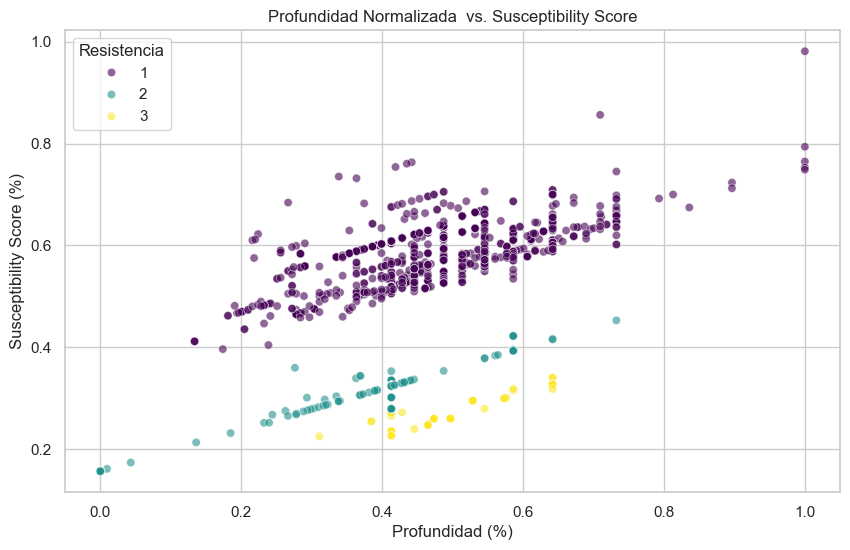

In [90]:
# 2. GRAFICO
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=modelo_granular_susceptibilidad, 
    x='depth_drift_norm', 
    y='Susceptibility_Score_Expert', 
    hue='overburden_resistance_numeric', 
    palette='viridis',
    alpha=0.6
)

plt.title('Profundidad Normalizada  vs. Susceptibility Score')
plt.xlabel('Profundidad (%)')
plt.ylabel('Susceptibility Score (%)')
plt.legend(title='Resistencia')
plt.show()

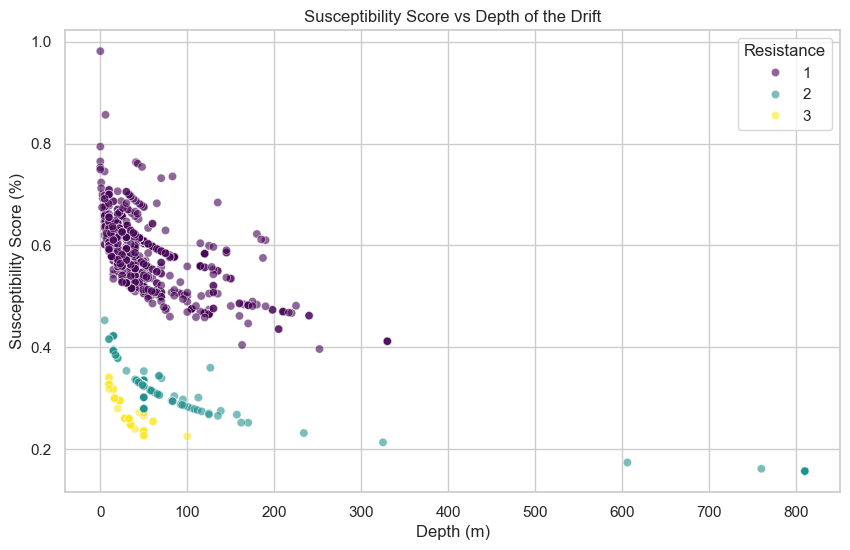

In [91]:
# 2. RELACION SUCEPTIBILIDAD VS PROFUNDIDAD

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=modelo_granular_susceptibilidad, 
    x='depth_drift_clean', 
    y='Susceptibility_Score_Expert', 
    hue='overburden_resistance_numeric', 
    palette='viridis',
    alpha=0.6
)

plt.title('Susceptibility Score vs Depth of the Drift')
plt.xlabel('Depth (m)')
plt.ylabel('Susceptibility Score (%)')
plt.legend(title='Resistance')
plt.show()

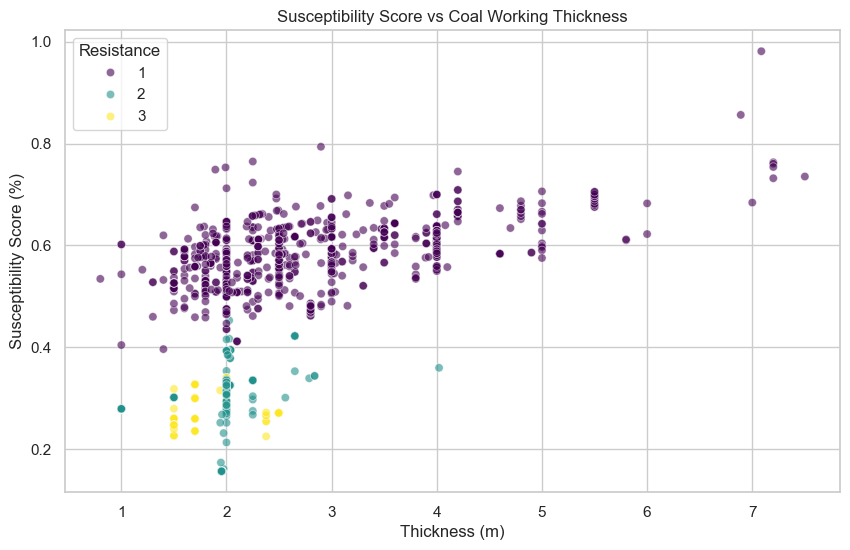

In [92]:
# 2. RELACION SUCEPTIBILIDAD VS PROFUNDIDAD

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=modelo_granular_susceptibilidad, 
    x='working_thickness_numeric', 
    y='Susceptibility_Score_Expert', 
    hue='overburden_resistance_numeric', 
    palette='viridis',
    alpha=0.6
)

plt.title('Susceptibility Score vs Coal Working Thickness')
plt.xlabel('Thickness (m)')
plt.ylabel('Susceptibility Score (%)')
plt.legend(title='Resistance')
plt.show()

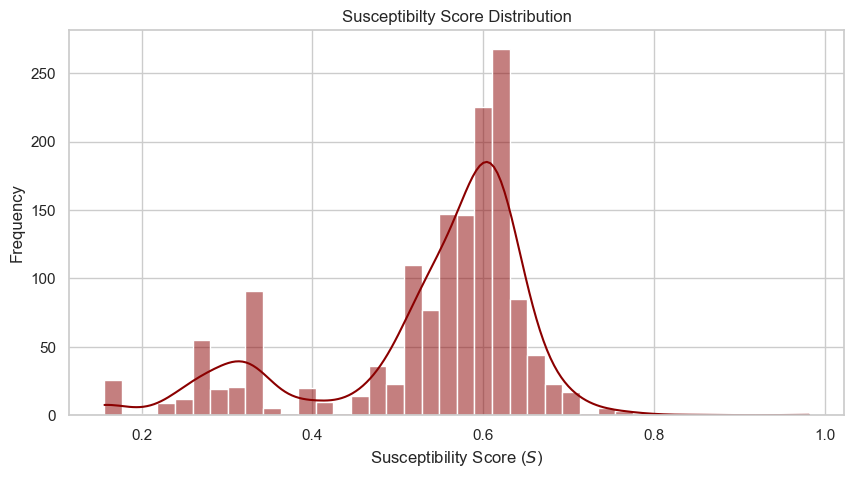

In [93]:
# Visualización de la distribución del Score Resultante
plt.figure(figsize=(10, 5))
#sns.histplot(modelo_granular_susceptibilidad[modelo_granular_susceptibilidad["overburden_resistance_numeric"] == 1]['Susceptibility_Score'], kde=True, color='darkred')
sns.histplot(modelo_granular_susceptibilidad['Susceptibility_Score_Expert'], bins=40, kde=True, color='darkred')
plt.title('Susceptibilty Score Distribution')
plt.xlabel('Susceptibility Score ($S$)')
plt.ylabel('Frequency')
plt.show()

In [94]:
modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].describe()

count    1501.000000
mean        0.535568
std         0.124754
min         0.156558
25%         0.515710
50%         0.581556
75%         0.614649
max         0.981460
Name: Susceptibility_Score_Expert, dtype: float64

In [95]:
bins_depth = [0, 15, 30, 60, 1000]
labels_depth = ['Muy Somero (0-15m)', 'Somero (15-30m)', 'Medio (30-60m)', 'Profundo (>60m)']

bins_thick = [0, 1, 2, 3, 5, 20]
labels_thick = ['Delgado (0-1m)', 'Medio (1-2m)', 'Grueso (2-3m)', 'Muy Grueso (3-5m)', 'Masivo (>5m)']

# --- 2. ASIGNACIÓN DE CATEGORÍAS ---
modelo_granular_susceptibilidad['range_depth'] = pd.cut(modelo_granular_susceptibilidad['depth_drift_clean'], bins=bins_depth, labels=labels_depth)
modelo_granular_susceptibilidad['range_thick'] = pd.cut(modelo_granular_susceptibilidad['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

In [96]:
modelo_granular_susceptibilidad.range_depth.unique()

['Medio (30-60m)', 'Somero (15-30m)', 'Muy Somero (0-15m)', 'Profundo (>60m)', NaN]
Categories (4, object): ['Muy Somero (0-15m)' < 'Somero (15-30m)' < 'Medio (30-60m)' < 'Profundo (>60m)']

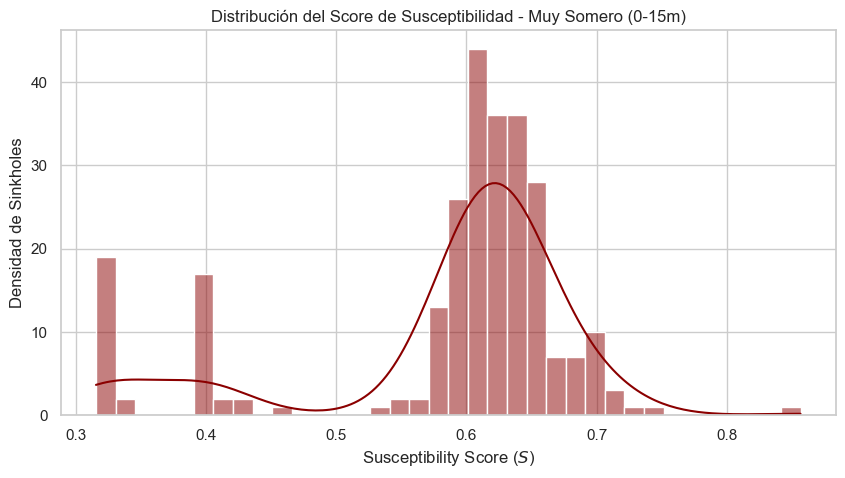

In [97]:
# Visualización de la distribución del Score Resultante
plt.figure(figsize=(10, 5))
profundidad = "Muy Somero (0-15m)"
sns.histplot(modelo_granular_susceptibilidad[modelo_granular_susceptibilidad["range_depth"] == profundidad]['Susceptibility_Score_Expert'], kde=True, color='darkred')
#sns.histplot(modelo_granular_susceptibilidad['Susceptibility_Score'], kde=True, color='darkred')
plt.title(f'Distribución del Score de Susceptibilidad - {profundidad}')
plt.xlabel('Susceptibility Score ($S$)')
plt.ylabel('Densidad de Sinkholes')
plt.show()

In [98]:
# Comparar el Score Final (que ya calculamos con los 3 factores) 
# contra los rangos de profundidad para ver la tendencia
analisis_final = modelo_granular_susceptibilidad.groupby('range_depth', observed=False)['Susceptibility_Score_Expert'].mean()

print("Promedio del Score de Susceptibilidad Final por Rango de Profundidad:")
print(analisis_final)

Promedio del Score de Susceptibilidad Final por Rango de Profundidad:
range_depth
Muy Somero (0-15m)    0.584361
Somero (15-30m)       0.562690
Medio (30-60m)        0.531569
Profundo (>60m)       0.455259
Name: Susceptibility_Score_Expert, dtype: float64


In [99]:
modelo_granular_susceptibilidad.head()

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_wgs84,y_wgs84,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert,range_depth,range_thick,Susceptibility_Score_Expert,F_depth,F_thickness,F_resistance,Susceptibility_Score_Probabilistico
0,3.740790e+06,2.528731e+06,1,40.0,2.5,2.558499,45.610043,FR-SIN-08,182.492584,0.445592,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.554356,0.492228,0.31383,1.0,0.591040
1,3.740805e+06,2.528830e+06,1,40.0,2.5,2.558569,45.610944,FR-SIN-09,154.678877,0.445592,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.554356,0.492228,0.31383,1.0,0.591040
2,3.741064e+06,2.528811e+06,1,50.0,2.5,2.561892,45.611002,FR-SIN-10,204.627655,0.413009,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.541323,1.000000,0.31383,1.0,0.794149
3,3.740451e+06,2.528268e+06,1,50.0,2.5,2.554737,45.605589,FR-SIN-11,100.520552,0.413009,0.253731,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.541323,1.000000,0.31383,1.0,0.794149
4,3.740555e+06,2.528307e+06,1,25.0,2.5,2.556017,45.606026,FR-SIN-12,39.284693,0.513591,0.253731,1.0,1.0,Somero (15-30m),Grueso (2-3m),0.581556,0.290155,0.31383,1.0,0.510211


# DISCRETIZACION DE SUSCEPTBILIDAD

### 1. DISCRETIZACION POR AREAS IGUALES DEL CDF

In [100]:
import numpy as np
from scipy import stats

# --- 1. CÁLCULO DE UMBRALES POR ÁREAS (33.3%) ---
# Asegúrate de que df_susceptibilidad es el DataFrame que contiene tu score calculado
datos = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna()

# 1.1. Estimación de la Densidad de Kernel (KDE) para obtener la curva suave
kde = stats.gaussian_kde(datos)

# Creamos un rango denso de 1000 puntos entre el mínimo y el máximo para integrar el área
x_range = np.linspace(datos.min(), datos.max(), 1000)
y_density = kde(x_range)

# 1.2. Determinamos la Cumulative Distribution Function
cdf = np.cumsum(y_density)
cdf /= cdf[-1]  # Normalización del área a 1.0

# 1.3. Encontrar los puntos de corte para el 33.3% y 66.6% del área
# Buscamos en qué valor de X se alcanza cada tercio del área total
limite_bajo_medio = x_range[np.searchsorted(cdf, 0.3333)]
limite_medio_alto = x_range[np.searchsorted(cdf, 0.6666)]

# --- 2. APLICAR LA CLASIFICACIÓN AL DATAFRAME ---
def clasificar_por_area(score):
    if score <= limite_bajo_medio:
        return 'Low'
    elif score <= limite_medio_alto:
        return 'Medium'
    else:
        return 'High'

modelo_granular_susceptibilidad['Discretization_Equal_Prob'] = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].apply(clasificar_por_area)

# --- 4. VERIFICACIÓN DE BALANCE ---
conteo = modelo_granular_susceptibilidad['Discretization_Equal_Prob'].value_counts().reindex(['Low', 'Medium', 'High'])
print("\n--- Conteo de Sinkholes por Clase (Áreas Equitativas) ---")
print(conteo)


--- Conteo de Sinkholes por Clase (Áreas Equitativas) ---
Discretization_Equal_Prob
Low       494
Medium    496
High      511
Name: count, dtype: int64


--- Cortes CDF (Equiprobabilidad) ---
Corte 33% (Baja -> Media): 0.5379
Corte 66% (Media -> Alta): 0.6085


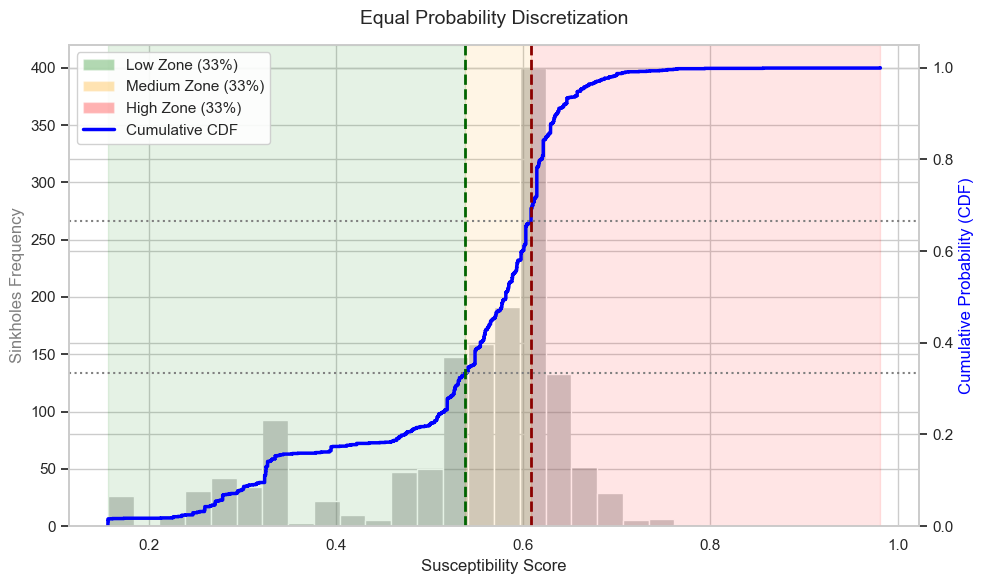

In [101]:
# GRAFICO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. CÁLCULO DE UMBRALES (PERCENTILES EXACTOS) ---
# En un enfoque de CDF, dividir el área en 3 partes iguales es equivalente
# a buscar los percentiles 33.33% y 66.66% directamente en los datos.
datos = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna()

# Calculamos los puntos de corte exactos
limite_bajo_medio = np.percentile(datos, 33.33)
limite_medio_alto = np.percentile(datos, 66.66)

print(f"--- Cortes CDF (Equiprobabilidad) ---")
print(f"Corte 33% (Baja -> Media): {limite_bajo_medio:.4f}")
print(f"Corte 66% (Media -> Alta): {limite_medio_alto:.4f}")

# --- 2. CONFIGURACIÓN DEL GRÁFICO ---
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# --- 3. HISTOGRAMA DE BARRAS (Eje Y Izquierdo: Frecuencia) ---
# Usamos stat='count' para ver el número de registros
ax1 = sns.histplot(data=datos, bins=30, kde=False, color='gray', alpha=0.4, label='Frecuencia (Barras)')
plt.ylabel('Sinkholes Frequency', fontsize=12, color='gray')

# --- 4. CURVA CDF (Eje Y Derecho: Probabilidad) ---
# Creamos un segundo eje Y que comparte el mismo eje X
ax2 = plt.twinx()
sns.ecdfplot(data=datos, color='blue', linewidth=2.5, label='Cumulative CDF', ax=ax2)
ax2.set_ylabel('Cumulative Probability (CDF)', fontsize=12, color='blue')
ax2.set_ylim(0, 1.05) # Aseguramos que el eje Y derecho vaya de 0 a 1

# --- 5. DIBUJAR LAS LÍNEAS DE CORTE Y ZONAS ---
# Líneas Horizontales de Referencia en el eje derecho (CDF)
ax2.axhline(y=0.3333, color='gray', linestyle=':', linewidth=1.5)
ax2.axhline(y=0.6666, color='gray', linestyle=':', linewidth=1.5)

# Líneas Verticales (Cortes en el Score)
plt.axvline(x=limite_bajo_medio, color='darkgreen', linestyle='--', linewidth=2)
plt.axvline(x=limite_medio_alto, color='darkred', linestyle='--', linewidth=2)

# Colorear las Zonas de Riesgo
plt.axvspan(datos.min(), limite_bajo_medio, alpha=0.1, color='green', label='Low Zone (0-33%)')
plt.axvspan(limite_bajo_medio, limite_medio_alto, alpha=0.1, color='orange', label='Medium Zone (33-66%)')
plt.axvspan(limite_medio_alto, datos.max(), alpha=0.1, color='red', label='High Zone (66-100%)')

# --- 6. DETALLES FINALES ---
plt.title('Equal Probability Discretization', fontsize=14, pad=15)
ax1.set_xlabel('Susceptibility Score', fontsize=12)

# Combinar leyendas de ambos ejes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# Añadimos manualmente las zonas de color a la leyenda
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='green', alpha=0.3, label='Low Zone (33%)'),
    Patch(facecolor='orange', alpha=0.3, label='Medium Zone (33%)'),
    Patch(facecolor='red', alpha=0.3, label='High Zone (33%)'),
    lines_2[0] # La línea azul de la CDF
]
ax2.legend(handles=legend_elements, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

In [102]:
modelo_granular_susceptibilidad.head()

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_wgs84,y_wgs84,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,...,overburden_resistance_norm,overburden_resistance_norm_expert,range_depth,range_thick,Susceptibility_Score_Expert,F_depth,F_thickness,F_resistance,Susceptibility_Score_Probabilistico,Discretization_Equal_Prob
0,3.740790e+06,2.528731e+06,1,40.0,2.5,2.558499,45.610043,FR-SIN-08,182.492584,0.445592,...,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.554356,0.492228,0.31383,1.0,0.591040,Medium
1,3.740805e+06,2.528830e+06,1,40.0,2.5,2.558569,45.610944,FR-SIN-09,154.678877,0.445592,...,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.554356,0.492228,0.31383,1.0,0.591040,Medium
2,3.741064e+06,2.528811e+06,1,50.0,2.5,2.561892,45.611002,FR-SIN-10,204.627655,0.413009,...,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.541323,1.000000,0.31383,1.0,0.794149,Medium
3,3.740451e+06,2.528268e+06,1,50.0,2.5,2.554737,45.605589,FR-SIN-11,100.520552,0.413009,...,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.541323,1.000000,0.31383,1.0,0.794149,Medium
4,3.740555e+06,2.528307e+06,1,25.0,2.5,2.556017,45.606026,FR-SIN-12,39.284693,0.513591,...,1.0,1.0,Somero (15-30m),Grueso (2-3m),0.581556,0.290155,0.31383,1.0,0.510211,Medium


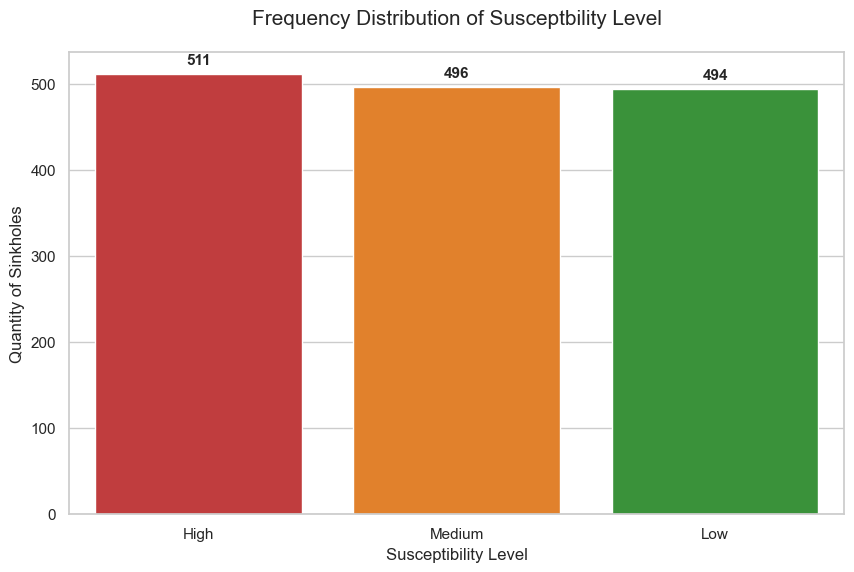

In [103]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración de parámetros
# Asegúrate de que estos nombres coincidan con los que creamos en el paso anterior
orden_niveles = ['High', 'Medium', 'Low']
colores_niveles = {'Low': '#2ca02c', 'Medium': '#ff7f0e', 'High': '#d62728'}

# 2. Crear la figura
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Generar el gráfico de barras
ax = sns.countplot(
    data=modelo_granular_susceptibilidad, 
    x='Discretization_Equal_Prob', 
    order=orden_niveles, 
    hue='Discretization_Equal_Prob', 
    palette=colores_niveles,
    legend=False
)

# 4. Personalizar títulos y etiquetas (sin usar formatos complejos)
plt.title('Frequency Distribution of Susceptbility Level', fontsize=15, pad=20)
plt.xlabel('Susceptibility Level', fontsize=12)
plt.ylabel('Quantity of Sinkholes', fontsize=12)

# 5. Añadir las etiquetas de conteo sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{int(altura)}', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='center', 
                    xytext=(0, 10), 
                    textcoords='offset points', 
                    fontsize=11, fontweight='bold')


### 2. DISCRETIZACION MANUAL EN BASE A JUICIO

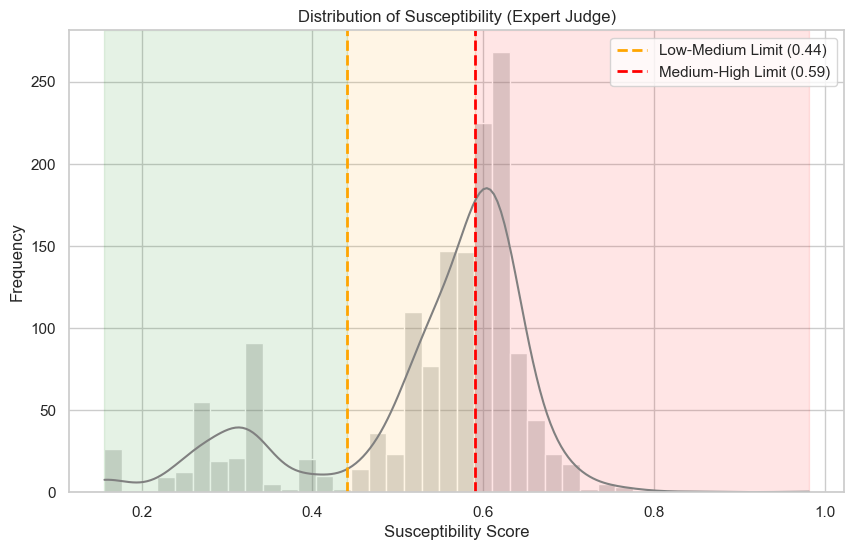


--- Conteo de Sinkholes por Clase ---
Discretization_Expert
High      674
Medium    554
Low       273
Name: count, dtype: int64


In [104]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. OBTENER MÍNIMO Y MÁXIMO DEL SCORE
min_score = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].min()
max_score = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].max()

# 2. DEFINIR LOS LÍMITES MANUALES
# Limite inferior
limite_bajo_medio = 0.44
# Limite superior
limite_medio_alto = 0.59

# 3. APLICAR LA CLASIFICACIÓN
def clasificar_intervalos(score):
    if score <= limite_bajo_medio:
        return 'Low'
    elif score <= limite_medio_alto:
        return 'Medium'
    else:
        return 'High'

modelo_granular_susceptibilidad['Discretization_Expert'] = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].apply(clasificar_intervalos)

# 4. VISUALIZACIÓN DE LA DISTRIBUCIÓN CON LOS CORTES
plt.figure(figsize=(10, 6))

# Histograma de fondo
sns.histplot(modelo_granular_susceptibilidad['Susceptibility_Score_Expert'], bins=40, kde=True, color='gray', alpha=0.3)

# Dibujar las líneas de corte
plt.axvline(limite_bajo_medio, color='orange', linestyle='--', linewidth=2, label=f'Low-Medium Limit ({limite_bajo_medio:.2f})')
plt.axvline(limite_medio_alto, color='red', linestyle='--', linewidth=2, label=f'Medium-High Limit ({limite_medio_alto:.2f})')

# Colorear las áreas (opcional para dar efecto visual)
plt.axvspan(min_score, limite_bajo_medio, alpha=0.1, color='green')
plt.axvspan(limite_bajo_medio, limite_medio_alto, alpha=0.1, color='orange')
plt.axvspan(limite_medio_alto, max_score, alpha=0.1, color='red')

plt.title('Distribution of Susceptibility (Expert Judge)')
plt.xlabel('Susceptibility Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# 6. VERIFICAR CUÁNTOS CAEN EN CADA GRUPO
conteo = modelo_granular_susceptibilidad['Discretization_Expert'].value_counts()
print("\n--- Conteo de Sinkholes por Clase ---")
print(conteo)

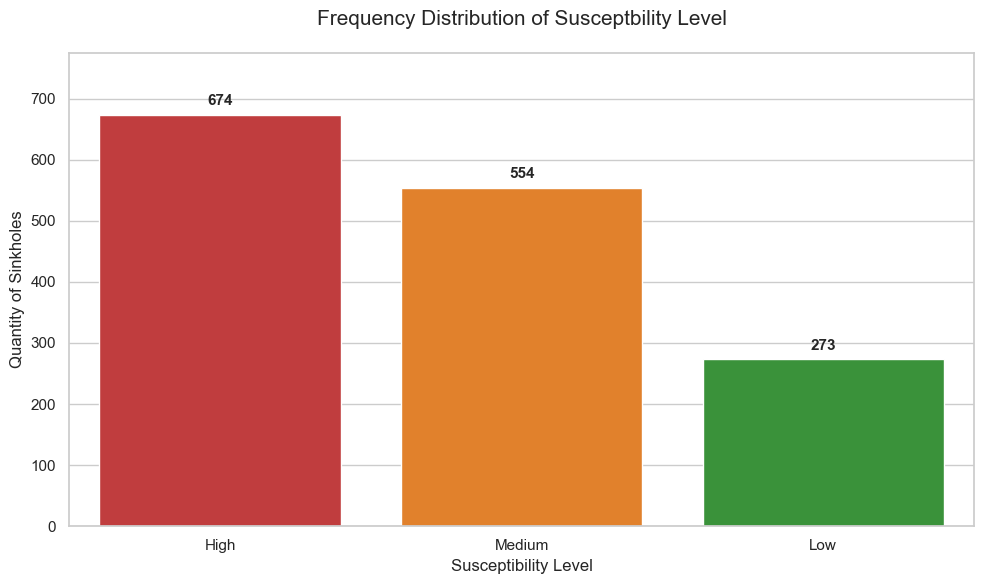

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración de parámetros
# Asegúrate de que estos nombres coincidan con los que creamos en el paso anterior
orden_niveles = ['High', 'Medium', 'Low']
colores_niveles = {'Low': '#2ca02c', 'Medium': '#ff7f0e', 'High': '#d62728'}

# 2. Crear la figura
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Generar el gráfico de barras
# Usamos hue=x para cumplir con las nuevas reglas de Seaborn y evitar advertencias
ax = sns.countplot(
    data=modelo_granular_susceptibilidad, 
    x='Discretization_Expert', 
    order=orden_niveles, 
    hue='Discretization_Expert', 
    palette=colores_niveles,
    legend=False
)

# 4. Personalizar títulos y etiquetas (sin usar formatos complejos)
plt.title('Frequency Distribution of Susceptbility Level', fontsize=15, pad=20)
plt.xlabel('Susceptibility Level', fontsize=12)
plt.ylabel('Quantity of Sinkholes', fontsize=12)

# 5. Añadir las etiquetas de conteo sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{int(altura)}', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='center', 
                    xytext=(0, 10), 
                    textcoords='offset points', 
                    fontsize=11, fontweight='bold')

# 6. Ajustar visualización
# Damos un poco más de aire en la parte superior para que quepan las etiquetas
plt.ylim(0, modelo_granular_susceptibilidad['Discretization_Expert'].value_counts().max() * 1.15)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### 3. DISCRETIZACION CON ALGORITMO DE JENKS (NATURAL BREAKS)

--- Límites Sugeridos por Jenks ---
Low  -> Medium: 0.4044
Medium -> High:  0.5734


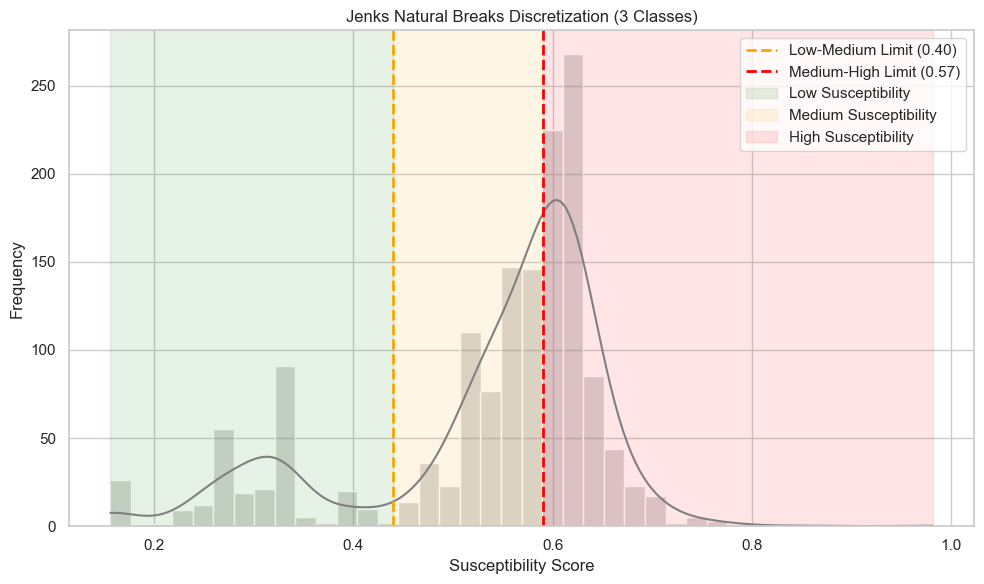


--- Conteo de Sinkholes por Clase (Optimizado) ---
Discretization_Jenks
Low       262
Medium    443
High      796
Name: count, dtype: int64


In [106]:
import jenkspy
import matplotlib.pyplot as plt
import seaborn as sns

# 1. CALCULAR CORTES USANDO JENKS
# Buscamos 3 clases (Baja, Media, Alta)
scores = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna().values
breaks = jenkspy.jenks_breaks(scores, n_classes=3)

# Los breaks devuelven: [min, limite1, limite2, max]
limite_jenks_1 = breaks[1]
limite_jenks_2 = breaks[2]

print(f"--- Límites Sugeridos por Jenks ---")
print(f"Low  -> Medium: {limite_jenks_1:.4f}")
print(f"Medium -> High:  {limite_jenks_2:.4f}")

# 2. APLICAR CLASIFICACIÓN
def clasificar_jenks(val):
    if val <= limite_jenks_1: return 'Low'
    if val <= limite_jenks_2: return 'Medium'
    return 'High'

modelo_granular_susceptibilidad['Discretization_Jenks'] = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].apply(clasificar_jenks)

# 5. VISUALIZACIÓN DE LA DISTRIBUCIÓN CON LOS CORTES
plt.figure(figsize=(10, 6))

# Histograma de fondo
sns.histplot(modelo_granular_susceptibilidad['Susceptibility_Score_Expert'], bins=40, kde=True, color='gray', alpha=0.3)

# Dibujar las líneas de corte calculadas por el algoritmo
plt.axvline(limite_bajo_medio, color='orange', linestyle='--', linewidth=2, label=f'Low-Medium Limit ({limite_jenks_1:.2f})')
plt.axvline(limite_medio_alto, color='red', linestyle='--', linewidth=2, label=f'Medium-High Limit ({limite_jenks_2:.2f})')

# Colorear las áreas para visualización de riesgo
plt.axvspan(min_score, limite_bajo_medio, alpha=0.1, color='green', label='Low Susceptibility')
plt.axvspan(limite_bajo_medio, limite_medio_alto, alpha=0.1, color='orange', label='Medium Susceptibility')
plt.axvspan(limite_medio_alto, max_score, alpha=0.1, color='red', label='High Susceptibility')

plt.title('Jenks Natural Breaks Discretization (3 Classes)')
plt.xlabel('Susceptibility Score')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

# 6. VERIFICAR CUÁNTOS CAEN EN CADA GRUPO
# Ordenamos las categorías para que el conteo sea lógico
conteo = modelo_granular_susceptibilidad['Discretization_Jenks'].value_counts().reindex(['Low', 'Medium', 'High'])
print("\n--- Conteo de Sinkholes por Clase (Optimizado) ---")
print(conteo)


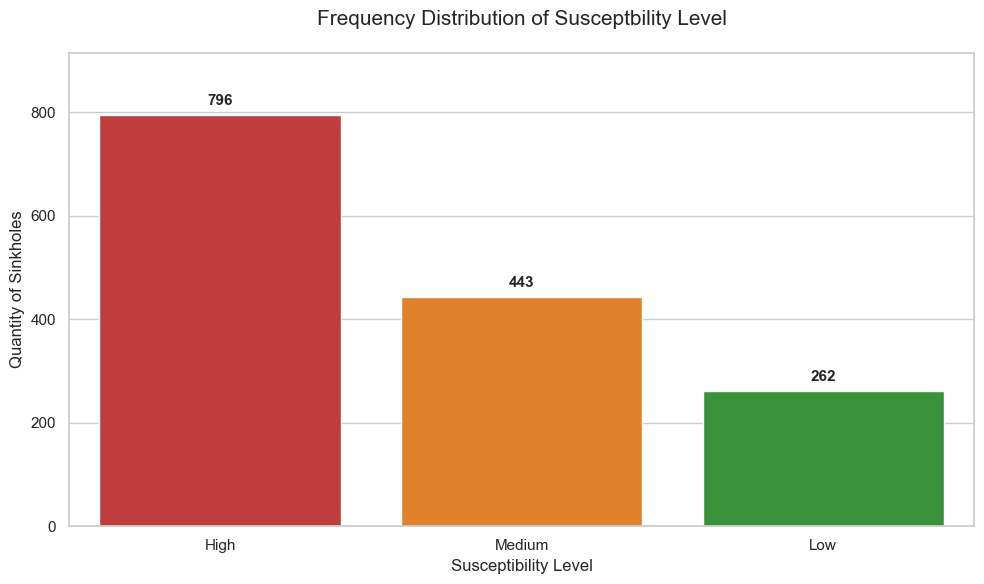

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración de parámetros
# Asegúrate de que estos nombres coincidan con los que creamos en el paso anterior
orden_niveles = ['High', 'Medium', 'Low']
colores_niveles = {'Low': '#2ca02c', 'Medium': '#ff7f0e', 'High': '#d62728'}

# 2. Crear la figura
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Generar el gráfico de barras
# Usamos hue=x para cumplir con las nuevas reglas de Seaborn y evitar advertencias
ax = sns.countplot(
    data=modelo_granular_susceptibilidad, 
    x='Discretization_Jenks', 
    order=orden_niveles, 
    hue='Discretization_Jenks', 
    palette=colores_niveles,
    legend=False
)

# 4. Personalizar títulos y etiquetas (sin usar formatos complejos)
plt.title('Frequency Distribution of Susceptbility Level', fontsize=15, pad=20)
plt.xlabel('Susceptibility Level', fontsize=12)
plt.ylabel('Quantity of Sinkholes', fontsize=12)

# 5. Añadir las etiquetas de conteo sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{int(altura)}', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='center', 
                    xytext=(0, 10), 
                    textcoords='offset points', 
                    fontsize=11, fontweight='bold')

# 6. Ajustar visualización
# Damos un poco más de aire en la parte superior para que quepan las etiquetas
plt.ylim(0, modelo_granular_susceptibilidad['Discretization_Jenks'].value_counts().max() * 1.15)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

# **VALIDACION DE MODELO**

In [108]:
modelo_granular_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 23 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   x_laea                               1501 non-null   float64 
 1   y_laea                               1501 non-null   float64 
 2   overburden_resistance_numeric        1501 non-null   int64   
 3   depth_drift_clean                    1501 non-null   float64 
 4   working_thickness_numeric            1501 non-null   float64 
 5   x_wgs84                              1501 non-null   float64 
 6   y_wgs84                              1501 non-null   float64 
 7   id_bd_sinkhole                       1501 non-null   object  
 8   distancia_promedio_al_vecino_m       1501 non-null   float64 
 9   depth_drift_norm                     1501 non-null   float64 
 10  working_thickness_norm               1501 non-null   float64 
 11  overburden_resistance_

## 1. ESTABILIDAD DEL MODELO

Ejecutando 100 simulaciones con Test Size=0.3...

--- STATISTICAL DESCRIPTION OF THRESHOLDS ---
        L1_Low_Medium  L2_Medium_High
mean         0.406598        0.573277
std          0.005886        0.001004
median       0.404407        0.573421
min          0.394896        0.571922
max          0.415536        0.578224


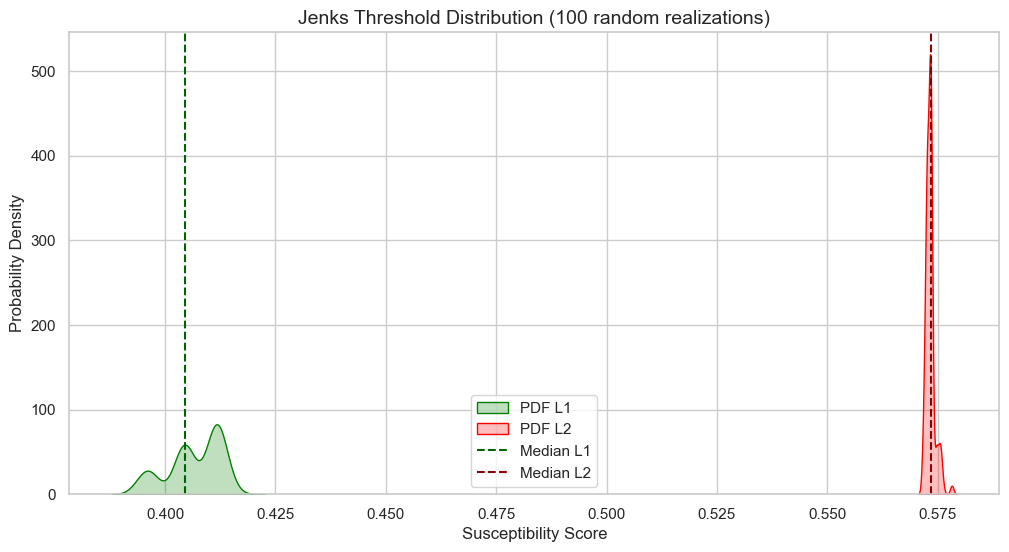

In [109]:
import pandas as pd
import jenkspy
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# 1. PARÁMETROS DE LA SIMULACIÓN
n_iteraciones = 100
porcentaje_test = 0.3  # Fijo al 30% para estabilidad
lista_l1 = []
lista_l2 = []

print(f"Ejecutando {n_iteraciones} simulaciones con Test Size={porcentaje_test}...")

for i in range(n_iteraciones):
    # Dividimos los datos usando una semilla (random_state) diferente en cada iteración
    train_sub, _ = train_test_split(
        modelo_granular_susceptibilidad, 
        test_size=porcentaje_test, 
        random_state=i 
    )
    
    # Extraemos los scores del set de entrenamiento
    scores_train = train_sub['Susceptibility_Score_Expert'].dropna().values
    
    # Calculamos las rupturas naturales de Jenks para 3 clases (Low, Medium, High)
    breaks = jenkspy.jenks_breaks(scores_train, n_classes=3)
    
    # Guardamos L1 (Low-Medium) y L2 (Medium-High)
    lista_l1.append(breaks[1])
    lista_l2.append(breaks[2])

# 2. CONSOLIDACIÓN DE RESULTADOS
df_estabilidad = pd.DataFrame({
    'L1_Low_Medium': lista_l1,
    'L2_Medium_High': lista_l2
})

# Calculamos estadísticas descriptivas
stats = df_estabilidad.describe().loc[['mean', 'std', '50%', 'min', 'max']]
stats.rename(index={'50%': 'median'}, inplace=True)

print("\n--- STATISTICAL DESCRIPTION OF THRESHOLDS ---")
print(stats)

# 3. VISUALIZACIÓN DE LA SENSIBILIDAD
plt.figure(figsize=(12, 6))
sns.kdeplot(df_estabilidad['L1_Low_Medium'], fill=True, color='green', label='PDF L1')
sns.kdeplot(df_estabilidad['L2_Medium_High'], fill=True, color='red', label='PDF L2')

plt.axvline(stats.loc['median', 'L1_Low_Medium'], color='darkgreen', linestyle='--', label='Median L1')
plt.axvline(stats.loc['median', 'L2_Medium_High'], color='darkred', linestyle='--', label='Median L2')

plt.title('Jenks Threshold Distribution (100 random realizations)', fontsize=14)
plt.xlabel('Susceptibility Score')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

## 2. EMPAQUETAMIENTO DEL MODELO (.pkl)

In [110]:
modelo_granular_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 23 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   x_laea                               1501 non-null   float64 
 1   y_laea                               1501 non-null   float64 
 2   overburden_resistance_numeric        1501 non-null   int64   
 3   depth_drift_clean                    1501 non-null   float64 
 4   working_thickness_numeric            1501 non-null   float64 
 5   x_wgs84                              1501 non-null   float64 
 6   y_wgs84                              1501 non-null   float64 
 7   id_bd_sinkhole                       1501 non-null   object  
 8   distancia_promedio_al_vecino_m       1501 non-null   float64 
 9   depth_drift_norm                     1501 non-null   float64 
 10  working_thickness_norm               1501 non-null   float64 
 11  overburden_resistance_

In [111]:
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1475 non-null   object 
 1   geology_of_the_overburden      1475 non-null   object 
 2   material_overbuden_resistance  430 non-null    object 
 3   resistance_numeric             426 non-null    float64
 4   text_for_ml                    1475 non-null   object 
 5   target_res                     426 non-null    float64
 6   cluster                        1475 non-null   int32  
 7   overburden_resistance_numeric  1475 non-null   float64
 8   resistencia_imputada           1475 non-null   object 
dtypes: float64(3), int32(1), object(5)
memory usage: 98.1+ KB


# PRUEBAS DE EMPAQUETAMIENTO

Esto es para probar que el flujo funciona

### VERSION 1. MODELO NO SUPERVISADO PARA RESISTENCIA CON K-MEANS

In [112]:
import numpy as np
import jenkspy
import pickle

print("Empaquetando Resultados Susceptibility Model V 1.0 (Incluye NLP)...")

# 1. PARÁMETROS DE NORMALIZACIÓN (Profundidad y Espesor)
# 1.1. Para profundidad (Log-Inverse Min-Max)
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'].dropna())
log_min_depth, log_max_depth = log_depth.min(), log_depth.max()

# 1.2. Para espesor (Normalizacion linear Min-Max)
thick_min = modelo_granular_susceptibilidad['working_thickness_numeric'].min()
thick_max = modelo_granular_susceptibilidad['working_thickness_numeric'].max()

# 2. UMBRALES MAESTROS JENKS (usando TODOS los datos de la base de datos o catalogo)
scores_finales = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna().values
master_breaks = jenkspy.jenks_breaks(scores_finales, n_classes=3)

# 3. DICCIONARIO MAESTRO (AQUI SE INCLUYEN TODOS LOS RESULTADOS DEL ANALISIS DE SUSCEPTIBILIDAD)
pipeline_susceptibilidad_completo = {
    'version': '1.0_NLP_EndToEnd',
    
    # --- MÓDULO GEOLÓGICO (NLP + Clustering) ---
    # AQUI COLOCAMOS LAS VARIABLES QUE TIENEN TODA LA INFORMACION DEL ANALISIS:
    'nlp_vectorizer': vectorizer,
    'nlp_kmeans': kmeans,
    # Mapa que traduce el clúster (0, 1, 2, 3, 4) a resistencia (1, 2, 3)
    'mapa_cluster_resistencia': reglas_imputacion, 
    
    # --- MÓDULO DE SUSCEPTIBILIDAD ---
    # Pesos holisticos (Conocimiento Experto)
    'pesos': {'alpha': 0.4, # Profundidad
              'beta': 0.3, # Espesor de capa
              'gamma': 0.3 # Resistencia del overburden material
              },

    # Limites para la variable resistencia de material
    'mapeo_res_a_peso': {1: 0.7,
                         2: 0.35,
                         3: 0.10},
    
    # Parametros para profundidad y espesor de capa
    'parametros_normalizacion': {
        'depth_log_min': log_min_depth,
        'depth_log_max': log_max_depth,
        'thick_min': thick_min, 
        'thick_max': thick_max
    },
    
    # Umbrales definidos por Jenks Break
    'umbrales_jenks': {'L1': master_breaks[1], 'L2': master_breaks[2]}
}

# 4. EXPORTACIÓN EN DISCO (empaquetado)
nombre_archivo = 'pipeline_susceptibilidad_NLP_kmeans.pkl'
with open(nombre_archivo, 'wb') as f:
    pickle.dump(pipeline_susceptibilidad_completo, f)

print(f"✅ Pipeline exportado exitosamente en: {nombre_archivo}")

Empaquetando Resultados Susceptibility Model V 1.0 (Incluye NLP)...
✅ Pipeline exportado exitosamente en: pipeline_susceptibilidad_NLP_kmeans.pkl


#### OPCION 2. MODELO VERSION SUPERVISADA PARA RESISTENCIA CON RANDOM FOREST

In [113]:
modelo_granular_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1501 entries, 0 to 1867
Data columns (total 23 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   x_laea                               1501 non-null   float64 
 1   y_laea                               1501 non-null   float64 
 2   overburden_resistance_numeric        1501 non-null   int64   
 3   depth_drift_clean                    1501 non-null   float64 
 4   working_thickness_numeric            1501 non-null   float64 
 5   x_wgs84                              1501 non-null   float64 
 6   y_wgs84                              1501 non-null   float64 
 7   id_bd_sinkhole                       1501 non-null   object  
 8   distancia_promedio_al_vecino_m       1501 non-null   float64 
 9   depth_drift_norm                     1501 non-null   float64 
 10  working_thickness_norm               1501 non-null   float64 
 11  overburden_resistance_

In [114]:
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1475 entries, 0 to 1474
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1475 non-null   object 
 1   geology_of_the_overburden      1475 non-null   object 
 2   material_overbuden_resistance  430 non-null    object 
 3   resistance_numeric             426 non-null    float64
 4   text_for_ml                    1475 non-null   object 
 5   target_res                     426 non-null    float64
 6   cluster                        1475 non-null   int32  
 7   overburden_resistance_numeric  1475 non-null   float64
 8   resistencia_imputada           1475 non-null   object 
dtypes: float64(3), int32(1), object(5)
memory usage: 98.1+ KB


In [115]:
import numpy as np
import jenkspy
import pickle
from sklearn.ensemble import RandomForestClassifier

print("Empaquetando Modelo Supervisado (V 2.0 - Random Forest)...")

# 1. PARÁMETROS DE NORMALIZACIÓN (Profundidad y Espesor)
# Usando la variable actualizada 'depth_drift_clean'
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'].dropna())
log_min_depth, log_max_depth = log_depth.min(), log_depth.max()

# Para espesor (Normalizacion linear Min-Max)
thick_min = modelo_granular_susceptibilidad['working_thickness_numeric'].min()
thick_max = modelo_granular_susceptibilidad['working_thickness_numeric'].max()

# Umbrales Jenks
scores_finales = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna().values
master_breaks = jenkspy.jenks_breaks(scores_finales, n_classes=3)

# ==============================================================================
# 2. ENTRENAMIENTO DEL CLASIFICADOR SUPERVISADO
# ==============================================================================
# Usamos 'X_text' que ya está vectorizada y tiene el mismo número de filas que 'df_ml'
# Como variable objetivo, usamos la columna FINAL post-imputación K-Means
y_train_res = df_ml['overburden_resistance_numeric'].astype(int)

# Entrenamos con class_weight='balanced' para obligar al modelo a detectar la Resistencia 3
rf_classifier = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)
rf_classifier.fit(X_text, y_train_res)

# ==============================================================================
# 3. DICCIONARIO MAESTRO V2
# ==============================================================================
pipeline_supervisado = {
    'version': '2.0_NLP_Supervised',
    
    # --- MÓDULO GEOLÓGICO SUPERVISADO ---
    'nlp_vectorizer': vectorizer,
    'nlp_classifier': rf_classifier,
    
    # --- MÓDULO DE SUSCEPTIBILIDAD ---
    # Pesos holisticos (Conocimiento Experto)
    'pesos': {'alpha': 0.4,   # Profundidad
              'beta': 0.3,    # Espesor de capa
              'gamma': 0.3},  # Resistencia del material
              
    # Limites para la variable resistencia de material
    'mapeo_res_a_peso': {1: 0.70, 
                         2: 0.35, 
                         3: 0.10},
    
    # Parametros para profundidad y espesor
    'parametros_normalizacion': {
        'depth_log_min': log_min_depth,
        'depth_log_max': log_max_depth,
        'thick_min': thick_min, 
        'thick_max': thick_max
    },
    
    # Umbrales definidos por Jenks Break
    'umbrales_jenks': {'L1': master_breaks[1], 'L2': master_breaks[2]}
}

# ==============================================================================
# 4. EXPORTACIÓN EN DISCO
# ==============================================================================
nombre_archivo_v2 = 'pipeline_susceptibilidad_NLP_randomforest.pkl'

with open(nombre_archivo_v2, 'wb') as f:
    pickle.dump(pipeline_supervisado, f)

print(f"✅ Pipeline V2 exportado exitosamente en: {nombre_archivo_v2}")

Empaquetando Modelo Supervisado (V 2.0 - Random Forest)...
✅ Pipeline V2 exportado exitosamente en: pipeline_susceptibilidad_NLP_randomforest.pkl


In [116]:
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'])
log_min_depth, log_max_depth = log_depth.min(), log_depth.max()
log_max_depth


np.float64(6.698268054115413)

# MODELO DE MAGNITUD

In [117]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 31 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1868 non-null   object 
 1   name                                          1468 non-null   object 
 2   id_sinkhole                                   1449 non-null   object 
 3   coordinate
x                                  1868 non-null   float64
 4   coordinate
y                                  1868 non-null   float64
 5   x_wgs84                                       1868 non-null   float64
 6   y_wgs84                                       1868 non-null   float64
 7   name_of_the_mine                              1868 non-null   object 
 8   country                                       1868 non-null   object 
 9   municipality                                  1866 non-null   o

In [118]:
df_risk[["id_bd_sinkhole", "length_diameter_m", "depth_of_the_sinkhole_m", "origin_of_collapse", "number_of_sinkholes"]]

,id_bd_sinkhole,length_diameter_m,depth_of_the_sinkhole_m,origin_of_collapse,number_of_sinkholes
0,FR-SIN-08,1,0.5,NaN,1
1,FR-SIN-09,0.5,0.5,NaN,1
2,FR-SIN-10,15,1.2,NaN,1
3,FR-SIN-11,4,1.5,NaN,1
4,FR-SIN-12,3,1,NaN,1
...,...,...,...,...,...
1863,POL-SIN-962,5,1.5,Faillure of the roof room or roof gallery,9
1864,POL-SIN-963,1.2,2.5,Faillure of the roof room or roof gallery,2
1865,POL-SIN-964,1.2,1.5,Faillure of the roof room or roof gallery,3
1866,POL-SIN-965,1,1.5,Faillure of the roof room or roof gallery,4


In [119]:
from pyproj import Transformer

# Creamos el transformador de WGS84 (4326) a ETRS89-LAEA (3035)
# Nota: pyproj usa (lat, lon) o (y, x) según el estándar
transformer = Transformer.from_crs("epsg:4326", "epsg:3035", always_xy=True)

# 2. Convertimos las coordenadas a metros europeos
# x_wgs84 es longitud, y_wgs84 es latitud
df_risk['x_laea'], df_risk['y_laea'] = transformer.transform(
    df_risk['x_wgs84'].values, 
    df_risk['y_wgs84'].values
)

# Limpieza de variables

Se realiza la limpieza de las 4 variables:

- origin_of_colapse: Que todas las descripciones esten en minuscula + quitar palabras que representan valores nulos por NaN
- Limpieza numerica: dejar todos los valores en su unidad respectiva (todo en metros) y quitar simbolos >, -, etc

In [120]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 26 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   id_bd_sinkhole                                1868 non-null   object  
 1   x_wgs84                                       1868 non-null   float64 
 2   y_wgs84                                       1868 non-null   float64 
 3   number_of_sinkholes                           1841 non-null   object  
 4   length_diameter_m                             1724 non-null   object  
 5   depth_of_the_sinkhole_m                       1642 non-null   object  
 6   in-situ_measurement_or_estimation             1683 non-null   object  
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object  
 8   origin_of_collapse                            1778 non-null   object  
 9   start_date_of_the_mining                      1838 n

In [121]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

print("Iniciando EDA para el Modelo de Magnitud...\n")

# 1. FUNCIONES DE LIMPIEZA (Para extraer números de textos como "1.5-2.0")
def limpiar_numerica(val):
    val_str = str(val).lower().strip()
    
    # 1. Filtro de nulos/texto vacío
    if val_str in ['unknown', 'unknow', 'non disponible', 'several', 'sevral', 'nan', 'none', '']:
        return np.nan
    
    # 2. Estandarizar decimales y limpiar símbolos matemáticos
    val_str = val_str.replace(',', '.')
    val_str = val_str.replace('>', '').replace('<', '').replace('~', '')
    
    # 3. Identificar unidades para la conversión (Todo se pasa a metros)
    multiplier = 1.0
    if 'cm' in val_str:
        multiplier = 0.01
    elif 'mm' in val_str:
        multiplier = 0.001
    
    # 4. Estandarizar separadores de rango (convertimos "à" y "to" en un guion "-")
    val_str = re.sub(r'\s*à\s*', '-', val_str)
    val_str = re.sub(r'\s*to\s*', '-', val_str)
    
    # 5. Extraer Rangos (ej. 2 - 5)
    rangos = re.findall(r'(\d+\.?\d*)\s*-\s*(\d+\.?\d*)', val_str)
    if rangos:
        promedio = (float(rangos[0][0]) + float(rangos[0][1])) / 2.0
        return promedio * multiplier
        
    # 6. Extraer Número Único (ej. 10)
    numeros = re.findall(r'(\d+\.?\d*)', val_str)
    if numeros:
        return float(numeros[0]) * multiplier
        
    return np.nan

def limpiar_categorica(val):
    val_str = str(val).lower().strip()
    # Lista de palabras que equivalen a un dato faltante
    if val_str in ['unknown', 'unknow', 'Unknow', 'Unknown', 'non disponible', 'several', 'sevral', 'nan', '', 'none']:
        return np.nan
    return val_str

# 2. LIMPIEZA DE VARIABLES DE MAGNITUD
# Asumiendo que tu dataframe original filtrado se llama 'df_risk'
df_mag = df_risk[["id_bd_sinkhole", "x_laea", "y_laea", "length_diameter_m", "depth_of_the_sinkhole_m", "origin_of_collapse", "number_of_sinkholes"]].copy()

df_mag['number_sinkholes_clean'] = df_mag['number_of_sinkholes'].apply(limpiar_numerica)
df_mag['diameter_sinkhole_clean'] = df_mag['length_diameter_m'].apply(limpiar_numerica)
df_mag['depth_sinkhole_clean'] = df_mag['depth_of_the_sinkhole_m'].apply(limpiar_numerica)
df_mag['origin_collapse_clean'] = df_mag['origin_of_collapse'].apply(limpiar_categorica)

# 3. REPORTE DE DATOS ÚTILES (Completitud)
total_registros = len(df_mag)
print(f"Total de registros históricos: {total_registros}")
print(f"Diámetros reportados: {df_mag['diameter_sinkhole_clean'].notna().sum()} ({(df_mag['diameter_sinkhole_clean'].notna().sum()/total_registros)*100:.1f}%)")
print(f"Profundidades de cráter: {df_mag['depth_sinkhole_clean'].notna().sum()} ({(df_mag['depth_sinkhole_clean'].notna().sum()/total_registros)*100:.1f}%)")

Iniciando EDA para el Modelo de Magnitud...

Total de registros históricos: 1868
Diámetros reportados: 1263 (67.6%)
Profundidades de cráter: 1547 (82.8%)


In [122]:
df_mag[df_mag["id_bd_sinkhole"] == "FR-SIN-124"]

,id_bd_sinkhole,x_laea,y_laea,length_diameter_m,depth_of_the_sinkhole_m,origin_of_collapse,number_of_sinkholes,number_sinkholes_clean,diameter_sinkhole_clean,depth_sinkhole_clean,origin_collapse_clean
116,FR-SIN-124,3.745295e+06,2.576107e+06,1,>2,Faillure of the roof gallery,1,1.0,1.0,2.0,faillure of the roof gallery


In [123]:
df_mag.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_bd_sinkhole           1868 non-null   object 
 1   x_laea                   1868 non-null   float64
 2   y_laea                   1868 non-null   float64
 3   length_diameter_m        1724 non-null   object 
 4   depth_of_the_sinkhole_m  1642 non-null   object 
 5   origin_of_collapse       1778 non-null   object 
 6   number_of_sinkholes      1841 non-null   object 
 7   number_sinkholes_clean   1835 non-null   float64
 8   diameter_sinkhole_clean  1263 non-null   float64
 9   depth_sinkhole_clean     1547 non-null   float64
 10  origin_collapse_clean    1353 non-null   object 
dtypes: float64(5), object(6)
memory usage: 160.7+ KB


# Depth of the Sinkhole

In [124]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- EDA: PROFUNDIDAD DEL SINKHOLE ---")

# 1. Estadísticas Descriptivas Básicas
stats_depth = df_mag['depth_sinkhole_clean'].describe()
nulos_depth = df_mag['depth_sinkhole_clean'].isna().sum()
total_depth = len(df_mag)
porcentaje_util = (stats_depth['count'] / total_depth) * 100

print(f"Total de registros en BD: {total_depth}")
print(f"Datos válidos: {int(stats_depth['count'])} ({porcentaje_util:.1f}%)")
print(f"Datos nulos: {nulos_depth}\n")
print("Estadísticas:")
print(stats_depth.round(2))

--- EDA: PROFUNDIDAD DEL SINKHOLE ---
Total de registros en BD: 1868
Datos válidos: 1547 (82.8%)
Datos nulos: 321

Estadísticas:
count    1547.00
mean        2.13
std         3.08
min         0.00
25%         0.50
50%         1.50
75%         2.60
max        40.00
Name: depth_sinkhole_clean, dtype: float64


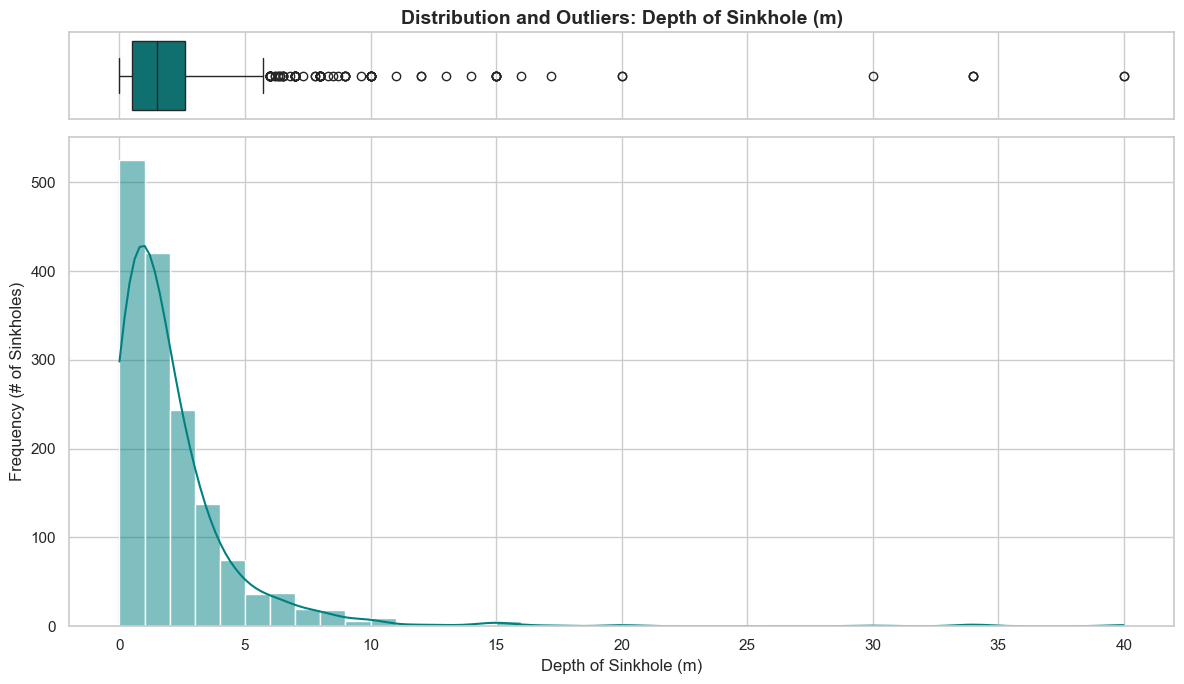

In [125]:
# 2. Configuración del Gráfico (Boxplot arriba, Histograma abajo)
sns.set_theme(style="whitegrid")
fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, 
                                      gridspec_kw={"height_ratios": (.15, .85)}, 
                                      figsize=(12, 7))

# A. Boxplot (Para detectar Outliers)
sns.boxplot(x=df_mag['depth_sinkhole_clean'], ax=ax_box, color='teal')
ax_box.set(xlabel='')
ax_box.set_title('Distribution and Outliers: Depth of Sinkhole (m)', fontsize=14, fontweight='bold')

# B. Histograma + Curva KDE (Para ver la forma de la distribución)
sns.histplot(df_mag['depth_sinkhole_clean'].dropna(), bins=40, kde=True, color='teal', ax=ax_hist)
ax_hist.set_xlabel('Depth of Sinkhole (m)', fontsize=12)
ax_hist.set_ylabel('Frequency (# of Sinkholes)', fontsize=12)

plt.tight_layout()
plt.show()

# Diameter of Sinkhole

In [126]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- EDA: DIÁMETRO DEL SINKHOLE ---")

# 1. Estadísticas Descriptivas Básicas
stats_diam = df_mag['diameter_sinkhole_clean'].describe()
nulos_diam = df_mag['diameter_sinkhole_clean'].isna().sum()
total_diam = len(df_mag)
porcentaje_util_diam = (stats_diam['count'] / total_diam) * 100

print(f"Total de registros en BD: {total_diam}")
print(f"Datos válidos: {int(stats_diam['count'])} ({porcentaje_util_diam:.1f}%)")
print(f"Datos nulos: {nulos_diam}\n")
print("Estadísticas:")
print(stats_diam.round(2))

--- EDA: DIÁMETRO DEL SINKHOLE ---
Total de registros en BD: 1868
Datos válidos: 1263 (67.6%)
Datos nulos: 605

Estadísticas:
count    1263.00
mean        6.29
std         9.57
min         0.10
25%         2.00
50%         4.00
75%         8.00
max       180.00
Name: diameter_sinkhole_clean, dtype: float64


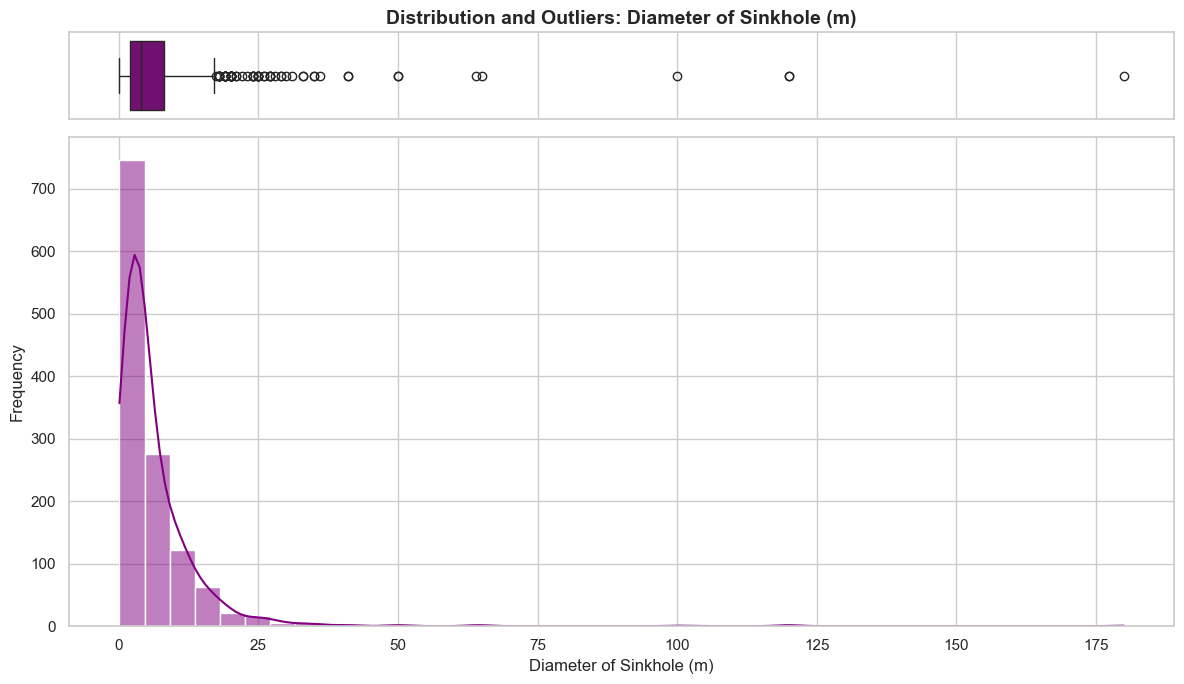

In [127]:
# 2. Configuración del Gráfico (Boxplot arriba, Histograma abajo)
sns.set_theme(style="whitegrid")
fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, 
                                      gridspec_kw={"height_ratios": (.15, .85)}, 
                                      figsize=(12, 7))

# A. Boxplot (Para detectar Outliers)
sns.boxplot(x=df_mag['diameter_sinkhole_clean'], ax=ax_box, color='purple')
ax_box.set(xlabel='')
ax_box.set_title('Distribution and Outliers: Diameter of Sinkhole (m)', fontsize=14, fontweight='bold')

# B. Histograma + Curva KDE (Para ver la forma de la distribución)
sns.histplot(df_mag['diameter_sinkhole_clean'].dropna(), bins=40, kde=True, color='purple', ax=ax_hist)
ax_hist.set_xlabel('Diameter of Sinkhole (m)', fontsize=12)
ax_hist.set_ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()



# Origin of Collapse

In [128]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- EDA: ORIGIN OF COLLAPSE ---")

# 1. Frecuencias y Completitud
total_origin = len(df_mag)
nulos_origin = df_mag['origin_collapse_clean'].isna().sum()
validos_origin = total_origin - nulos_origin
porcentaje_util_origin = (validos_origin / total_origin) * 100

print(f"Total de registros en BD: {total_origin}")
print(f"Datos válidos: {validos_origin} ({porcentaje_util_origin:.1f}%)")
print(f"Datos nulos: {nulos_origin}\n")

# 2. Tabla de Frecuencias Absolutas y Relativas
frecuencias = df_mag['origin_collapse_clean'].value_counts()
porcentajes = df_mag['origin_collapse_clean'].value_counts(normalize=True) * 100

df_frecuencias = pd.DataFrame({
    'Cantidad': frecuencias,
    'Porcentaje (%)': porcentajes.round(1)
})

print("--- Distribución de los Tipos de Origen ---")
print(df_frecuencias.head(10)) # Mostramos los 10 más comunes

--- EDA: ORIGIN OF COLLAPSE ---
Total de registros en BD: 1868
Datos válidos: 1353 (72.4%)
Datos nulos: 515

--- Distribución de los Tipos de Origen ---
                                           Cantidad  Porcentaje (%)
origin_collapse_clean                                              
faillure of the roof room or roof gallery       875            64.7
faillure of the roof gallery                    292            21.6
collapse of the shaft filling material          117             8.6
faillure of the roof room                        43             3.2
failure of the shaft head                        15             1.1
pillar failure                                    6             0.4
karst                                             3             0.2
collapse of the surface                           1             0.1
suffosion                                         1             0.1


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\3744991644.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


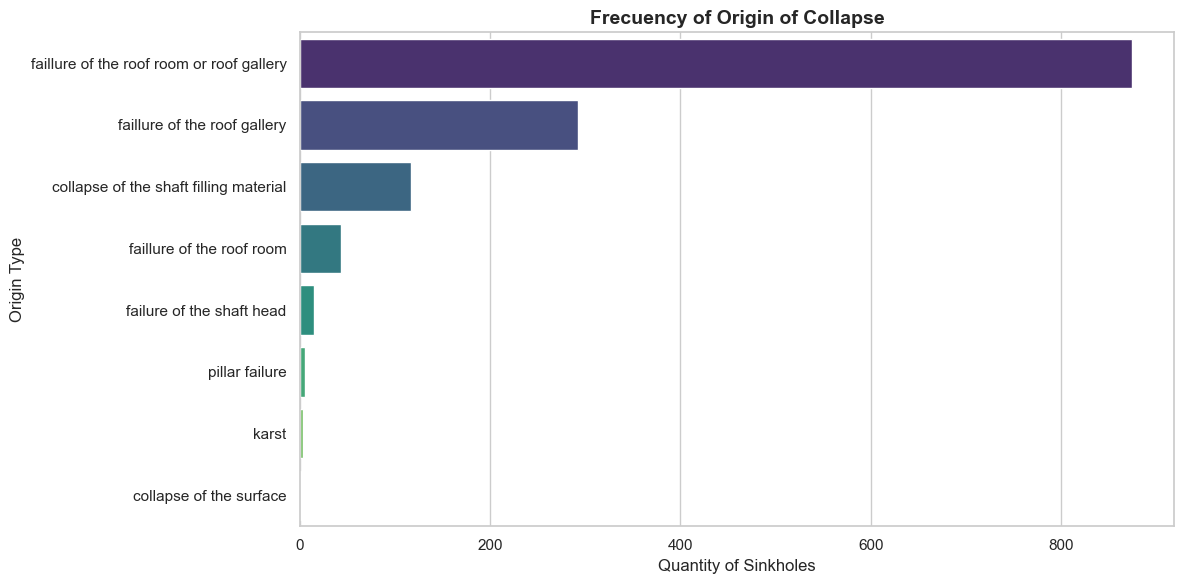

In [129]:
# 3. Visualización (Gráfico de Barras Horizontal)
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Filtramos los top 8 orígenes para que el gráfico no se sature de categorías raras
top_n = frecuencias.head(8).index
df_plot_origin = df_mag[df_mag['origin_collapse_clean'].isin(top_n)]

sns.countplot(
    data=df_plot_origin,
    y='origin_collapse_clean',
    order=top_n,
    palette='viridis'
)
plt.title('Frecuency of Origin of Collapse', fontsize=14, fontweight='bold')
plt.xlabel('Quantity of Sinkholes', fontsize=12)
plt.ylabel('Origin Type', fontsize=12)
plt.tight_layout()
plt.show()

In [130]:
# 4. Cruce de Variables: Origen vs. Magnitud Física
print("\n--- Impacto del Origen en la Magnitud FÍSICA (Medianas) ---")
# Calculamos la mediana del diámetro y profundidad para cada tipo de origen
impacto_origen = df_mag.groupby('origin_collapse_clean')[['diameter_sinkhole_clean', 'depth_sinkhole_clean']].median()

# Añadimos el conteo para dar contexto (no es lo mismo una mediana de 1 dato que de 100)
impacto_origen['Conteo'] = df_mag.groupby('origin_collapse_clean').size()

# Ordenamos por el diámetro de mayor a menor para ver cuáles son los más destructivos
impacto_origen = impacto_origen.sort_values(by='diameter_sinkhole_clean', ascending=False)
impacto_origen[impacto_origen['Conteo'] >= 5].head(10) # Filtramos los que tienen al menos 5 casos


--- Impacto del Origen en la Magnitud FÍSICA (Medianas) ---


,diameter_sinkhole_clean,depth_sinkhole_clean,Conteo
origin_collapse_clean,,,
faillure of the roof room or roof gallery,5.00,2.0,875
failure of the shaft head,4.50,3.0,15
faillure of the roof room,3.00,2.0,43
faillure of the roof gallery,3.00,1.5,292
collapse of the shaft filling material,3.00,1.5,117
pillar failure,1.75,2.0,6


# Number of Sinkholes

C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\390126592.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


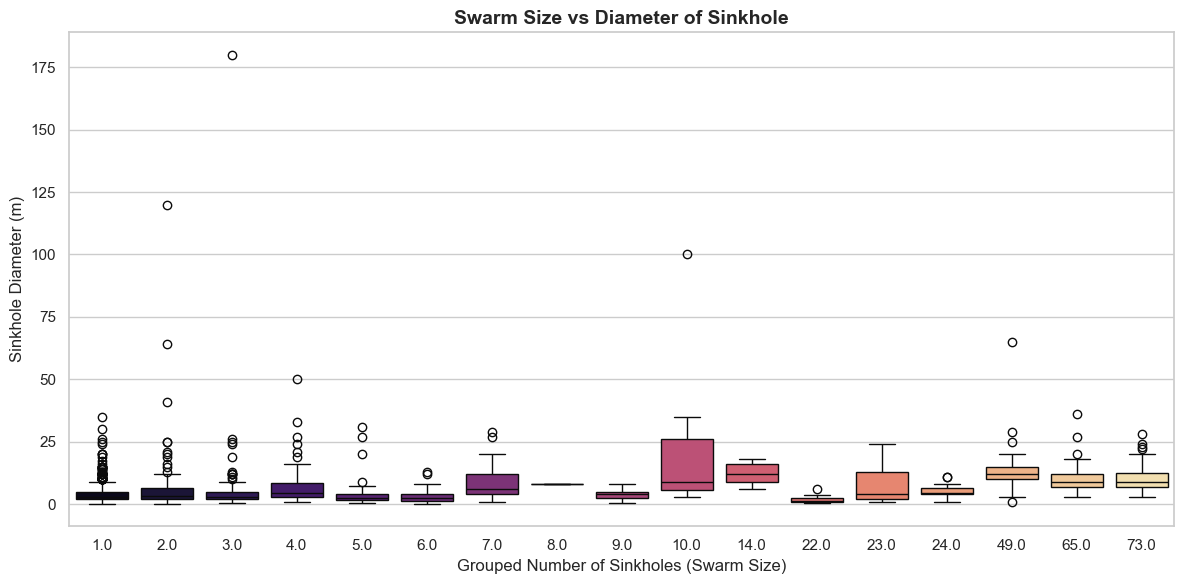


--- Relación: Enjambres y Origen del Colapso ---
                                           median       mean   max  count
origin_collapse_clean                                                    
faillure of the roof room or roof gallery     5.0  18.351259  73.0    874
collapse of the shaft filling material        1.0   2.120690  23.0    116
faillure of the roof gallery                  1.0   1.586806  23.0    288
faillure of the roof room                     1.0   1.139535   5.0     43
pillar failure                                3.0   2.333333   3.0      6
collapse of the surface                       1.0   1.000000   1.0      1
failure of the shaft head                     1.0   1.000000   1.0     15
karst                                         1.0   1.000000   1.0      3


In [131]:
# 1. Limpieza rápida (asegurarnos de descartar nulos en esta variable)
df_swarm = df_mag.dropna(subset=['number_sinkholes_clean']).copy()

# 2. VISUALIZACIÓN: ¿El enjambre afecta el diámetro físico?
# Aquí sí usamos los datos sin agrupar, porque queremos saber el diámetro de CADA hueco individual
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Filtramos hasta enjambres de 10 para que el gráfico sea legible (puedes ajustar este filtro)
df_plot_swarm = df_swarm[df_swarm['number_sinkholes_clean'] <= 200]

sns.boxplot(
    data=df_plot_swarm, 
    x='number_sinkholes_clean', 
    y='diameter_sinkhole_clean', 
    palette='magma'
)

plt.title('Swarm Size vs Diameter of Sinkhole', fontsize=14, fontweight='bold')
plt.xlabel('Grouped Number of Sinkholes (Swarm Size)', fontsize=12)
plt.ylabel('Sinkhole Diameter (m)', fontsize=12)
plt.tight_layout()
plt.show()

# 4. CRUCE DE VARIABLES (Enjambres vs Origen)
print("\n--- Relación: Enjambres y Origen del Colapso ---")
# ¿Los enjambres suelen ocurrir en galerías o en pozos?
relacion_origen = df_swarm.groupby('origin_collapse_clean')['number_sinkholes_clean'].agg(['median', 'mean', 'max', 'count'])
print(relacion_origen.sort_values(by='max', ascending=False).head(8))

In [132]:
df_mag.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_bd_sinkhole           1868 non-null   object 
 1   x_laea                   1868 non-null   float64
 2   y_laea                   1868 non-null   float64
 3   length_diameter_m        1724 non-null   object 
 4   depth_of_the_sinkhole_m  1642 non-null   object 
 5   origin_of_collapse       1778 non-null   object 
 6   number_of_sinkholes      1841 non-null   object 
 7   number_sinkholes_clean   1835 non-null   float64
 8   diameter_sinkhole_clean  1263 non-null   float64
 9   depth_sinkhole_clean     1547 non-null   float64
 10  origin_collapse_clean    1353 non-null   object 
dtypes: float64(5), object(6)
memory usage: 160.7+ KB


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\451215610.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


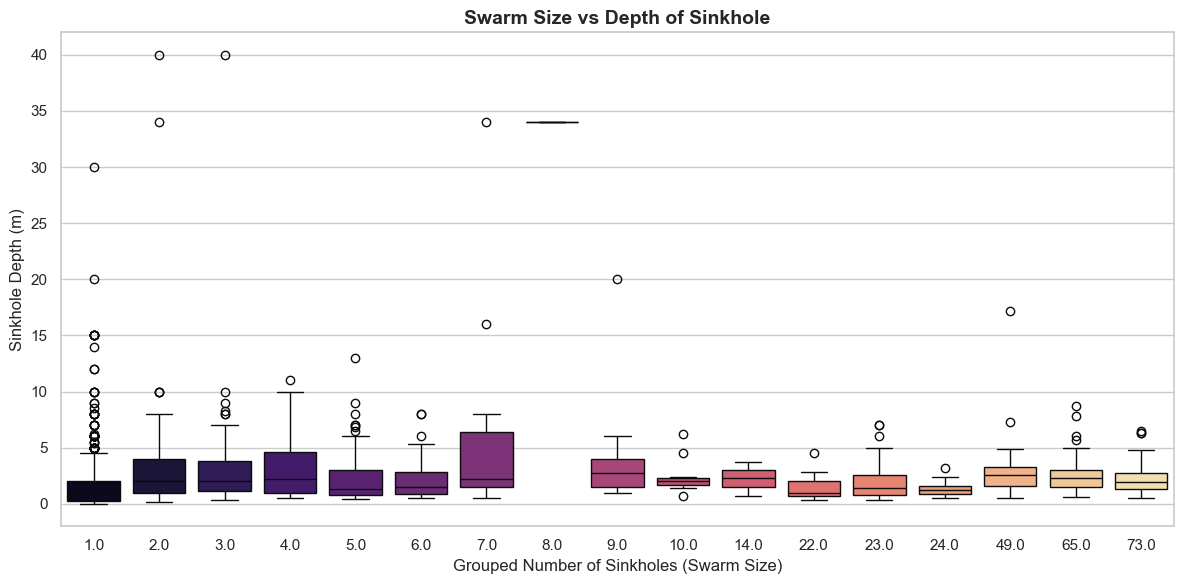


--- Relación: Enjambres y Origen del Colapso ---
                                           median       mean   max
origin_collapse_clean                                             
faillure of the roof room or roof gallery     5.0  18.351259  73.0
collapse of the shaft filling material        1.0   2.120690  23.0
faillure of the roof gallery                  1.0   1.586806  23.0
faillure of the roof room                     1.0   1.139535   5.0
pillar failure                                3.0   2.333333   3.0
collapse of the surface                       1.0   1.000000   1.0
failure of the shaft head                     1.0   1.000000   1.0
karst                                         1.0   1.000000   1.0


In [133]:
# 1. Limpieza rápida (asegurarnos de descartar nulos en esta variable)
df_swarm = df_mag.dropna(subset=['number_sinkholes_clean']).copy()

# 2. VISUALIZACIÓN: ¿El enjambre afecta el diámetro físico?
# Aquí sí usamos los datos sin agrupar, porque queremos saber el diámetro de CADA hueco individual
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Filtramos hasta enjambres de 10 para que el gráfico sea legible (puedes ajustar este filtro)
df_plot_swarm = df_swarm[df_swarm['number_sinkholes_clean'] <= 200]

sns.boxplot(
    data=df_plot_swarm, 
    x='number_sinkholes_clean', 
    y='depth_sinkhole_clean', 
    palette='magma'
)

plt.title('Swarm Size vs Depth of Sinkhole', fontsize=14, fontweight='bold')
plt.xlabel('Grouped Number of Sinkholes (Swarm Size)', fontsize=12)
plt.ylabel('Sinkhole Depth (m)', fontsize=12)
plt.tight_layout()
plt.show()

# 4. CRUCE DE VARIABLES (Enjambres vs Origen)
print("\n--- Relación: Enjambres y Origen del Colapso ---")
# ¿Los enjambres suelen ocurrir en galerías o en pozos?
relacion_origen = df_swarm.groupby('origin_collapse_clean')['number_sinkholes_clean'].agg(['median', 'mean', 'max'])
print(relacion_origen.sort_values(by='max', ascending=False).head(8))

In [134]:
print("--- AUDITORÍA ESPACIAL DE ENJAMBRES (VERSIÓN ESTRICTA) ---")

# 1. Preparar DataFrame (aseguramos que no haya nulos en las variables clave)
df_spatial = df_mag.dropna(subset=['x_laea', 'y_laea', 'number_sinkholes_clean']).copy()
df_spatial.info()


--- AUDITORÍA ESPACIAL DE ENJAMBRES (VERSIÓN ESTRICTA) ---
<class 'pandas.core.frame.DataFrame'>
Index: 1835 entries, 0 to 1867
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_bd_sinkhole           1835 non-null   object 
 1   x_laea                   1835 non-null   float64
 2   y_laea                   1835 non-null   float64
 3   length_diameter_m        1695 non-null   object 
 4   depth_of_the_sinkhole_m  1615 non-null   object 
 5   origin_of_collapse       1747 non-null   object 
 6   number_of_sinkholes      1835 non-null   object 
 7   number_sinkholes_clean   1835 non-null   float64
 8   diameter_sinkhole_clean  1235 non-null   float64
 9   depth_sinkhole_clean     1521 non-null   float64
 10  origin_collapse_clean    1347 non-null   object 
dtypes: float64(5), object(6)
memory usage: 172.0+ KB


--- EJECUTANDO ALGORITMO KNN PARA AUDITORÍA DE ENJAMBRES ---

--- TOP 15: ENJAMBRES CON MAYOR EXTENSIÓN FÍSICA ---
 ID_Evento_Real  number_sinkholes_clean  Distancia_Max_Cluster_km
           1191                       5                  1349.259
           1180                       4                  1340.264
           1215                      10                  1312.385
           1148                       3                  1292.331
           1077                       2                  1253.999
           1221                      49                   259.386
           1076                       2                    61.544
           1214                       9                    19.775
           1188                       4                    19.474
           1197                       5                    19.175
           1160                       3                    19.145
           1208                       6                     6.546
           1187            

C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\1341062908.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=event_counts, x='Tamanio_Enjambre', y='Cantidad_Eventos', palette='magma')


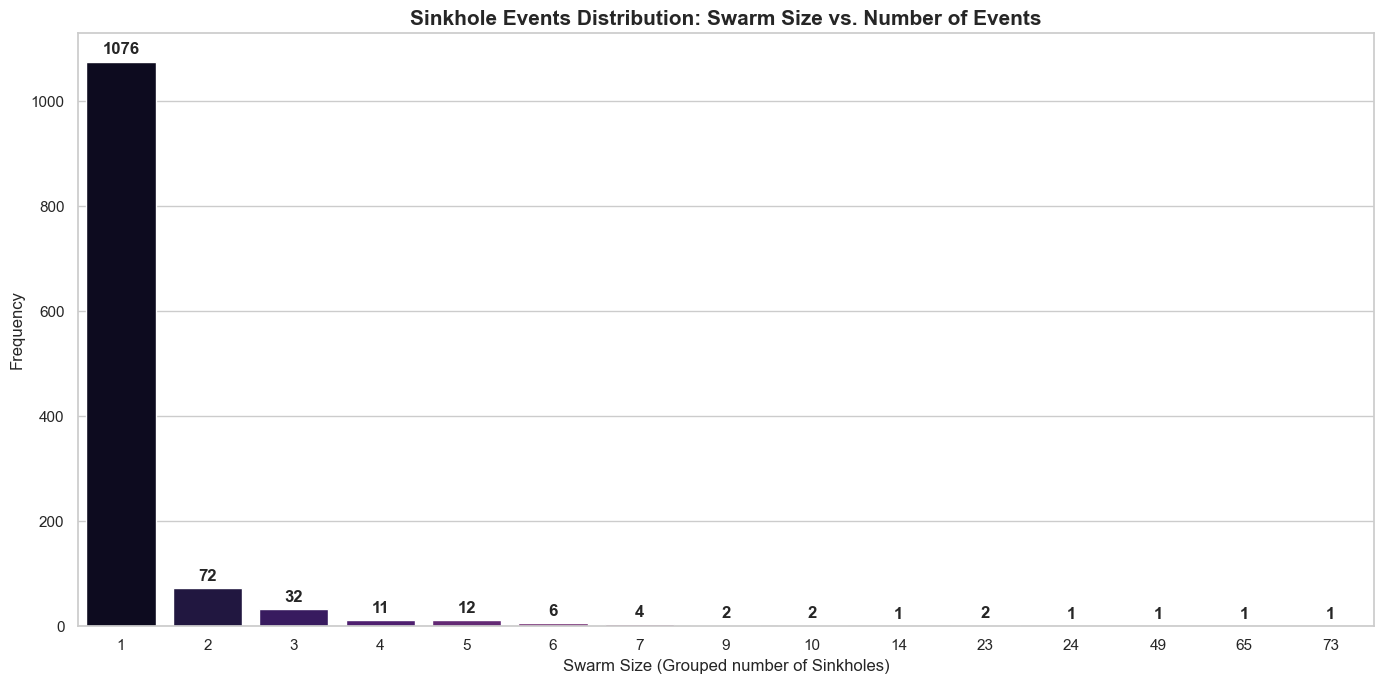

In [135]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

print("--- EJECUTANDO ALGORITMO KNN PARA AUDITORÍA DE ENJAMBRES ---")

# 1. Preparación de datos (Excluir nulos)
df_spatial = df_mag.dropna(subset=['x_laea', 'y_laea', 'number_sinkholes_clean']).copy()

# Variables para el tracking
df_spatial['ID_Evento_Real'] = -1
df_spatial['Distancia_Max_Cluster_m'] = 0.0
current_event_id = 0

# =================================================================================
# PASO A: Eventos aislados (Tamaño == 1)
# =================================================================================
mask_single = df_spatial['number_sinkholes_clean'] == 1
n_singles = mask_single.sum()
df_spatial.loc[mask_single, 'ID_Evento_Real'] = range(current_event_id, current_event_id + n_singles)
current_event_id += n_singles

# =================================================================================
# PASO B: Agrupamiento KNN para los Enjambres (> 1)
# =================================================================================
enjambres_df = df_spatial[df_spatial['number_sinkholes_clean'] > 1]
huerfanos_totales = 0

for n_sinkholes, group in enjambres_df.groupby('number_sinkholes_clean'):
    K = int(n_sinkholes)
    unassigned_idx = group.index.tolist()
    
    while len(unassigned_idx) > 0:
        # Si no alcanzan los puntos para formar el grupo de tamaño K, quedan huérfanos
        if len(unassigned_idx) < K:
            df_spatial.loc[unassigned_idx, 'ID_Evento_Real'] = -2 
            huerfanos_totales += len(unassigned_idx)
            break
            
        # Tomar "semilla" y buscar sus vecinos más cercanos
        seed_idx = unassigned_idx[0]
        seed_coords = df_spatial.loc[seed_idx, ['x_laea', 'y_laea']].values.astype(float).reshape(1, 2)
        candidate_coords = df_spatial.loc[unassigned_idx, ['x_laea', 'y_laea']].values.astype(float)
        
        distancias = cdist(seed_coords, candidate_coords)[0]
        closest_k_relative = np.argsort(distancias)[:K]
        closest_k_absolute = [unassigned_idx[i] for i in closest_k_relative]
        
        # Calcular extensión física (en metros) de este nuevo grupo
        cluster_coords = df_spatial.loc[closest_k_absolute, ['x_laea', 'y_laea']].values.astype(float)
        max_dist_in_cluster = np.max(cdist(cluster_coords, cluster_coords))
        
        # Registrar resultados
        df_spatial.loc[closest_k_absolute, 'ID_Evento_Real'] = current_event_id
        df_spatial.loc[closest_k_absolute, 'Distancia_Max_Cluster_m'] = max_dist_in_cluster
        
        current_event_id += 1
        
        # Remover los puntos agrupados de la lista de pendientes
        for idx in closest_k_absolute:
            unassigned_idx.remove(idx)

# =================================================================================
# PASO C: Generar Tabla de Extensión de Enjambres (En Kilómetros)
# =================================================================================
df_enjambres_formados = df_spatial[df_spatial['ID_Evento_Real'] >= n_singles].drop_duplicates('ID_Evento_Real').copy()
df_enjambres_formados['Distancia_Max_Cluster_km'] = df_enjambres_formados['Distancia_Max_Cluster_m'] / 1000

tabla_extension = df_enjambres_formados[['ID_Evento_Real', 'number_sinkholes_clean', 'Distancia_Max_Cluster_km']].sort_values('Distancia_Max_Cluster_km', ascending=False)
tabla_extension['number_sinkholes_clean'] = tabla_extension['number_sinkholes_clean'].astype(int)
tabla_extension['Distancia_Max_Cluster_km'] = tabla_extension['Distancia_Max_Cluster_km'].round(3)

print("\n--- TOP 15: ENJAMBRES CON MAYOR EXTENSIÓN FÍSICA ---")
print(tabla_extension.head(15).to_string(index=False))
print(f"\nResumen: {len(df_enjambres_formados)} enjambres agrupados | {huerfanos_totales} puntos huérfanos.")

# =================================================================================
# PASO D: Gráfico de Barras (Tamaño vs Cantidad Real de Eventos)
# =================================================================================
# Agrupamos todos los eventos (aislados + enjambres válidos)
df_all_events = df_spatial[df_spatial['ID_Evento_Real'] >= 0].drop_duplicates('ID_Evento_Real')
event_counts = df_all_events['number_sinkholes_clean'].value_counts().reset_index()
event_counts.columns = ['Tamanio_Enjambre', 'Cantidad_Eventos']
event_counts['Tamanio_Enjambre'] = event_counts['Tamanio_Enjambre'].astype(int)
event_counts = event_counts.sort_values('Tamanio_Enjambre')

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Crear el gráfico de barras
ax = sns.barplot(data=event_counts, x='Tamanio_Enjambre', y='Cantidad_Eventos', palette='magma')

plt.title('Sinkhole Events Distribution: Swarm Size vs. Number of Events', fontsize=15, fontweight='bold')
plt.xlabel('Swarm Size (Grouped number of Sinkholes)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Añadir las etiquetas numéricas exactas sobre cada barra
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

# MODELO DE PROBABILIDAD CONDICIONAL - MAGNITUD

Para esto vamos a discretizar las variables directas de magnitud (depth_sinkohle, diameter_sinkhole y number_of_sinkholes) en valores de medio, alto y bajo para cada variable. Luego usamos V de Cramer para establecer una relacion de esas etiquetas de magnitud con las variables predictoras (pueden ser dip_of_exploited_layer, depth_of_the_drift, working_thinkness, etc). El analisis de V de Cramer y el p-value nos daran una medida de las variables mas significativas para predecir el comportamiento. Es necesario filtrar las variables mas poderosas que puedan servir como variables predictoras.

In [136]:
df_mag.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_bd_sinkhole           1868 non-null   object 
 1   x_laea                   1868 non-null   float64
 2   y_laea                   1868 non-null   float64
 3   length_diameter_m        1724 non-null   object 
 4   depth_of_the_sinkhole_m  1642 non-null   object 
 5   origin_of_collapse       1778 non-null   object 
 6   number_of_sinkholes      1841 non-null   object 
 7   number_sinkholes_clean   1835 non-null   float64
 8   diameter_sinkhole_clean  1263 non-null   float64
 9   depth_sinkhole_clean     1547 non-null   float64
 10  origin_collapse_clean    1353 non-null   object 
dtypes: float64(5), object(6)
memory usage: 160.7+ KB


In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- CONSTRUCCIÓN CALIBRADA DE LA VARIABLE OBJETIVO (MAGNITUD REAL) ---")

# 1. Definimos las funciones de umbrales calibradas con los histogramas
def evaluar_diametro(d):
    if pd.isna(d): return np.nan
    if d <= 3.0: return 1.0       # Baja
    elif d <= 8.0: return 2.0     # Media
    else: return 3.0              # Alta (> 8m)

def evaluar_profundidad(p):
    if pd.isna(p): return np.nan
    if p <= 1.0: return 1.0       # Baja
    elif p <= 3.0: return 2.0     # Media
    else: return 3.0              # Alta (> 3m)

def evaluar_enjambre(n):
    if pd.isna(n): return np.nan
    if n == 1: return 1.0         # Baja (1 sinkhole)
    elif n <= 5: return 2.0       # Media (2-5 sinkholes)
    else: return 3.0              # Alta (> 5 sinkholes)

# 2. Aplicamos las reglas
df_mag['score_diam'] = df_mag['diameter_sinkhole_clean'].apply(evaluar_diametro)
df_mag['score_depth'] = df_mag['depth_sinkhole_clean'].apply(evaluar_profundidad)
df_mag['score_number'] = df_mag['number_sinkholes_clean'].apply(evaluar_enjambre)

# 3. LÓGICA DEL PEOR ESCENARIO (Calculamos el máximo ignorando los nulos)
# OJO: Quitamos numero de sinkholes para tener una medida de la magnitud del sinkhole mas severa, mas robusta y confiable
df_mag['Magnitud_Score_Max'] = df_mag[['score_diam', 'score_depth']].max(axis=1) #, 'score_number']].max(axis=1)

# 4. Traducimos a Etiqueta Final
mapa_magnitud = {1.0: '1_Baja', 2.0: '2_Media', 3.0: '3_Alta'}
df_mag['Magnitud_Real'] = df_mag['Magnitud_Score_Max'].map(mapa_magnitud)

--- CONSTRUCCIÓN CALIBRADA DE LA VARIABLE OBJETIVO (MAGNITUD REAL) ---


In [138]:
df_mag.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_bd_sinkhole           1868 non-null   object 
 1   x_laea                   1868 non-null   float64
 2   y_laea                   1868 non-null   float64
 3   length_diameter_m        1724 non-null   object 
 4   depth_of_the_sinkhole_m  1642 non-null   object 
 5   origin_of_collapse       1778 non-null   object 
 6   number_of_sinkholes      1841 non-null   object 
 7   number_sinkholes_clean   1835 non-null   float64
 8   diameter_sinkhole_clean  1263 non-null   float64
 9   depth_sinkhole_clean     1547 non-null   float64
 10  origin_collapse_clean    1353 non-null   object 
 11  score_diam               1263 non-null   float64
 12  score_depth              1547 non-null   float64
 13  score_number             1835 non-null   float64
 14  Magnitud_Score_Max      

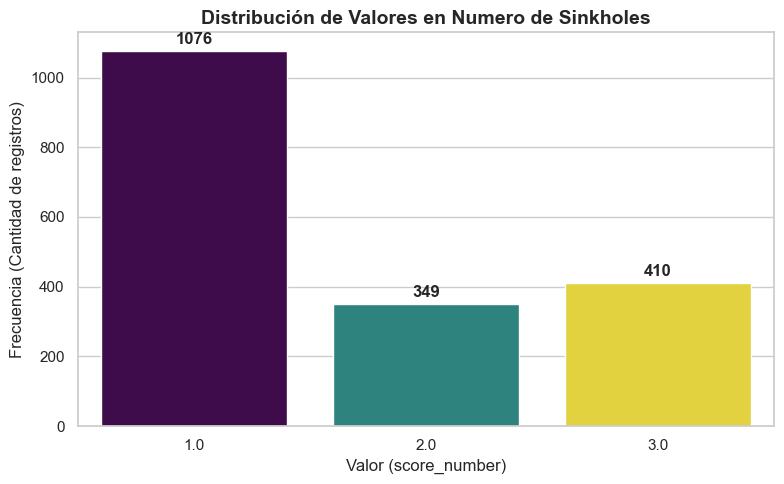

Desglose de valores en 'score_number':
score_number
1.0    1076
2.0     349
3.0     410
Name: count, dtype: int64


In [139]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calculamos las frecuencias de cada valor y las ordenamos por el índice (1, 2, 3)
frecuencias_score = df_mag['score_number'].value_counts().sort_index()

# 2. Configuración y visualización
plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Creamos el gráfico de barras
ax = sns.barplot(
    x=frecuencias_score.index, 
    y=frecuencias_score.values, 
    hue=frecuencias_score.index, 
    palette='viridis', # Puedes cambiar la paleta de colores si lo deseas
    legend=False
)

# 3. Etiquetas y título
plt.title('Distribución de Valores en Numero de Sinkholes', fontsize=14, fontweight='bold')
plt.xlabel('Valor (score_number)', fontsize=12)
plt.ylabel('Frecuencia (Cantidad de registros)', fontsize=12)

# 4. Añadimos el número exacto sobre cada barra para mayor claridad
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

# Opcional: imprimir los valores exactos en consola
print("Desglose de valores en 'score_number':")
print(frecuencias_score)

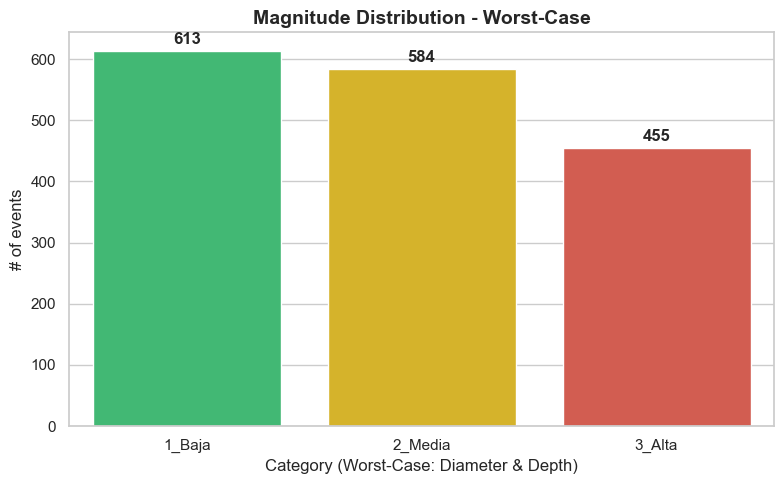

Total registros históricos: 1868
Registros útiles (con al menos 1 parámetro medido): 1652


In [140]:
# 5. Auditoría y Visualización
df_model_mag = df_mag.dropna(subset=['Magnitud_Real']).copy()

frecuencias = df_model_mag['Magnitud_Real'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")
ax = sns.barplot(
    x=frecuencias.index, 
    y=frecuencias.values, 
    hue=frecuencias.index, 
    palette=['#2ecc71', '#f1c40f', '#e74c3c'], 
    legend=False
)

plt.title('Magnitude Distribution - Worst-Case', fontsize=14, fontweight='bold')
plt.xlabel('Category (Worst-Case: Diameter & Depth)', fontsize=12)
plt.ylabel('# of events', fontsize=12)

for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Total registros históricos: {len(df_mag)}")
print(f"Registros útiles (con al menos 1 parámetro medido): {len(df_model_mag)}")

## SELECCION DE VARIABLES PREDICTORAS

### 1. EDA de la variable objetivo

In [141]:
# Como la variable objetivo es una variable ORDINAL, definimos su orden
# 1. Creo un DF para definir la variable ordinal
df_mag_ordinal = df_mag.copy()

target_col = "Magnitud_Real"

magnitude_order = ["1_Baja", "2_Media", "3_Alta"]
df_mag_ordinal[target_col] = pd.Categorical(df_mag_ordinal[target_col], categories=magnitude_order, ordered=True)

print(df_mag_ordinal[target_col].dtype)
print(df_mag_ordinal[target_col].unique())
print(df_mag_ordinal[target_col].value_counts(dropna=False))
print(df_mag_ordinal[target_col].value_counts(normalize=True, dropna=False) * 100)

category
['1_Baja', '3_Alta', '2_Media', NaN]
Categories (3, object): ['1_Baja' < '2_Media' < '3_Alta']
Magnitud_Real
1_Baja     613
2_Media    584
3_Alta     455
NaN        216
Name: count, dtype: int64
Magnitud_Real
1_Baja     32.815846
2_Media    31.263383
3_Alta     24.357602
NaN        11.563169
Name: proportion, dtype: float64


In [142]:
# 2. Verifico frecuencias totales con respecto a todo el DATASET
abs_counts = df_mag_ordinal[target_col].value_counts(dropna=False).reindex(magnitude_order)
rel_counts = df_mag_ordinal[target_col].value_counts(normalize=True, dropna=False).reindex(magnitude_order) * 100

print("Frecuencias absolutas:")
print(abs_counts)

print("\nFrecuencias relativas (%):")
print(rel_counts.round(2))

Frecuencias absolutas:
Magnitud_Real
1_Baja     613
2_Media    584
3_Alta     455
Name: count, dtype: int64

Frecuencias relativas (%):
Magnitud_Real
1_Baja     32.82
2_Media    31.26
3_Alta     24.36
Name: proportion, dtype: float64


In [143]:
# 3. Revisamos las frecuencias SIN NaN
counts_valid = df_mag_ordinal[target_col].value_counts(dropna=True).reindex(magnitude_order)
props_valid = df_mag_ordinal[target_col].value_counts(dropna=True, normalize=True).reindex(magnitude_order) * 100

print("Frecuencias absolutas sin NaN:")
print(counts_valid)

print("\nFrecuencias relativas sin NaN (%):")
print(props_valid.round(2))

Frecuencias absolutas sin NaN:
Magnitud_Real
1_Baja     613
2_Media    584
3_Alta     455
Name: count, dtype: int64

Frecuencias relativas sin NaN (%):
Magnitud_Real
1_Baja     37.11
2_Media    35.35
3_Alta     27.54
Name: proportion, dtype: float64


In [144]:
# 4. Resumen general de la variable objetivo
n_total = len(df_mag_ordinal)
n_valid = df_mag_ordinal[target_col].notna().sum()
n_missing = df_mag_ordinal[target_col].isna().sum()

print(f"Total registros: {n_total}")
print(f"Target observado: {n_valid} ({n_valid/n_total*100:.2f}%)")
print(f"Target faltante: {n_missing} ({n_missing/n_total*100:.2f}%)")

Total registros: 1868
Target observado: 1652 (88.44%)
Target faltante: 216 (11.56%)


Con esto, el EDA del target queda suficientemente cerrado para avanzar. Más adelante convendrá revisar si esos NaN del target están asociados a país, municipio o alguna variable de mina

# 2. EDA univariado de variables predictoras

In [145]:
# 1. Creo el DATASET de las variables que considero pueden servir como predictoras
cols = ["id_bd_sinkhole",
        "dip_of_the_exploited_layer_degree", # Pendiente EDA - numerica
        "type_of_mining_work_shaft_cavity-drift", # Pendiente EDA - categorica nominal 
        "origin_of_collapse", # Pendiente EDA - categorica nominal
        "working_thickness_numeric", # EDA realizado 
        "depth_drift_clean", # EDA realizado
        "overburden_resistance_numeric" # EDA realizado
        ]

#Creamos un df nuevo
df_mag_predictoras = df_risk_completo[cols].copy()

In [146]:
# Añadir Variable Objetivo
df_mag_predictoras = df_risk_completo.merge(
    df_mag[['id_bd_sinkhole', 'Magnitud_Real']], 
    on='id_bd_sinkhole', 
    how='left')

### 2.1. EDA de dip of layer

In [147]:
df_mag_predictoras["dip_of_the_exploited_layer_degree"].unique()

array([nan, 0, '10-25', '0-20', 10, 'so', '15-20', '24-65', '10-30',
       '<10', '10 -35', '30-45', '30-60', '0 to >60', '1 to >60',
       '2 to >60', '3 to >60', '3 à 5', '3-5', '0 à 55', 20, '0 to 40',
       '50-60', '10 to 25', '5 to 8', '<25', '0 to 30', '25 to 85', 30,
       45, 15, 60, 'unknown', '~ 60°', 9, 8, 5, 7, 6, 12, 3, 4, 2, 13, 11,
       16], dtype=object)

In [148]:
# 1. Realizamos una limpieza de las observaciones del dip of the layer

import pandas as pd
import numpy as np
import re

def estandarizar_buzamiento(valor):
    # Si ya es un valor nulo, lo dejamos pasar
    if pd.isna(valor):
        return np.nan
    
    # Convertimos a texto, pasamos a minúsculas y quitamos espacios en los extremos
    s = str(valor).lower().strip()
    
    # 1. Casos de texto sin información
    if s in ['so', 'unknown']:
        return np.nan
        
    # 2. Limpiamos símbolos (grados, aproximados, mayores que)
    s = s.replace('°', '').replace('~', '').replace('>', '').replace('<', '').strip()
    
    # 3. Manejo de desigualdades "menor que" (ej. '<10' -> 5)
    #if '<' in s:
     #   nums = re.findall(r'\d+', s)
      #  if nums:
       #     return float(nums[0]) / 1.5
            
    # 4. Manejo de rangos (busca guiones, 'to', 'à')
    if '-' in s or 'to' in s or 'à' in s:
        nums = re.findall(r'\d+', s) # Extrae todos los números
        if len(nums) >= 2:
            # Retorna el promedio de los dos primeros números encontrados
            return (float(nums[0]) + float(nums[1])) / 2.0
            
    # 5. Captura de números únicos (si no cayó en ninguna de las condiciones anteriores)
    nums = re.findall(r'\d+\.?\d*', s)
    if nums:
        return float(nums[0])
        
    # Si por alguna razón algo sobrevive, devolver NaN
    return np.nan

# --- APLICACIÓN ---

# Creamos la nueva columna 'dip_clean'
df_mag_predictoras['dip_clean'] = df_mag_predictoras['dip_of_the_exploited_layer_degree'].apply(estandarizar_buzamiento)

In [149]:
# 2. Datos estadisticos de la variable
col = "dip_clean"

print(df_mag_predictoras[col].dtype)
print("Total registros:", len(df_mag_predictoras))
print("Valores faltantes:", df_mag_predictoras[col].isna().sum())
print("Porcentaje faltantes:", round(df_mag_predictoras[col].isna().mean() * 100, 2))

print("\nResumen descriptivo:")
print(df_mag_predictoras[col].describe())

print("\nPercentiles adicionales:")
print(df_mag_predictoras[col].quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

float64
Total registros: 1868
Valores faltantes: 601
Porcentaje faltantes: 32.17

Resumen descriptivo:
count    1267.000000
mean       10.719811
std         8.717505
min         0.000000
25%         6.000000
50%         9.000000
75%         9.000000
max        60.000000
Name: dip_clean, dtype: float64

Percentiles adicionales:
0.01     0.0
0.05     4.0
0.25     6.0
0.50     9.0
0.75     9.0
0.95    30.0
0.99    45.0
Name: dip_clean, dtype: float64


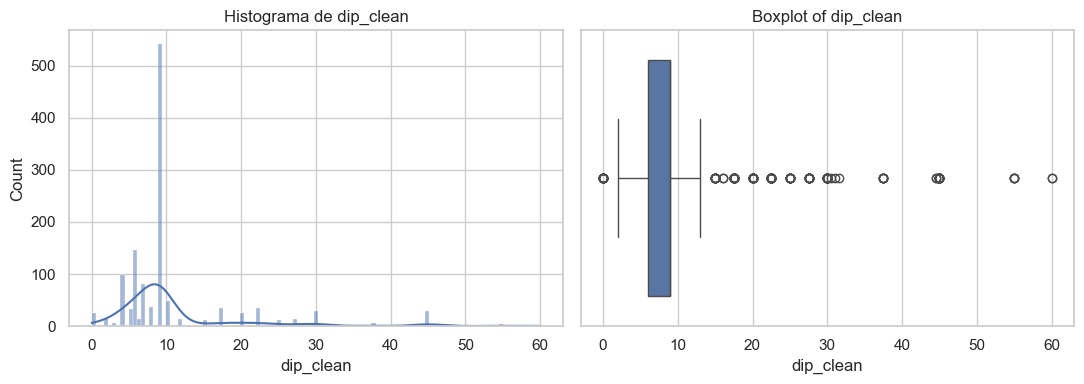

Asimetría: 2.685356230219593
Curtosis: 8.05315384284199


In [150]:
#3. Estadistica descriptiva
import matplotlib.pyplot as plt
import seaborn as sns

col = "dip_clean"

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df_mag_predictoras[col].dropna(), kde=True, ax=axes[0])
axes[0].set_title(f"Histograma de {col}")

sns.boxplot(x=df_mag_predictoras[col], ax=axes[1])
axes[1].set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()
print("Asimetría:", df_mag_predictoras[col].skew())
print("Curtosis:", df_mag_predictoras[col].kurt())

### 2.2. EDA de Tipo de mina

In [151]:
df_mag_predictoras['type_of_mining_work_shaft_cavity-drift'].unique()

array(['cavity-drift', 'shaft', nan, 'shaft and drift',
       'drift and later shaft', 'unknown', 'probably a ventilation shaft',
       'Cavity-drift', 'Shaft', 'Lack of exploitation', 'Carst', 'Shaft ',
       'Unknow', 'Collapse', 'Suffosion'], dtype=object)

In [152]:
# Despues de revisar la base de datos, solo tiene sentido agrupar esta variable por dos tipos de categorias (Shaft / Drift)

# 1. Ponemos todo en minusculas
df_mag_predictoras['type_mining_clean'] = df_mag_predictoras['type_of_mining_work_shaft_cavity-drift'].astype(str).str.lower().str.strip()

# 2. Creamos las categorias 1_Shaft y 2_Drift
df_mag_predictoras['type_mining_clean'] = np.where(df_mag_predictoras['type_mining_clean'].str.contains('shaft'), 'Shaft',
                                 np.where(df_mag_predictoras['type_mining_clean'].str.contains('drift'), 'Drift', None))

In [153]:
freq_abs = df_mag_predictoras["type_mining_clean"].value_counts(dropna=False)
freq_rel = df_mag_predictoras["type_mining_clean"].value_counts(dropna=False, normalize=True) * 100

freq_table = pd.DataFrame({
    "count": freq_abs,
    "percentage": freq_rel.round(2)
})

print(freq_table)

                   count  percentage
type_mining_clean                   
Drift               1290       69.06
None                 435       23.29
Shaft                143        7.66


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\3446169273.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


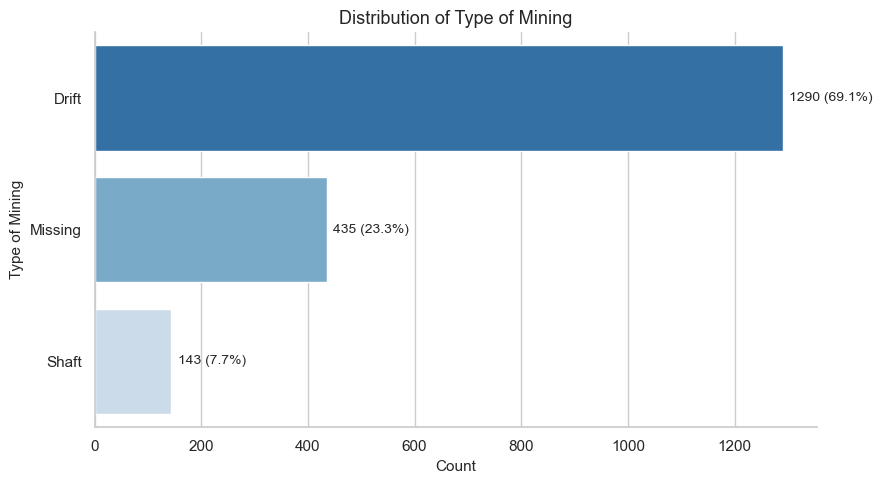

In [154]:
import matplotlib.pyplot as plt
import seaborn as sns

plot_data = (
    df_mag_predictoras["type_mining_clean"]
    .value_counts(dropna=False)
    .rename_axis("type_mining_clean")
    .reset_index(name="count")
)

# Reemplazar missing por una etiqueta legible
plot_data["type_mining_clean"] = plot_data["type_mining_clean"].fillna("Missing")

# Porcentaje para anotaciones
plot_data["percentage"] = (plot_data["count"] / plot_data["count"].sum() * 100).round(1)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=plot_data,
    y="type_mining_clean",
    x="count",
    palette="Blues_r"
)

plt.title("Distribution of Type of Mining", fontsize=13)
plt.xlabel("Count", fontsize=11)
plt.ylabel("Type of Mining", fontsize=11)

for i, row in plot_data.iterrows():
    ax.text(
        row["count"] + max(plot_data["count"]) * 0.01,
        i,
        f'{row["count"]} ({row["percentage"]}%)',
        va="center",
        fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.show()

### 2.3. EDA de Origen de Colapso

In [155]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- EDA: ORIGIN OF COLLAPSE ---")

# 1. Frecuencias y Completitud
total_origin = len(df_mag)
nulos_origin = df_mag['origin_collapse_clean'].isna().sum()
validos_origin = total_origin - nulos_origin
porcentaje_util_origin = (validos_origin / total_origin) * 100

print(f"Total de registros en BD: {total_origin}")
print(f"Datos válidos: {validos_origin} ({porcentaje_util_origin:.1f}%)")
print(f"Datos nulos: {nulos_origin}\n")

# 2. Tabla de Frecuencias Absolutas y Relativas
frecuencias = df_mag['origin_collapse_clean'].value_counts()
porcentajes = df_mag['origin_collapse_clean'].value_counts(normalize=True) * 100

df_frecuencias = pd.DataFrame({
    'Cantidad': frecuencias,
    'Porcentaje (%)': porcentajes.round(1)
})

print("--- Distribución de los Tipos de Origen ---")
print(df_frecuencias.head(10)) # Mostramos los 10 más comunes

--- EDA: ORIGIN OF COLLAPSE ---
Total de registros en BD: 1868
Datos válidos: 1353 (72.4%)
Datos nulos: 515

--- Distribución de los Tipos de Origen ---
                                           Cantidad  Porcentaje (%)
origin_collapse_clean                                              
faillure of the roof room or roof gallery       875            64.7
faillure of the roof gallery                    292            21.6
collapse of the shaft filling material          117             8.6
faillure of the roof room                        43             3.2
failure of the shaft head                        15             1.1
pillar failure                                    6             0.4
karst                                             3             0.2
collapse of the surface                           1             0.1
suffosion                                         1             0.1


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\3744991644.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


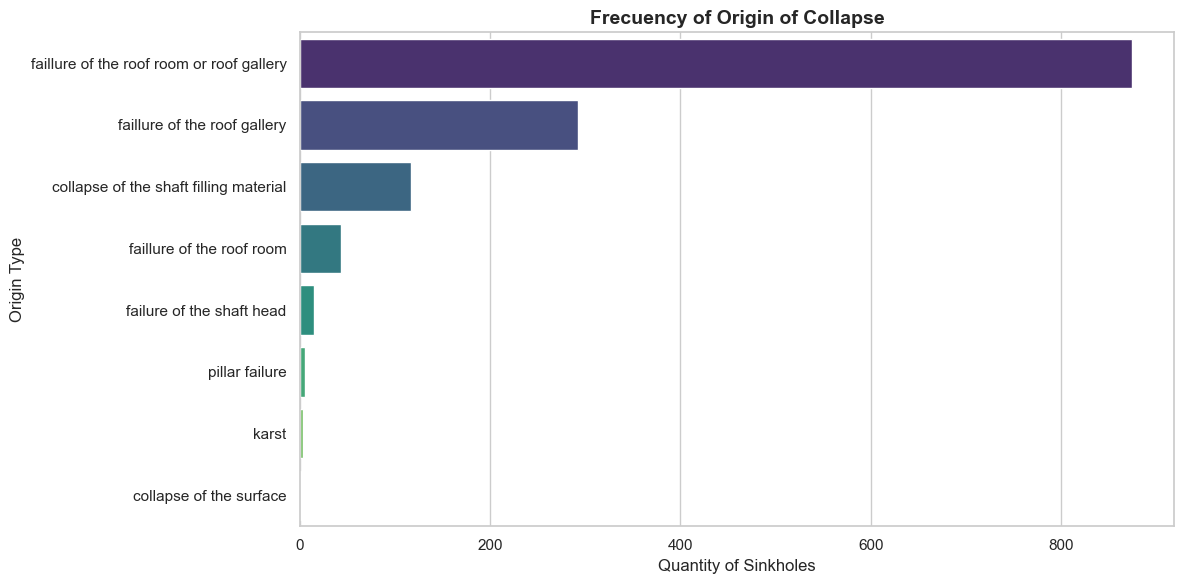

In [156]:
# 3. Visualización (Gráfico de Barras Horizontal)
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Filtramos los top 8 orígenes para que el gráfico no se sature de categorías raras
top_n = frecuencias.head(8).index
df_plot_origin = df_mag[df_mag['origin_collapse_clean'].isin(top_n)]

sns.countplot(
    data=df_plot_origin,
    y='origin_collapse_clean',
    order=top_n,
    palette='viridis'
)
plt.title('Frecuency of Origin of Collapse', fontsize=14, fontweight='bold')
plt.xlabel('Quantity of Sinkholes', fontsize=12)
plt.ylabel('Origin Type', fontsize=12)
plt.tight_layout()
plt.show()

In [157]:
# 4. Cruce de Variables: Origen vs. Magnitud Física
print("\n--- Impacto del Origen en la Magnitud FÍSICA (Medianas) ---")
# Calculamos la mediana del diámetro y profundidad para cada tipo de origen
impacto_origen = df_mag.groupby('origin_collapse_clean')[['diameter_sinkhole_clean', 'depth_sinkhole_clean']].median()

# Añadimos el conteo para dar contexto (no es lo mismo una mediana de 1 dato que de 100)
impacto_origen['Conteo'] = df_mag.groupby('origin_collapse_clean').size()

# Ordenamos por el diámetro de mayor a menor para ver cuáles son los más destructivos
impacto_origen = impacto_origen.sort_values(by='diameter_sinkhole_clean', ascending=False)
impacto_origen[impacto_origen['Conteo'] >= 5].head(10) # Filtramos los que tienen al menos 5 casos


--- Impacto del Origen en la Magnitud FÍSICA (Medianas) ---


,diameter_sinkhole_clean,depth_sinkhole_clean,Conteo
origin_collapse_clean,,,
faillure of the roof room or roof gallery,5.00,2.0,875
failure of the shaft head,4.50,3.0,15
faillure of the roof room,3.00,2.0,43
faillure of the roof gallery,3.00,1.5,292
collapse of the shaft filling material,3.00,1.5,117
pillar failure,1.75,2.0,6


In [158]:
df_mag["origin_collapse_clean"].unique()

array([nan, 'collapse of the shaft filling material',
       'faillure of the roof gallery', 'faillure of the roof room',
       'failure of the shaft head',
       'faillure of the roof room or roof gallery', 'karst',
       'collapse of the surface', 'pillar failure', 'suffosion'],
      dtype=object)

Como resultado, se decide agrupar ciertas clases de la variable debido a que el resto no representa una explicacion fiable del comportamiento de la magnitud
Para esto se crea una nueva variable "origin_collapse_grouped"

In [159]:
# 5. Creacion de variable origin_collapse_grouped

col = "origin_collapse_clean"

# Normalizar texto antes de agrupar
df_mag[col] = (
    df_mag[col]
    .astype("string")
    .str.strip()
    .str.lower()
)

group_map_current = {
    "faillure of the roof room or roof gallery": "Roof-related failure",
    "faillure of the roof gallery": "Roof-related failure",
    "faillure of the roof room": "Roof-related failure",
    "collapse of the shaft filling material": "Shaft-related failure",
    "failure of the shaft head": "Shaft-related failure",
    "pillar failure": "Other",
    "karst": "Other",
    "collapse of the surface": "Other",
    "suffosion": "Other"
}

df_mag_predictoras["origin_collapse_grouped"] = (
    df_mag[col]
    .map(group_map_current)
)

In [160]:
df_mag_predictoras["origin_collapse_grouped"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 1868 entries, 0 to 1867
Series name: origin_collapse_grouped
Non-Null Count  Dtype 
--------------  ----- 
1353 non-null   object
dtypes: object(1)
memory usage: 14.7+ KB


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\2605271500.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\2605271500.py:24: UserWarning: The palette list has more values (4) than needed (3), which may not be intended.
  ax = sns.barplot(


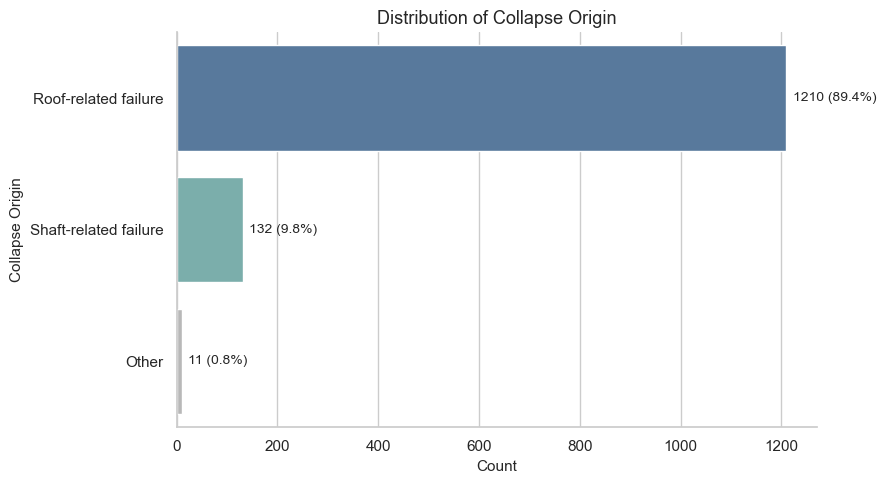

In [161]:
# 6. Visualizacion de variable agrupada

import matplotlib.pyplot as plt
import seaborn as sns

plot_col = "origin_collapse_grouped"
order = [
    "Roof-related failure",
    "Shaft-related failure",
    "Other"
]

plot_data = (
    df_mag_predictoras[plot_col]
    .value_counts(dropna=False)
    .reindex(order)
    .reset_index()
)

plot_data.columns = ["Collapse origin", "Count"]
plot_data["Percentage"] = (plot_data["Count"] / plot_data["Count"].sum() * 100).round(1)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    data=plot_data,
    y="Collapse origin",
    x="Count",
    palette=["#4C78A8", "#72B7B2", "#B8B8B8", "#D9D9D9"]
)

plt.title("Distribution of Collapse Origin", fontsize=13)
plt.xlabel("Count", fontsize=11)
plt.ylabel("Collapse Origin", fontsize=11)

for i, row in plot_data.iterrows():
    ax.text(
        row["Count"] + plot_data["Count"].max() * 0.01,
        i,
        f'{row["Count"]} ({row["Percentage"]}%)',
        va="center",
        fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.show()

## 3. Analisis bivariado con variables continuas

In [162]:
# 1 Hacemos la variable categorica
target_col = "Magnitud_Real"

magnitude_order = ["1_Baja", "2_Media", "3_Alta"]
df_mag_predictoras[target_col] = pd.Categorical(df_mag_predictoras[target_col], categories=magnitude_order, ordered=True)


## 3.1. Working Thickness vs Magniude variable

C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\1025324904.py:15: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  plot_df[target] = plot_df[target].replace(reemplazo_etiquetas)
C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\1025324904.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(


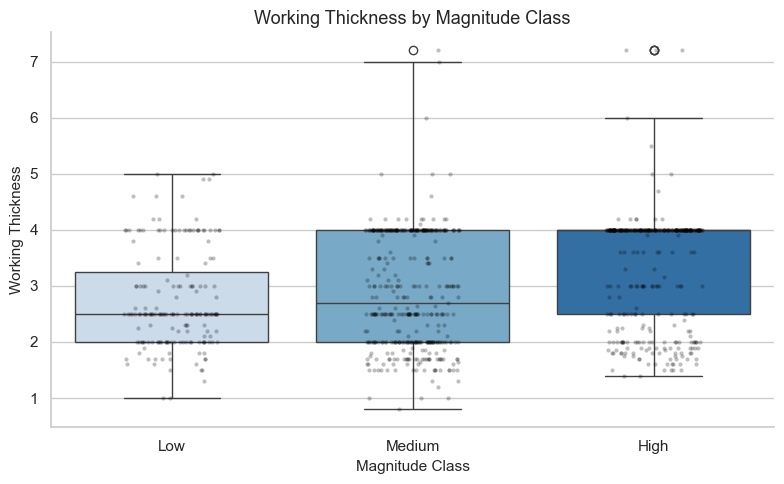

In [163]:
import matplotlib.pyplot as plt
import seaborn as sns

target = "Magnitud_Real"
cont_var = "working_thickness_numeric"

plot_df = df_mag_predictoras[[target, cont_var]].dropna().copy()

# 1. Mapear los valores actuales al inglés
reemplazo_etiquetas = {
    "1_Baja": "Low", 
    "2_Media": "Medium", 
    "3_Alta": "High"
}
plot_df[target] = plot_df[target].replace(reemplazo_etiquetas)

# 2. Definir el orden lógico para el eje X
orden_magnitud = ["Low", "Medium", "High"]

plt.figure(figsize=(8, 5))
ax = sns.boxplot(
    data=plot_df,
    x=target,
    y=cont_var,
    order=orden_magnitud,  # Fuerza el orden visual en el gráfico
    palette="Blues"
)

sns.stripplot(
    data=plot_df,
    x=target,
    y=cont_var,
    order=orden_magnitud,  # Mantiene la coherencia con el boxplot
    color="black",
    alpha=0.25,
    size=3,
    jitter=0.2
)

plt.title("Working Thickness by Magnitude Class", fontsize=13)
plt.xlabel("Magnitude Class", fontsize=11)
plt.ylabel("Working Thickness", fontsize=11)

sns.despine()
plt.tight_layout()
plt.show()

In [164]:
summary_table = (
    df_mag_predictoras
    .groupby(target)[cont_var]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        max="max"
    )
    .round(2)
)

print(summary_table)

               count  mean  median   std  min   q1    q3  max
Magnitud_Real                                                
1_Baja           176  2.74     2.5  0.88  1.0  2.0  3.25  5.0
2_Media          401  2.91     2.7  1.03  0.8  2.0  4.00  7.2
3_Alta           358  3.37     4.0  1.01  1.4  2.5  4.00  7.2


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\2534199115.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(target)[cont_var]


In [165]:
from scipy.stats import kruskal

groups = [
    group[cont_var].dropna().values
    for _, group in df_mag_predictoras[[target, cont_var]].dropna().groupby(target)
]

stat, p_value = kruskal(*groups)

print(f"Kruskal-Wallis statistic: {stat:.3f}")
print(f"p-value: {p_value:.5f}")

Kruskal-Wallis statistic: 52.031
p-value: 0.00000


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\3982851771.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, group in df_mag_predictoras[[target, cont_var]].dropna().groupby(target)


In [166]:
import pandas as pd

target = "Magnitud_Real"
cont_var = "working_thickness_numeric"

order_map = {
    "1_Baja": 1,
    "2_Media": 2,
    "3_Alta": 3
}

df_mag_predictoras["Magnitud_Real_ord"] = df_mag_predictoras[target].map(order_map)

# Verificación rápida
print(df_mag_predictoras[[target, "Magnitud_Real_ord"]].drop_duplicates().sort_values("Magnitud_Real_ord"))
print(df_mag_predictoras["Magnitud_Real_ord"].isna().sum())

  Magnitud_Real Magnitud_Real_ord
0        1_Baja                 1
3       2_Media                 2
2        3_Alta                 3
8           NaN               NaN
216


In [167]:
from scipy.stats import spearmanr

corr_df = df_mag_predictoras[[cont_var, "Magnitud_Real_ord"]].dropna().copy()

rho, pval_rho = spearmanr(corr_df[cont_var], corr_df["Magnitud_Real_ord"])

print(f"Spearman rho: {rho:.4f}")
print(f"p-value: {pval_rho:.6f}")

Spearman rho: 0.2296
p-value: 0.000000


In [168]:
from scipy.stats import kendalltau

tau, pval_tau = kendalltau(corr_df[cont_var], corr_df["Magnitud_Real_ord"])

print(f"Kendall tau-b: {tau:.4f}")
print(f"p-value: {pval_tau:.6f}")

Kendall tau-b: 0.1896
p-value: 0.000000


In [169]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr, kendalltau
import scikit_posthocs as sp

target = "Magnitud_Real"
cont_var = "working_thickness_numeric"

# Codificación ordinal
order_map = {
    "1_Baja": 1,
    "2_Media": 2,
    "3_Alta": 3
}

df_mag_predictoras["Magnitud_Real_ord"] = df_mag_predictoras[target].map(order_map)

# Dataframe limpio
analysis_df = df_mag_predictoras[[target, "Magnitud_Real_ord", cont_var]].dropna().copy()

# Spearman
rho, pval_rho = spearmanr(analysis_df[cont_var], analysis_df["Magnitud_Real_ord"])

# Kendall tau-b
tau, pval_tau = kendalltau(analysis_df[cont_var], analysis_df["Magnitud_Real_ord"])

print("Ordinal association")
print(f"Spearman rho: {rho:.4f} | p-value: {pval_rho:.6f}")
print(f"Kendall tau-b: {tau:.4f} | p-value: {pval_tau:.6f}")

# Dunn post hoc
dunn_results = sp.posthoc_dunn(
    analysis_df,
    val_col=cont_var,
    group_col=target,
    p_adjust="holm"
)

print("\nDunn post hoc matrix (Holm-adjusted p-values):")
print(dunn_results)

# Formato largo
dunn_long = (
    dunn_results.where(~np.tril(np.ones(dunn_results.shape)).astype(bool))
    .stack()
    .reset_index()
)

dunn_long.columns = ["Group_1", "Group_2", "p_value_holm"]
dunn_long["significant_0.05"] = dunn_long["p_value_holm"] < 0.05

print("\nPairwise comparisons:")
print(dunn_long.sort_values("p_value_holm"))

Ordinal association
Spearman rho: 0.2296 | p-value: 0.000000
Kendall tau-b: 0.1896 | p-value: 0.000000



Dunn post hoc matrix (Holm-adjusted p-values):
               1_Baja       2_Media        3_Alta
1_Baja   1.000000e+00  1.569227e-01  2.551896e-09
2_Media  1.569227e-01  1.000000e+00  3.767876e-09
3_Alta   2.551896e-09  3.767876e-09  1.000000e+00

Pairwise comparisons:
   Group_1  Group_2  p_value_holm  significant_0.05
1   1_Baja   3_Alta  2.551896e-09              True
2  2_Media   3_Alta  3.767876e-09              True
0   1_Baja  2_Media  1.569227e-01             False


## 3.2. Dip of the layer vs magnitude

Valid observations: 1064

Overall summary:
count    1064.00
mean       10.47
std         8.06
min         0.00
25%         6.00
50%         9.00
75%         9.00
max        60.00
Name: dip_clean, dtype: float64

Summary by Magnitude Class:
               count   mean  median    std  min   q1    q3   max
Magnitud_Real                                                   
1_Baja           216  12.22     9.0  11.17  0.0  6.0  15.0  60.0
2_Media          446  10.09     9.0   7.10  0.0  6.0   9.0  55.0
3_Alta           402   9.95     9.0   6.86  0.0  8.0   9.0  60.0


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\4035967320.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(target)[cont_var]
C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\4035967320.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


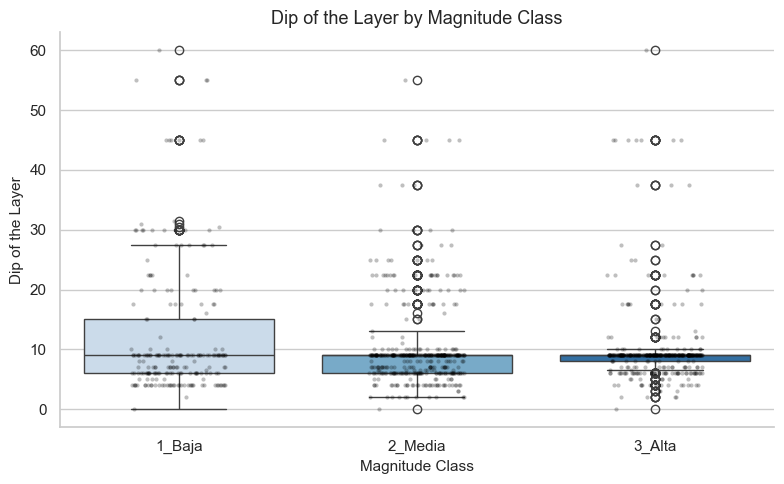


Kruskal-Wallis result:
Statistic: 4.946
p-value: 0.084313

Ordinal association:
Spearman rho: 0.0658 | p-value: 0.031917
Kendall tau-b: 0.0562 | p-value: 0.029401


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\4035967320.py:78: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for _, group in analysis_df.groupby(target)


In [170]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kruskal, spearmanr, kendalltau
import scikit_posthocs as sp

target = "Magnitud_Real"
cont_var = "dip_clean"

# Si no existe ya, crear codificación ordinal
order_map = {
    "1_Baja": 1,
    "2_Media": 2,
    "3_Alta": 3
}

df_mag_predictoras["Magnitud_Real_ord"] = df_mag_predictoras[target].map(order_map)

# DataFrame de análisis
analysis_df = df_mag_predictoras[[target, "Magnitud_Real_ord", cont_var]].dropna().copy()

print("Valid observations:", len(analysis_df))
print("\nOverall summary:")
print(analysis_df[cont_var].describe().round(2))

# Tabla resumen por clase
summary_table = (
    analysis_df
    .groupby(target)[cont_var]
    .agg(
        count="count",
        mean="mean",
        median="median",
        std="std",
        min="min",
        q1=lambda x: x.quantile(0.25),
        q3=lambda x: x.quantile(0.75),
        max="max"
    )
    .round(2)
)

print("\nSummary by Magnitude Class:")
print(summary_table)

# Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=analysis_df,
    x=target,
    y=cont_var,
    palette="Blues"
)

sns.stripplot(
    data=analysis_df,
    x=target,
    y=cont_var,
    color="black",
    alpha=0.25,
    size=3,
    jitter=0.2
)

plt.title("Dip of the Layer by Magnitude Class", fontsize=13)
plt.xlabel("Magnitude Class", fontsize=11)
plt.ylabel("Dip of the Layer", fontsize=11)

sns.despine()
plt.tight_layout()
plt.show()

# Kruskal-Wallis
groups = [
    group[cont_var].values
    for _, group in analysis_df.groupby(target)
]

stat, p_value = kruskal(*groups)

print("\nKruskal-Wallis result:")
print(f"Statistic: {stat:.3f}")
print(f"p-value: {p_value:.6f}")

# Asociación ordinal
rho, pval_rho = spearmanr(analysis_df[cont_var], analysis_df["Magnitud_Real_ord"])
tau, pval_tau = kendalltau(analysis_df[cont_var], analysis_df["Magnitud_Real_ord"])

print("\nOrdinal association:")
print(f"Spearman rho: {rho:.4f} | p-value: {pval_rho:.6f}")
print(f"Kendall tau-b: {tau:.4f} | p-value: {pval_tau:.6f}")

# Dunn post hoc solo si Kruskal-Wallis es significativo
if p_value < 0.05:
    dunn_results = sp.posthoc_dunn(
        analysis_df,
        val_col=cont_var,
        group_col=target,
        p_adjust="holm"
    )

    print("\nDunn post hoc matrix (Holm-adjusted p-values):")
    print(dunn_results)

    dunn_long = (
        dunn_results.where(~np.tril(np.ones(dunn_results.shape)).astype(bool))
        .stack()
        .reset_index()
    )

    dunn_long.columns = ["Group_1", "Group_2", "p_value_holm"]
    dunn_long["significant_0.05"] = dunn_long["p_value_holm"] < 0.05

    print("\nPairwise comparisons:")
    print(dunn_long.sort_values("p_value_holm"))

## 1. EDA de variables predictoras

El df_risk_completo contiene las variables limpias y analizadas en el modelo de Susceptibilidad. 

En este modelo vamos a usar tambien esas variable para detectar correlacion con la magnitud del sinkhole y vamos a agregar otras variables que pueden servir como predictoras

In [171]:
# DATASET PARA DIO Y TYPE OF MINING WORKING
cols = ["id_bd_sinkhole",
        "dip_of_the_exploited_layer_degree", # Pendiente EDA - numerica
        "type_of_mining_work_shaft_cavity-drift", # Pendiente EDA - categorica nominal 
        "origin_of_collapse", # Pendiente EDA - categorica nominal
        "working_thickness_numeric", # EDA realizado 
        "depth_drift_clean", # EDA realizado
        "overburden_resistance_numeric" # EDA realizado
        ]

#Creamos un df nuevo
df_pred_magnitud = df_risk_completo[cols].copy()

In [172]:
# Añadir Variable Objetivo
df_pred_magnitud = df_risk_completo.merge(
    df_mag[['id_bd_sinkhole', 'Magnitud_Real']], 
    on='id_bd_sinkhole', 
    how='left')

## 2. Limpieza de Dip of the explotated layer

In [173]:
df_pred_magnitud["dip_of_the_exploited_layer_degree"].unique()

array([nan, 0, '10-25', '0-20', 10, 'so', '15-20', '24-65', '10-30',
       '<10', '10 -35', '30-45', '30-60', '0 to >60', '1 to >60',
       '2 to >60', '3 to >60', '3 à 5', '3-5', '0 à 55', 20, '0 to 40',
       '50-60', '10 to 25', '5 to 8', '<25', '0 to 30', '25 to 85', 30,
       45, 15, 60, 'unknown', '~ 60°', 9, 8, 5, 7, 6, 12, 3, 4, 2, 13, 11,
       16], dtype=object)

In [174]:
import pandas as pd
import numpy as np
import re

def estandarizar_buzamiento(valor):
    # Si ya es un valor nulo, lo dejamos pasar
    if pd.isna(valor):
        return np.nan
    
    # Convertimos a texto, pasamos a minúsculas y quitamos espacios en los extremos
    s = str(valor).lower().strip()
    
    # 1. Casos de texto sin información
    if s in ['so', 'unknown']:
        return np.nan
        
    # 2. Limpiamos símbolos (grados, aproximados, mayores que)
    s = s.replace('°', '').replace('~', '').replace('>', '').replace('<', '').strip()
    
    # 3. Manejo de desigualdades "menor que" (ej. '<10' -> 5)
    #if '<' in s:
     #   nums = re.findall(r'\d+', s)
      #  if nums:
       #     return float(nums[0]) / 1.5
            
    # 4. Manejo de rangos (busca guiones, 'to', 'à')
    if '-' in s or 'to' in s or 'à' in s:
        nums = re.findall(r'\d+', s) # Extrae todos los números
        if len(nums) >= 2:
            # Retorna el promedio de los dos primeros números encontrados
            return (float(nums[0]) + float(nums[1])) / 2.0
            
    # 5. Captura de números únicos (si no cayó en ninguna de las condiciones anteriores)
    nums = re.findall(r'\d+\.?\d*', s)
    if nums:
        return float(nums[0])
        
    # Si por alguna razón algo sobrevive, devolver NaN
    return np.nan

# --- APLICACIÓN ---

# Creamos la nueva columna 'dip_clean' (que luego usas en tu discretización)
df_pred_magnitud['dip_clean'] = df_pred_magnitud['dip_of_the_exploited_layer_degree'].apply(estandarizar_buzamiento)

--- 1. ESTADÍSTICAS DESCRIPTIVAS ---
count    1267.000000
mean       10.719811
std         8.717505
min         0.000000
25%         6.000000
50%         9.000000
75%         9.000000
max        60.000000
Name: dip_clean, dtype: float64

Valores nulos (NaN): 601 de 1868 (32.2%)

--- 2. VISUALIZACIÓN DE LA DISTRIBUCIÓN ---


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\2121743584.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_pred_magnitud, x='Magnitud_Real', y='dip_clean', ax=axes[2], palette="Reds")


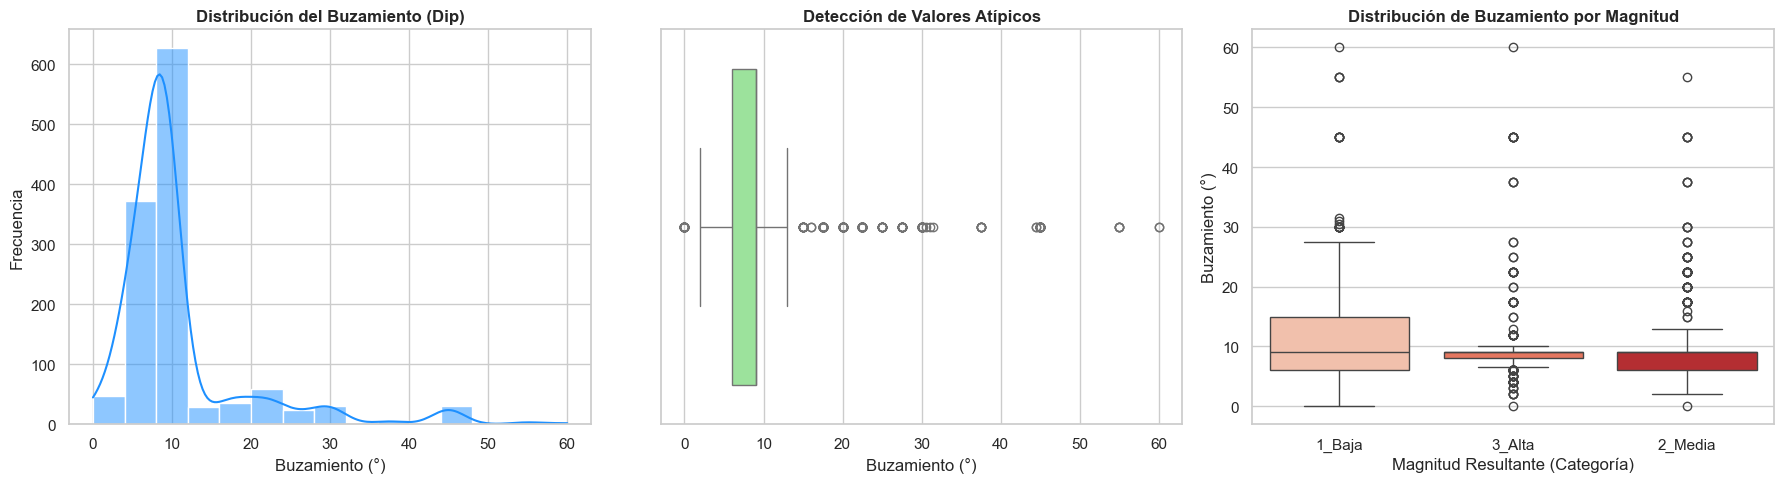

In [175]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- 1. ESTADÍSTICAS DESCRIPTIVAS ---")
# El método .describe() ignora automáticamente los NaN para los cálculos
resumen_stats = df_pred_magnitud['dip_clean'].describe()
print(resumen_stats)

# Es crucial saber cuántos datos perdimos o no se pudieron clasificar
nulos = df_pred_magnitud['dip_clean'].isna().sum()
total = len(df_pred_magnitud)
print(f"\nValores nulos (NaN): {nulos} de {total} ({(nulos/total)*100:.1f}%)")

print("\n--- 2. VISUALIZACIÓN DE LA DISTRIBUCIÓN ---")
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico A: Histograma con curva de densidad (KDE)
# Ideal para ver la concentración de los datos (ej. si la mayoría son < 30°)
sns.histplot(data=df_pred_magnitud, x='dip_clean', bins=15, kde=True, ax=axes[0], color='dodgerblue')
axes[0].set_title('Distribución del Buzamiento (Dip)', fontweight='bold')
axes[0].set_xlabel('Buzamiento (°)')
axes[0].set_ylabel('Frecuencia')

# Gráfico B: Boxplot
# Excelente para detectar valores atípicos (outliers) extremos
sns.boxplot(data=df_pred_magnitud, x='dip_clean', ax=axes[1], color='lightgreen')
axes[1].set_title('Detección de Valores Atípicos', fontweight='bold')
axes[1].set_xlabel('Buzamiento (°)')

# Gráfico C ALTERNATIVO: Si Magnitud es Categórica
if 'Magnitud_Real' in df_pred_magnitud.columns:
    # Un boxplot nos mostrará si las magnitudes más altas ocurren a mayores o menores ángulos
    sns.boxplot(data=df_pred_magnitud, x='Magnitud_Real', y='dip_clean', ax=axes[2], palette="Reds")
    axes[2].set_title('Distribución de Buzamiento por Magnitud', fontweight='bold')
    axes[2].set_xlabel('Magnitud Resultante (Categoría)')
    axes[2].set_ylabel('Buzamiento (°)')
else:
    axes[2].text(0.5, 0.5, 'Columna Magnitud_Real\nno encontrada', horizontalalignment='center', verticalalignment='center')
    axes[2].axis('off')

plt.tight_layout()
plt.show()

In [176]:
# B. Buzamiento (Dip)
# Discretizamos en 4 clases geomecánicas lógicas
bins_dip = [-1, 5, 10, 40, 90]
labels_dip = ['1_Plano (0-5°)', '2_Suave (5-10°)', '3_Inclinado (10-40°)', '4_Muy_Inclinado (>40°)']
df_pred_magnitud['Buzamiento_Predictor'] = pd.cut(df_pred_magnitud['dip_clean'], bins=bins_dip, labels=labels_dip)

--- DISTRIBUCIÓN DE CLASES DE BUZAMIENTO ---


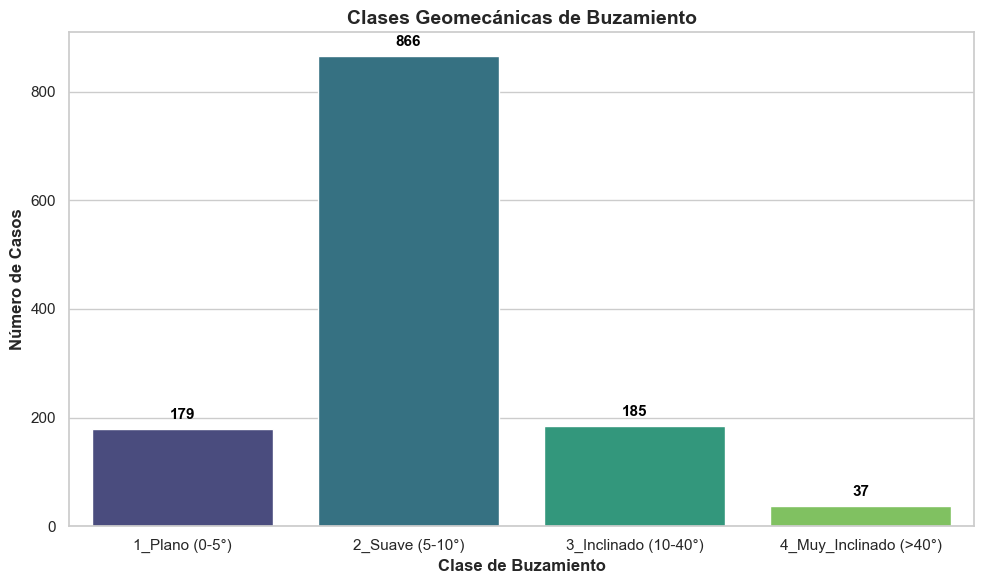

In [177]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- DISTRIBUCIÓN DE CLASES DE BUZAMIENTO ---")

# 1. Configuración del lienzo y estilo
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 2. Definimos el orden lógico de las categorías para que no se ordenen alfabéticamente
orden_categorias = ['1_Plano (0-5°)', '2_Suave (5-10°)', '3_Inclinado (10-40°)', '4_Muy_Inclinado (>40°)']

# 3. Creamos el gráfico de barras (Countplot cuenta automáticamente las filas por categoría)
# Nota: Usamos df_modelo que es donde filtraste los nulos en tu primer bloque de código
ax = sns.countplot(
    data=df_pred_magnitud, 
    x='Buzamiento_Predictor',
    order=orden_categorias,
    hue='Buzamiento_Predictor', # Asignamos color por categoría
    palette='viridis',          # Paleta de colores secuencial
    legend=False                # Ocultamos la leyenda porque el eje X ya lo explica
)

# 4. Títulos y etiquetas de los ejes
plt.title('Clases Geomecánicas de Buzamiento', fontweight='bold', fontsize=14)
plt.xlabel('Clase de Buzamiento', fontsize=12, fontweight='bold')
plt.ylabel('Número de Casos', fontsize=12, fontweight='bold')

# 5. Iteramos sobre las barras para poner el valor exacto encima de cada una
for p in ax.patches:
    altura = p.get_height()
    # Solo ponemos número si la barra tiene datos (> 0)
    if altura > 0:
        ax.annotate(f'{int(altura)}', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='bottom', 
                    fontsize=11, color='black', fontweight='bold',
                    xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## 3. Limpieza de Type of Mining Work

In [178]:
# Como queremos agrupar por dos tipos de categorias (Shaft / Drift)
# Limpiamos y agrupamos en dos categorías principales

# 1. Ponemos todo en minusculas
df_pred_magnitud['type_mining_clean'] = df_pred_magnitud['type_of_mining_work_shaft_cavity-drift'].astype(str).str.lower().str.strip()

# 2. Creamos las categorias 1_Shaft y 2_Drift
df_pred_magnitud['Tipo_Labor_Predictor'] = np.where(df_pred_magnitud['type_mining_clean'].str.contains('shaft'), '1_Shaft',
                                 np.where(df_pred_magnitud['type_mining_clean'].str.contains('drift'), '2_Drift', None))

--- DISTRIBUCIÓN DE CLASES DE BUZAMIENTO ---


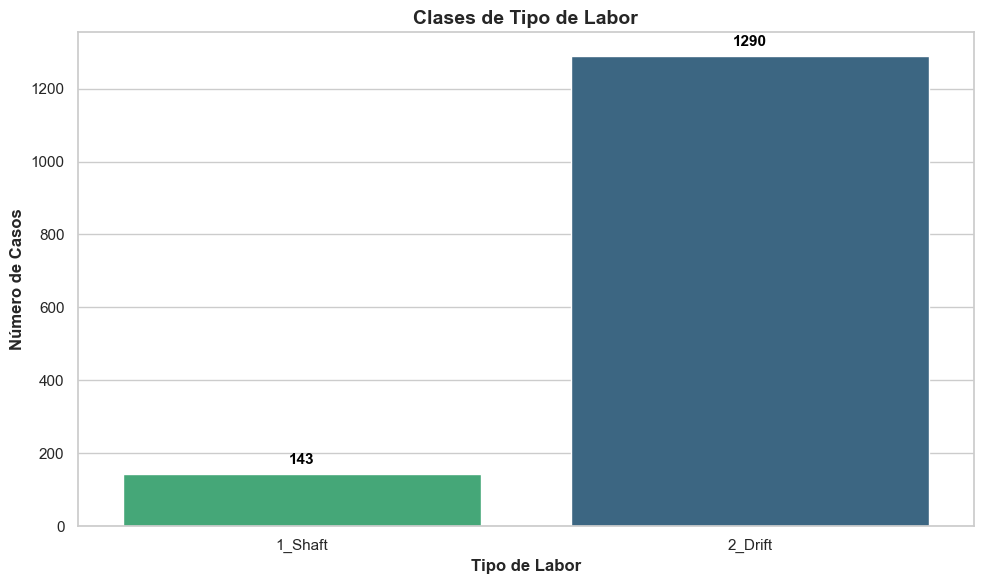

In [179]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- DISTRIBUCIÓN DE CLASES DE BUZAMIENTO ---")

# 1. Configuración del lienzo y estilo
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# 2. Definimos el orden lógico de las categorías para que no se ordenen alfabéticamente
orden_categorias = ['1_Shaft', '2_Drift']

# 3. Creamos el gráfico de barras (Countplot cuenta automáticamente las filas por categoría)
# Nota: Usamos df_modelo que es donde filtraste los nulos en tu primer bloque de código
ax = sns.countplot(
    data=df_pred_magnitud, 
    x='Tipo_Labor_Predictor',
    order=orden_categorias,
    hue='Tipo_Labor_Predictor', # Asignamos color por categoría
    palette='viridis',          # Paleta de colores secuencial
    legend=False                # Ocultamos la leyenda porque el eje X ya lo explica
)

# 4. Títulos y etiquetas de los ejes
plt.title('Clases de Tipo de Labor', fontweight='bold', fontsize=14)
plt.xlabel('Tipo de Labor', fontsize=12, fontweight='bold')
plt.ylabel('Número de Casos', fontsize=12, fontweight='bold')

# 5. Iteramos sobre las barras para poner el valor exacto encima de cada una
for p in ax.patches:
    altura = p.get_height()
    # Solo ponemos número si la barra tiene datos (> 0)
    if altura > 0:
        ax.annotate(f'{int(altura)}', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='bottom', 
                    fontsize=11, color='black', fontweight='bold',
                    xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## 4. Analisis Bivariado

In [180]:
# Variables limpias
variables_mag = [
    "id_bd_sinkhole",
    "dip_clean",
    "type_mining_clean",
    "working_thickness_numeric",  
    "depth_drift_clean", 
    "overburden_resistance_numeric",
    "Magnitud_Real"
]

In [181]:
df_pred_magnitud[variables_mag].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 7 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1868 non-null   object 
 1   dip_clean                      1267 non-null   float64
 2   type_mining_clean              1868 non-null   object 
 3   working_thickness_numeric      1102 non-null   float64
 4   depth_drift_clean              1339 non-null   float64
 5   overburden_resistance_numeric  1475 non-null   float64
 6   Magnitud_Real                  1652 non-null   object 
dtypes: float64(4), object(3)
memory usage: 102.3+ KB


En este caso se debe categorizar las variables predictoras para aplicar chi cuadrado

In [182]:
# Verificar completitud de las variables
df_pred_magnitud[["Tipo_Labor_Predictor", "Buzamiento_Predictor", "Magnitud_Real"]].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 3 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   Tipo_Labor_Predictor  1433 non-null   object  
 1   Buzamiento_Predictor  1267 non-null   category
 2   Magnitud_Real         1652 non-null   object  
dtypes: category(1), object(2)
memory usage: 31.3+ KB


In [183]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

print("--- PASO 2: ANÁLISIS BIVARIADO (PODER PREDICTIVO) ---")

# 0. Filtramos solo los datos que tienen nuestra variable objetivo lista
df_modelo = df_pred_magnitud.dropna(subset=['Magnitud_Real']).copy()


--- PASO 2: ANÁLISIS BIVARIADO (PODER PREDICTIVO) ---


In [184]:
# ---------------------------------------------------------
# 1. FUNCIÓN DE PRUEBAS ESTADÍSTICAS (Cramer's V)
# ---------------------------------------------------------
def calcular_cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    if min((kcorr-1), (rcorr-1)) == 0: return 0.0
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

def evaluar_predictor(df, col_predictor, col_objetivo):
    # Crear Tabla de Contingencia
    tabla_cont = pd.crosstab(df[col_predictor], df[col_objetivo])
    
    # Solo evaluar si hay datos suficientes
    if tabla_cont.empty or tabla_cont.sum().sum() < 10:
        return None, None, tabla_cont
        
    chi2, p, dof, expected = chi2_contingency(tabla_cont)
    v_cramer = calcular_cramers_v(tabla_cont)
    
    return p, v_cramer, tabla_cont

In [185]:
# ---------------------------------------------------------
# 2. EJECUCIÓN DEL ANÁLISIS
# ---------------------------------------------------------
p_labor, v_labor, tabla_labor = evaluar_predictor(df_modelo, 'Tipo_Labor_Predictor', 'Magnitud_Real')
p_dip, v_dip, tabla_dip = evaluar_predictor(df_modelo, 'Buzamiento_Predictor', 'Magnitud_Real')

print("\n--- RESULTADOS DE PODER PREDICTIVO ---")
print(f"1. TIPO DE LABOR MINERA:")
if p_labor is not None:
    print(f"   - p-value: {p_labor:.5f} ({'SIGNIFICATIVO' if p_labor < 0.05 else 'No significativo'})")
    print(f"   - Cramer's V (Fuerza): {v_labor:.3f}")
else: print("   - Sin datos suficientes.")

print(f"\n2. BUZAMIENTO DE LA CAPA:")
if p_dip is not None:
    print(f"   - p-value: {p_dip:.5f} ({'SIGNIFICATIVO' if p_dip < 0.05 else 'No significativo'})")
    print(f"   - Cramer's V (Fuerza): {v_dip:.3f}")
else: print("   - Sin datos suficientes.")


--- RESULTADOS DE PODER PREDICTIVO ---
1. TIPO DE LABOR MINERA:
   - p-value: 0.01153 (SIGNIFICATIVO)
   - Cramer's V (Fuerza): 0.075

2. BUZAMIENTO DE LA CAPA:
   - p-value: 0.00000 (SIGNIFICATIVO)
   - Cramer's V (Fuerza): 0.162


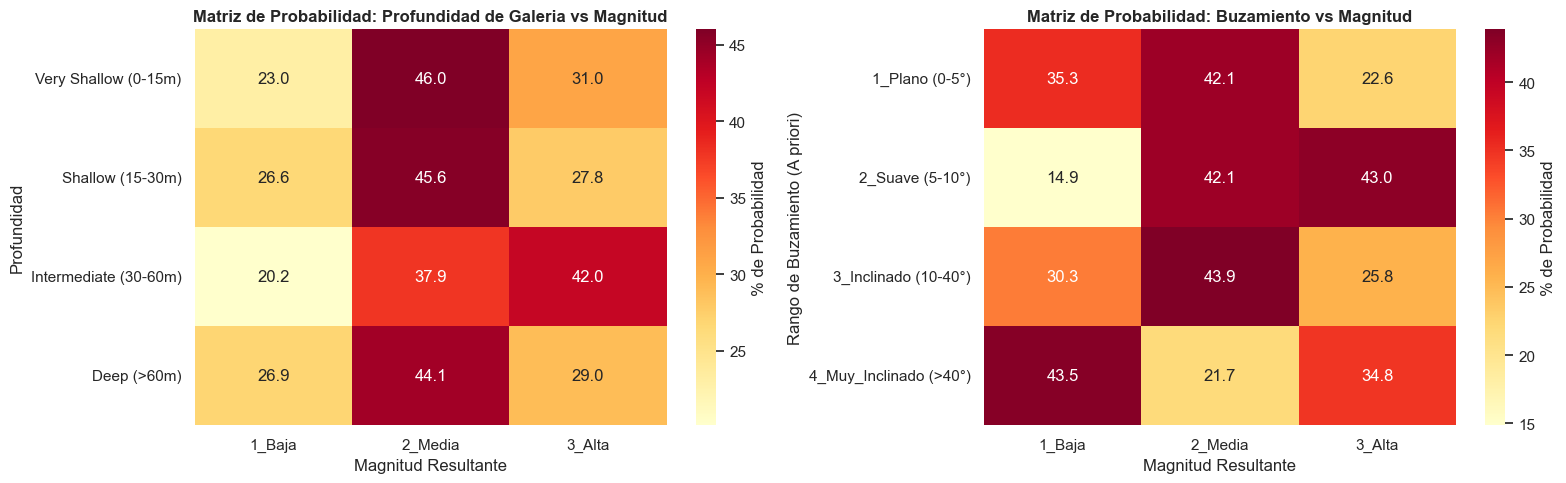

In [186]:
# ---------------------------------------------------------
# 3. VISUALIZACIÓN DE PROBABILIDADES (Mapas de Calor)
# ---------------------------------------------------------
# Convertimos las frecuencias a porcentajes por fila (Probabilidad Condicional)
prob_labor = pd.crosstab(df_modelo['depth_range'], df_modelo['Magnitud_Real'], normalize='index') * 100
prob_dip = pd.crosstab(df_modelo['Buzamiento_Predictor'], df_modelo['Magnitud_Real'], normalize='index') * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Heatmap Labor
sns.heatmap(prob_labor, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax1, cbar_kws={'label': '% de Probabilidad'})
ax1.set_title('Matriz de Probabilidad: Profundidad de Galeria vs Magnitud', fontweight='bold')
ax1.set_ylabel('Profundidad')
ax1.set_xlabel('Magnitud Resultante')

# Heatmap Buzamiento
if not prob_dip.empty:
    sns.heatmap(prob_dip, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax2, cbar_kws={'label': '% de Probabilidad'})
    ax2.set_title('Matriz de Probabilidad: Buzamiento vs Magnitud', fontweight='bold')
    ax2.set_ylabel('Rango de Buzamiento (A priori)')
    ax2.set_xlabel('Magnitud Resultante')

plt.tight_layout()
plt.show()

In [187]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

# 1. Crear la tabla de contingencia cruzando tus dos variables
tabla_contingencia = pd.crosstab(df_modelo['depth_range'], df_modelo['Magnitud_Real'])

print("--- 1. TABLA DE CONTINGENCIA ---")
print(tabla_contingencia)
print("-" * 40 + "\n")

# 2. Calcular la prueba de Chi-cuadrado de Pearson
chi2, p_valor, grados_libertad, frecuencias_esperadas = chi2_contingency(tabla_contingencia)

print("--- 2. PRUEBA DE CHI-CUADRADO ---")
print(f"Estadístico Chi-cuadrado: {chi2:.4f}")
print(f"P-valor: {p_valor:.4f}")

# Interpretación del p-valor (Nivel de significancia estándar de 0.05)
if p_valor < 0.05:
    print("-> Resultado: La relación es ESTADÍSTICAMENTE SIGNIFICATIVA (p < 0.05).")
    print("-> Conclusión: 'depth_range' TIENE relación con 'Magnitud_Real' y funcionará como predictora.")
else:
    print("-> Resultado: NO hay evidencia de relación estadística significativa (p >= 0.05).")
    print("-> Conclusión: 'depth_range' por sí sola probablemente NO sea un buen predictor.")
print("-" * 40 + "\n")

# 3. Calcular la V de Cramér (Fuerza de la asociación)
n = tabla_contingencia.sum().sum() # Total de registros
min_dim = min(tabla_contingencia.shape[0] - 1, tabla_contingencia.shape[1] - 1)

# Evitar divisiones por cero si la tabla tiene dimensiones incorrectas
if min_dim == 0:
    v_cramer = 0.0
else:
    v_cramer = np.sqrt(chi2 / (n * min_dim))

print("--- 3. V DE CRAMÉR (FUERZA DE LA RELACIÓN) ---")
print(f"Valor V de Cramér: {v_cramer:.4f}")

# Interpretación cualitativa de la fuerza del predictor
if v_cramer < 0.10:
    print("-> Capacidad predictiva: Nula o muy débil.")
elif v_cramer < 0.30:
    print("-> Capacidad predictiva: Débil.")
elif v_cramer < 0.50:
    print("-> Capacidad predictiva: Moderada.")
else:
    print("-> Capacidad predictiva: Fuerte. ¡Es un excelente candidato para tu modelo!")

--- 1. TABLA DE CONTINGENCIA ---
Magnitud_Real          1_Baja  2_Media  3_Alta
depth_range                                   
Very Shallow (0-15m)       46       92      62
Shallow (15-30m)           64      110      67
Intermediate (30-60m)     107      201     223
Deep (>60m)                39       64      42
----------------------------------------

--- 2. PRUEBA DE CHI-CUADRADO ---
Estadístico Chi-cuadrado: 21.3216
P-valor: 0.0016
-> Resultado: La relación es ESTADÍSTICAMENTE SIGNIFICATIVA (p < 0.05).
-> Conclusión: 'depth_range' TIENE relación con 'Magnitud_Real' y funcionará como predictora.
----------------------------------------

--- 3. V DE CRAMÉR (FUERZA DE LA RELACIÓN) ---
Valor V de Cramér: 0.0977
-> Capacidad predictiva: Nula o muy débil.


In [188]:
df_pred_magnitud["Tipo_Labor_Predictor"].unique()

array(['2_Drift', '1_Shaft', None], dtype=object)

In [189]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# 2. EVITAR DATA LEAKAGE (Trampa del modelo) Y LIMPIEZA BÁSICA
# Excluimos variables de identificación y las que usaste para crear 'Magnitud_Real'
# Variables limpias
variables_mag = [
    "dip_clean",
    "Tipo_Labor_Predictor",
    "working_thickness_numeric",  
    "depth_drift_clean", 
    "overburden_resistance_numeric"
]

df = df_pred_magnitud[variables_mag]

In [190]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   dip_clean                      1267 non-null   float64
 1   Tipo_Labor_Predictor           1433 non-null   object 
 2   working_thickness_numeric      1102 non-null   float64
 3   depth_drift_clean              1339 non-null   float64
 4   overburden_resistance_numeric  1475 non-null   float64
dtypes: float64(4), object(1)
memory usage: 73.1+ KB


Entrenando Random Forest para screening de variables...


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\4079491620.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[num_cols] = X[num_cols].fillna(X[num_cols].median())
C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\4079491620.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X[cat_cols] = X[cat_cols].fillna('Desconocido')
C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\4079491620.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0

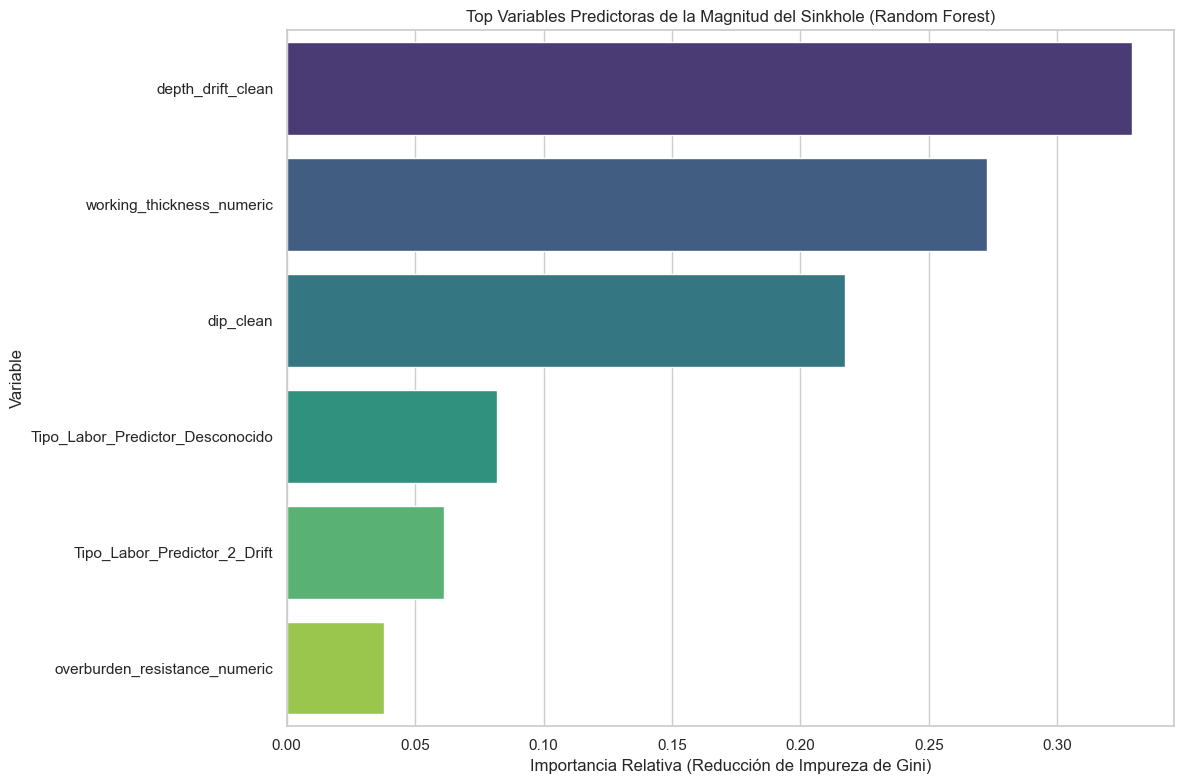


Ranking detallado de las 10 mejores variables:
                           Variable  Importancia
2                 depth_drift_clean     0.328960
1         working_thickness_numeric     0.272553
0                         dip_clean     0.217208
5  Tipo_Labor_Predictor_Desconocido     0.081952
4      Tipo_Labor_Predictor_2_Drift     0.061404
3     overburden_resistance_numeric     0.037924


In [191]:
# Definimos nuestras características (X) y nuestro objetivo (y)
X = df
y = df_pred_magnitud['Magnitud_Real']

# 3. PREPROCESAMIENTO RÁPIDO PARA EL SCREENING
# Random Forest necesita números y no acepta valores nulos (NaN)
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

# Imputar valores nulos: 
# Usamos la mediana para variables numéricas (como depth_drift_clean o Void density)
X[num_cols] = X[num_cols].fillna(X[num_cols].median())
# Rellenamos los nulos categóricos con una categoría nueva
X[cat_cols] = X[cat_cols].fillna('Desconocido')

# Convertir variables categóricas en columnas binarias (One-Hot Encoding)
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

# Convertir la variable objetivo (Bajo, Medio, Alto) a números (ej. 0, 1, 2)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. ENTRENAR EL MODELO RANDOM FOREST
print("Entrenando Random Forest para screening de variables...")
# n_estimators=100 es suficiente para screening. n_jobs=-1 usa todos los núcleos del PC.
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced')
rf.fit(X_encoded, y_encoded)

# 5. EXTRAER LA IMPORTANCIA DE LAS VARIABLES
importancias = rf.feature_importances_
variables = X_encoded.columns

# Crear un DataFrame para ordenar y visualizar mejor
df_importancia = pd.DataFrame({'Variable': variables, 'Importancia': importancias})
df_importancia = df_importancia.sort_values(by='Importancia', ascending=False)

# Tomamos el Top 20 de variables más importantes
top_20 = df_importancia.head(20)

# 6. VISUALIZACIÓN
plt.figure(figsize=(12, 8))
sns.barplot(x='Importancia', y='Variable', data=top_20, palette='viridis')
plt.title('Top Variables Predictoras de la Magnitud del Sinkhole (Random Forest)')
plt.xlabel('Importancia Relativa (Reducción de Impureza de Gini)')
plt.ylabel('Variable')
plt.tight_layout()

# Mostrar el gráfico en VS Code
plt.show()

# Opcional: Imprimir en la terminal de VS Code el ranking exacto
print("\nRanking detallado de las 10 mejores variables:")
print(top_20.head(10))

In [192]:
df_pred_magnitud.iloc[:, 14:35].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 17 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   depth_of_the_drift_relative_to_the_surface_m  1708 non-null   object  
 1   material_overbuden_resistance                 823 non-null    object  
 2   geology_of_the_overburden                     1868 non-null   object  
 3   presence_of_buildings_or_infrastructure       1232 non-null   object  
 4   geo_clean                                     1868 non-null   object  
 5   res_clean                                     1868 non-null   object  
 6   resistance_numeric                            426 non-null    float64 
 7   depth_drift_clean                             1339 non-null   float64 
 8   depth_range                                   1298 non-null   category
 9   working_thickness_numeric                     1102 n

Entrenando Random Forest para screening de variables...


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\708520284.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importancia', y='Variable', data=top_20, palette='viridis')


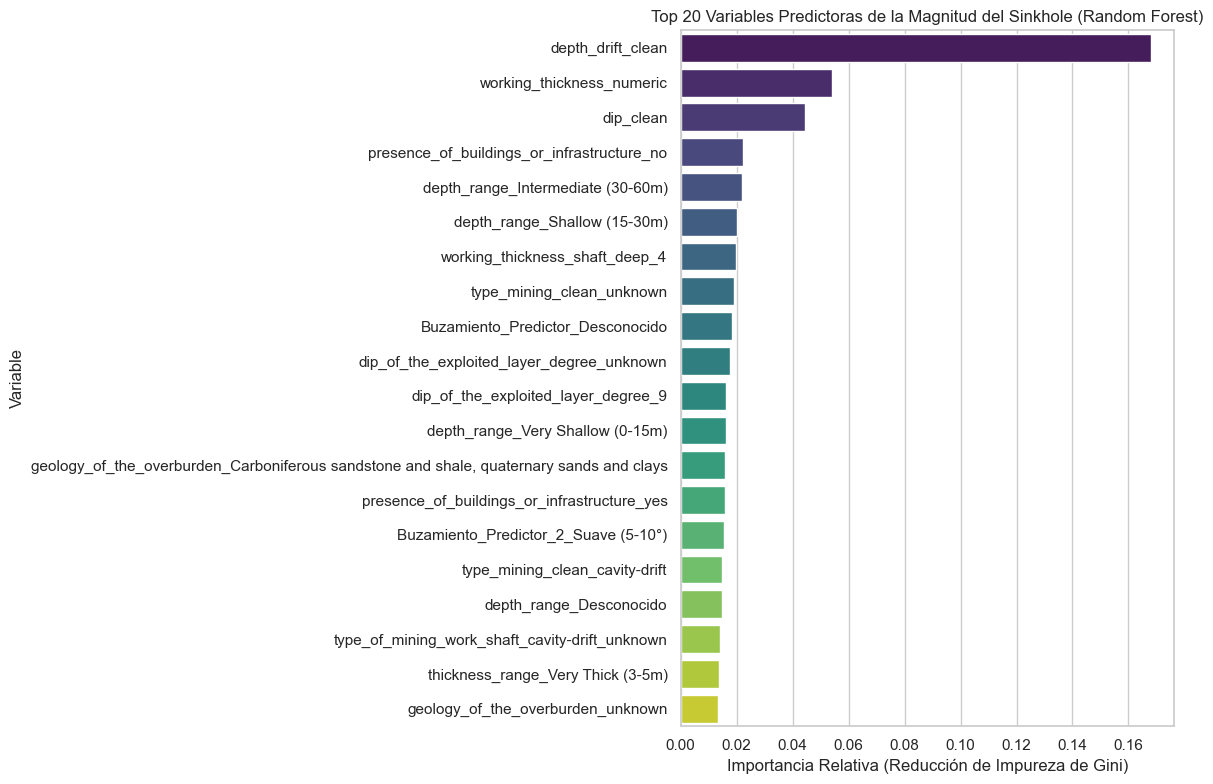


Ranking detallado de las 10 mejores variables:
                                       Variable  Importancia
0                             depth_drift_clean     0.167891
1                     working_thickness_numeric     0.054109
3                                     dip_clean     0.044410
205  presence_of_buildings_or_infrastructure_no     0.022218
208           depth_range_Intermediate (30-60m)     0.022017
209                depth_range_Shallow (15-30m)     0.019989
110              working_thickness_shaft_deep_4     0.019676
230                   type_mining_clean_unknown     0.019112
219            Buzamiento_Predictor_Desconocido     0.018214
60    dip_of_the_exploited_layer_degree_unknown     0.017615


In [193]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# 2. EVITAR DATA LEAKAGE (Trampa del modelo) Y LIMPIEZA BÁSICA
# Excluimos variables de identificación y las que usaste para crear 'Magnitud_Real'
columnas_a_excluir = [
    'Magnitud_Real', 
    'id_bd_sinkhole', 
    'number_of_sinkholes',
    'x_wgs84', 
    'depth_of_the_sinkhole_m',
    'length_diameter_m', 
    'y_wgs84',
    'in-situ_measurement_or_estimation',
    'date_of_appearance_of_the_sinkhole',
    "start_date_of_the_mining",
    "end_date_of_the_mining",
    "depth_of_the_drift_relative_to_the_surface_m",
    "geo_clean",
    "res_clean",
    "resistance_numeric",
    'y_wgs84'
]

# Filtramos solo las columnas que realmente existen en el dataframe
columnas_a_excluir = [col for col in columnas_a_excluir if col in df_pred_magnitud.columns]

# Definimos nuestras características (X) y nuestro objetivo (y)
X = df_pred_magnitud.drop(columns=columnas_a_excluir)
y = df_pred_magnitud['Magnitud_Real']

# 3. PREPROCESAMIENTO RÁPIDO PARA EL SCREENING
# Random Forest necesita números y no acepta valores nulos (NaN)
num_cols = X.select_dtypes(include=['int64', 'float64']).columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

# Imputar valores nulos: 
# Usamos la mediana para variables numéricas (como depth_drift_clean o Void density)
X[num_cols] = X[num_cols].fillna(X[num_cols].median())
# Convertimos las columnas a texto genérico para que Pandas nos deje introducir palabras nuevas
X[cat_cols] = X[cat_cols].astype('object')

# Ahora sí rellenamos los nulos categóricos con la nueva etiqueta
X[cat_cols] = X[cat_cols].fillna('Desconocido')

# Convertir variables categóricas en columnas binarias (One-Hot Encoding)
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

# Convertir la variable objetivo (Bajo, Medio, Alto) a números (ej. 0, 1, 2)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. ENTRENAR EL MODELO RANDOM FOREST
print("Entrenando Random Forest para screening de variables...")
# n_estimators=100 es suficiente para screening. n_jobs=-1 usa todos los núcleos del PC.
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1, class_weight='balanced')
rf.fit(X_encoded, y_encoded)

# 5. EXTRAER LA IMPORTANCIA DE LAS VARIABLES
importancias = rf.feature_importances_
variables = X_encoded.columns

# Crear un DataFrame para ordenar y visualizar mejor
df_importancia = pd.DataFrame({'Variable': variables, 'Importancia': importancias})
df_importancia = df_importancia.sort_values(by='Importancia', ascending=False)

# Tomamos el Top 20 de variables más importantes
top_20 = df_importancia.head(20)

# 6. VISUALIZACIÓN
plt.figure(figsize=(12, 8))
sns.barplot(x='Importancia', y='Variable', data=top_20, palette='viridis')
plt.title('Top 20 Variables Predictoras de la Magnitud del Sinkhole (Random Forest)')
plt.xlabel('Importancia Relativa (Reducción de Impureza de Gini)')
plt.ylabel('Variable')
plt.tight_layout()

# Mostrar el gráfico en VS Code
plt.show()

# Opcional: Imprimir en la terminal de VS Code el ranking exacto
print("\nRanking detallado de las 10 mejores variables:")
print(top_20.head(10))

--- ANÁLISIS DE VARIABLES CONTINUAS VS MAGNITUD ---
- Profundidad del Drift (m): p-value = 0.03146 (SIGNIFICATIVO)
- Espesor de Labor (m): p-value = 0.00000 (SIGNIFICATIVO)
- Buzamiento de la Capa (°): p-value = 0.08431 (NO significativo)


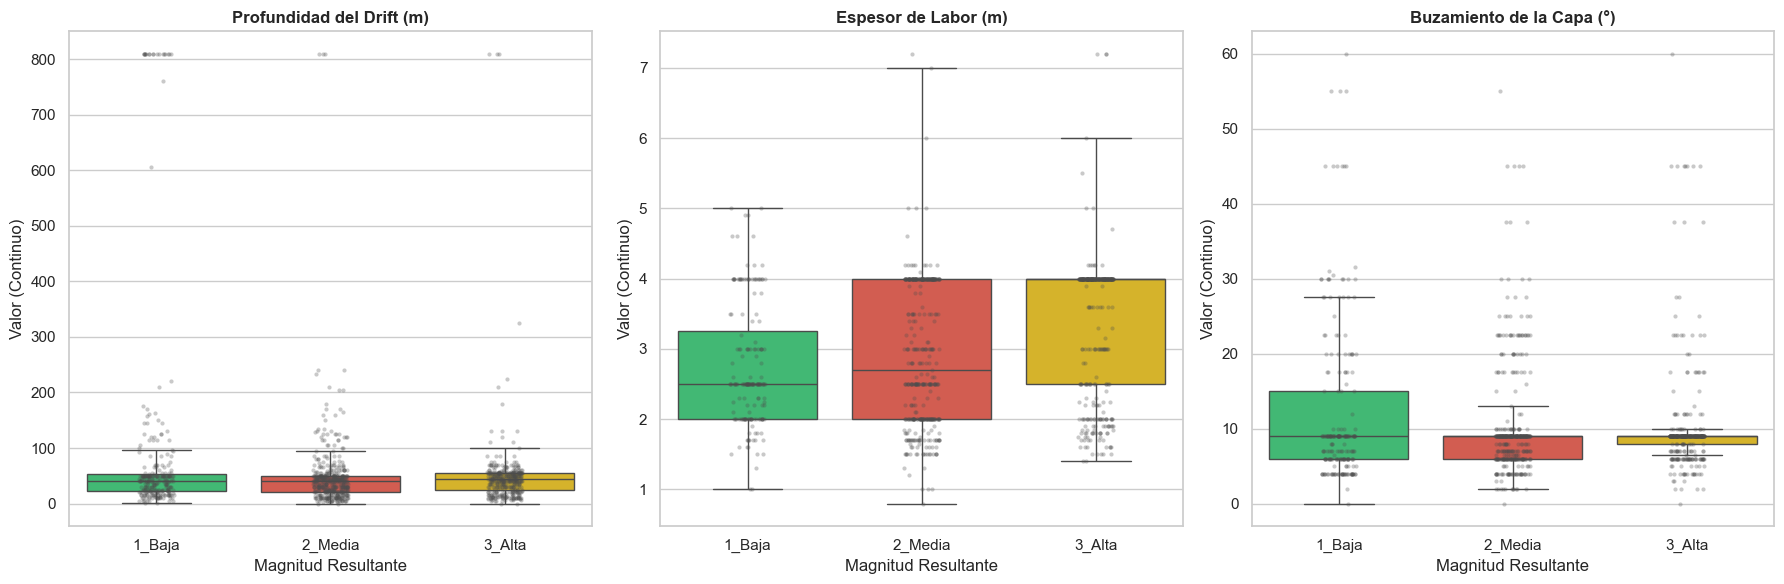


--- MEDIANAS DE LAS VARIABLES POR MAGNITUD (Tu guía para hacer cortes) ---

Profundidad del Drift (m):
Magnitud_Real
1_Baja     40.0
2_Media    40.0
3_Alta     45.0

Espesor de Labor (m):
Magnitud_Real
1_Baja     2.5
2_Media    2.7
3_Alta     4.0

Buzamiento de la Capa (°):
Magnitud_Real
1_Baja     9.0
2_Media    9.0
3_Alta     9.0


In [194]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kruskal

print("--- ANÁLISIS DE VARIABLES CONTINUAS VS MAGNITUD ---")

# Filtramos datos válidos
df_modelo = df_pred_magnitud.dropna(subset=['Magnitud_Real']).copy()

# Variables a analizar
variables_continuas = {
    'Profundidad del Drift (m)': 'depth_drift_clean',
    'Espesor de Labor (m)': 'working_thickness_numeric',
    'Buzamiento de la Capa (°)': 'dip_clean'
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
sns.set_theme(style="whitegrid")

for i, (titulo, col) in enumerate(variables_continuas.items()):
    if col in df_modelo.columns:
        # 1. Visualización: Boxplot (Con muestra de puntos para ver densidad)
        sns.boxplot(x='Magnitud_Real', y=col, data=df_modelo, ax=axes[i], hue='Magnitud_Real', legend=False,
                    order=['1_Baja', '2_Media', '3_Alta'], palette=['#2ecc71', '#f1c40f', '#e74c3c'], 
                    showfliers=False) # Ocultamos outliers extremos para ver la "caja" principal
        
        # Añadimos los puntos reales de fondo para más detalle
        sns.stripplot(x='Magnitud_Real', y=col, data=df_modelo, ax=axes[i], 
                      order=['1_Baja', '2_Media', '3_Alta'], color=".3", alpha=0.3, size=3, jitter=True)
        
        axes[i].set_title(titulo, fontweight='bold', fontsize=12)
        axes[i].set_xlabel('Magnitud Resultante')
        axes[i].set_ylabel('Valor (Continuo)')

        # 2. Prueba Estadística (Kruskal-Wallis)
        # Responde a: "¿Son los valores continuos estadísticamente distintos entre las 3 magnitudes?"
        grupos = [df_modelo[df_modelo['Magnitud_Real'] == mag][col].dropna() for mag in ['1_Baja', '2_Media', '3_Alta']]
        # Solo calculamos si hay datos suficientes en los 3 grupos
        if all(len(g) > 5 for g in grupos):
            stat, p_val = kruskal(*grupos)
            significancia = "SIGNIFICATIVO" if p_val < 0.05 else "NO significativo"
            print(f"- {titulo}: p-value = {p_val:.5f} ({significancia})")

plt.tight_layout()
plt.show()

# 3. Impresión de Medianas para guiar el Binning
print("\n--- MEDIANAS DE LAS VARIABLES POR MAGNITUD (Tu guía para hacer cortes) ---")
for titulo, col in variables_continuas.items():
    if col in df_modelo.columns:
        resumen = df_modelo.groupby('Magnitud_Real')[col].median().round(1)
        print(f"\n{titulo}:")
        print(resumen.to_string())

In [195]:
df_modelo.iloc[:,15:].info()

<class 'pandas.core.frame.DataFrame'>
Index: 1652 entries, 0 to 1867
Data columns (total 16 columns):
 #   Column                                   Non-Null Count  Dtype   
---  ------                                   --------------  -----   
 0   material_overbuden_resistance            745 non-null    object  
 1   geology_of_the_overburden                1652 non-null   object  
 2   presence_of_buildings_or_infrastructure  1070 non-null   object  
 3   geo_clean                                1652 non-null   object  
 4   res_clean                                1652 non-null   object  
 5   resistance_numeric                       349 non-null    float64 
 6   depth_drift_clean                        1157 non-null   float64 
 7   depth_range                              1117 non-null   category
 8   working_thickness_numeric                935 non-null    float64 
 9   thickness_range                          935 non-null    category
 10  overburden_resistance_numeric            

--- ANÁLISIS DE LAS CANDIDATAS CATEGÓRICAS VS MAGNITUD ---


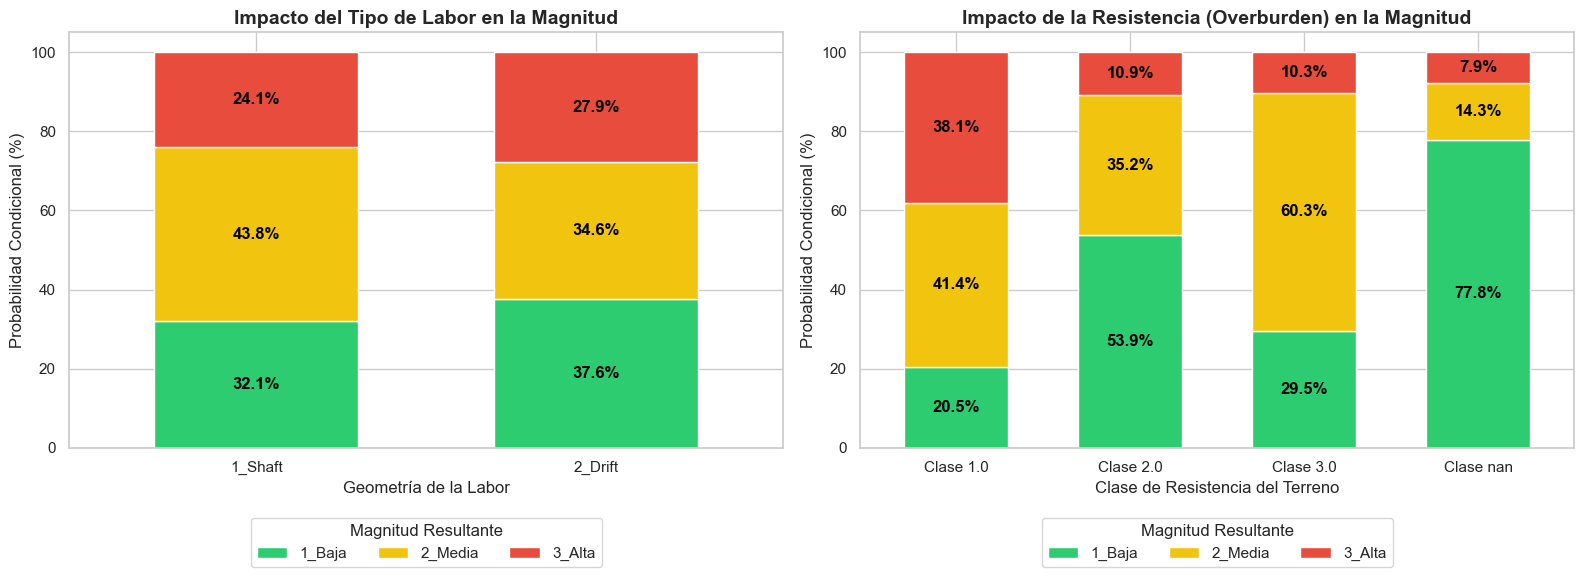

In [196]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("--- ANÁLISIS DE LAS CANDIDATAS CATEGÓRICAS VS MAGNITUD ---")

# Filtramos datos válidos
df_modelo = df_pred_magnitud.dropna(subset=['Magnitud_Real']).copy()

# Aseguramos que estén como categorías limpias
df_modelo['Cat_Labor'] = np.where(df_modelo['type_mining_clean'].astype(str).str.contains('shaft'), '1_Shaft', '2_Drift')
df_modelo['Cat_Resistance'] = 'Clase ' + df_modelo['overburden_resistance_numeric'].astype(str)

# Preparamos las tablas de contingencia normalizadas por fila (Probabilidad en %)
ct_labor = pd.crosstab(df_modelo['Cat_Labor'], df_modelo['Magnitud_Real'], normalize='index') * 100
ct_resistencia = pd.crosstab(df_modelo['Cat_Resistance'], df_modelo['Magnitud_Real'], normalize='index') * 100

# Colores para las magnitudes
colores_mag = ['#2ecc71', '#f1c40f', '#e74c3c']  # Verde (Baja), Amarillo (Media), Rojo (Alta)

# Configuración del gráfico
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# 1. Gráfico para Tipo de Labor
ct_labor.plot(kind='bar', stacked=True, color=colores_mag, ax=axes[0], edgecolor='white', width=0.6)
axes[0].set_title('Impacto del Tipo de Labor en la Magnitud', fontweight='bold', fontsize=14)
axes[0].set_xlabel('Geometría de la Labor')
axes[0].set_ylabel('Probabilidad Condicional (%)')
axes[0].legend(title='Magnitud Resultante', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
axes[0].tick_params(axis='x', rotation=0)

# Añadir porcentajes en el gráfico 1
for p in axes[0].patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy() 
    if height > 5:  # Solo mostramos si la barra tiene un tamaño visible
        axes[0].text(x+width/2, y+height/2, f"{height:.1f}%", ha='center', va='center', color='black', fontweight='bold')

# 2. Gráfico para Resistencia del Overburden
ct_resistencia.plot(kind='bar', stacked=True, color=colores_mag, ax=axes[1], edgecolor='white', width=0.6)
axes[1].set_title('Impacto de la Resistencia (Overburden) en la Magnitud', fontweight='bold', fontsize=14)
axes[1].set_xlabel('Clase de Resistencia del Terreno')
axes[1].set_ylabel('Probabilidad Condicional (%)')
axes[1].legend(title='Magnitud Resultante', loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3)
axes[1].tick_params(axis='x', rotation=0)

# Añadir porcentajes en el gráfico 2
for p in axes[1].patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy() 
    if height > 5:
        axes[1].text(x+width/2, y+height/2, f"{height:.1f}%", ha='center', va='center', color='black', fontweight='bold')

plt.tight_layout()
plt.show()

In [197]:
import pandas as pd
import numpy as np

print("--- CONSTRUCCIÓN DEL MODELO 3D DE PROBABILIDAD CONDICIONAL ---")

# 1. Aseguramos el DataFrame limpio y solo con las columnas necesarias
df_final = df_pred_magnitud.dropna(subset=['Magnitud_Real', 'working_thickness_numeric', 'dip_clean', 'overburden_resistance_numeric']).copy()

# 2. DISCRETIZACIÓN DE LAS 3 VARIABLES ESTRELLA
# A. Espesor (Guiado por las medianas que descubriste)
bins_thick = [-1, 2.0, 3.25, 100]
labels_thick = ['1_Delgada (<2.0m)', '2_Media (2.0-3.25m)', '3_Gruesa (>3.25m)']
df_final['Cat_Thickness'] = pd.cut(df_final['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

# B. Buzamiento
bins_dip = [-1, 5, 15, 90]
labels_dip = ['1_Plano (0-5°)', '2_Suave (5-15°)', '3_Inclinado (>15°)']
df_final['Cat_Dip'] = pd.cut(df_final['dip_clean'], bins=bins_dip, labels=labels_dip)

# C. Resistencia
df_final['Cat_Resistance'] = 'Clase_' + df_final['overburden_resistance_numeric'].astype(int).astype(str)

# 3. CREACIÓN DE LA MATRIZ DE PROBABILIDAD (La "Lookup Table")
# Agrupamos por los 3 factores y contamos cuántos casos caen en cada magnitud
matriz_conteos = df_final.groupby(['Cat_Thickness', 'Cat_Dip', 'Cat_Resistance'])['Magnitud_Real'].value_counts().unstack(fill_value=0)

# Convertimos los conteos absolutos a Probabilidades Condicionales (Porcentajes por fila)
matriz_probabilidad = matriz_conteos.div(matriz_conteos.sum(axis=1), axis=0) * 100

# Limpieza visual: redondear a 1 decimal y rellenar con NaN los escenarios donde nunca ha ocurrido nada en la historia
matriz_probabilidad = matriz_probabilidad.round(1).replace(0.0, np.nan).dropna(how='all')

# 4. AÑADIMOS EL NIVEL DE CONFIANZA (Soporte estadístico)
# Es vital saber con cuántos casos históricos se calculó cada probabilidad
matriz_probabilidad['Casos_Historicos'] = matriz_conteos.sum(axis=1)

# Ordenamos las columnas para mayor claridad
columnas_ordenadas = ['1_Baja', '2_Media', '3_Alta', 'Casos_Historicos']
matriz_probabilidad = matriz_probabilidad[[col for col in columnas_ordenadas if col in matriz_probabilidad.columns]]

print("\n--- LA TABLA DE BÚSQUEDA DEL MODELO PREDICTIVO (MATRIZ 3D) ---")
print("Lectura: Dado un escenario específico, ¿qué % de probabilidad existe para cada Magnitud?")
print("---------------------------------------------------------------------------------------")
print(matriz_probabilidad.to_string())

# 5. Exportar el modelo listo para usar en GIS o Producción
matriz_probabilidad.to_csv('Modelo_Magnitud_Sinkholes_3D_2.csv')
print("\n¡El modelo ha sido exportado exitosamente como 'Modelo_Magnitud_Sinkholes_3D.csv'!")

--- CONSTRUCCIÓN DEL MODELO 3D DE PROBABILIDAD CONDICIONAL ---

--- LA TABLA DE BÚSQUEDA DEL MODELO PREDICTIVO (MATRIZ 3D) ---
Lectura: Dado un escenario específico, ¿qué % de probabilidad existe para cada Magnitud?
---------------------------------------------------------------------------------------
Magnitud_Real                                          1_Baja  2_Media  3_Alta  Casos_Historicos
Cat_Thickness       Cat_Dip            Cat_Resistance                                           
1_Delgada (<2.0m)   1_Plano (0-5°)     Clase_1           24.4     48.9    26.7                45
                    2_Suave (5-15°)    Clase_1           16.7     45.5    37.9               132
                                       Clase_2          100.0      NaN     NaN                 2
                                       Clase_3            NaN     83.3    16.7                 6
                    3_Inclinado (>15°) Clase_1           13.6     61.4    25.0                44
                 

C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\1820545019.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  matriz_conteos = df_final.groupby(['Cat_Thickness', 'Cat_Dip', 'Cat_Resistance'])['Magnitud_Real'].value_counts().unstack(fill_value=0)


In [198]:
df_pred_magnitud.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 31 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   id_bd_sinkhole                                1868 non-null   object  
 1   x_wgs84                                       1868 non-null   float64 
 2   y_wgs84                                       1868 non-null   float64 
 3   number_of_sinkholes                           1841 non-null   object  
 4   length_diameter_m                             1724 non-null   object  
 5   depth_of_the_sinkhole_m                       1642 non-null   object  
 6   in-situ_measurement_or_estimation             1683 non-null   object  
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object  
 8   origin_of_collapse                            1778 non-null   object  
 9   start_date_of_the_mining                      1838 n

--- BUSCADOR MATEMÁTICO DE LÍMITES (THRESHOLDS) PARA ESPESOR ---


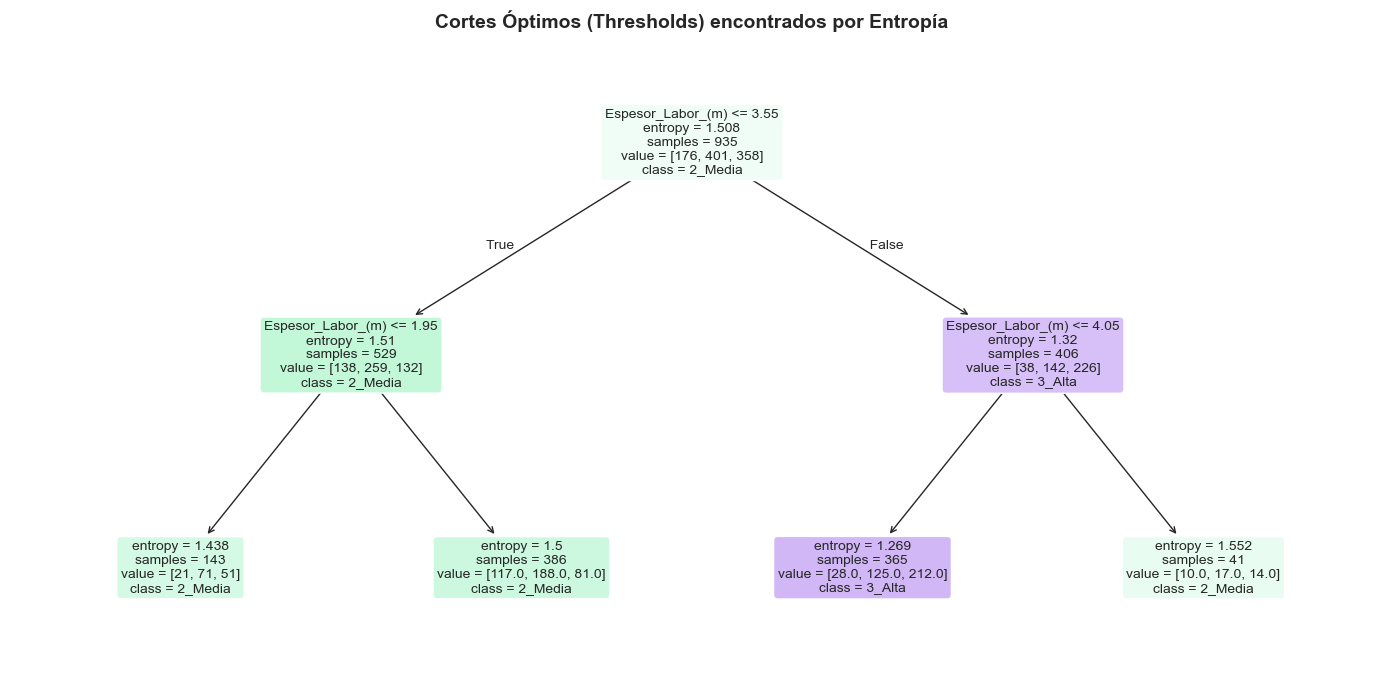

In [199]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

print("--- BUSCADOR MATEMÁTICO DE LÍMITES (THRESHOLDS) PARA ESPESOR ---")

# 1. Preparamos los datos limpios (solo necesitamos espesor y magnitud)
df_tree = df_pred_magnitud.dropna(subset=['working_thickness_numeric', 'Magnitud_Real']).copy()
X = df_tree[['working_thickness_numeric']] # working_thickness_numeric
y = df_tree['Magnitud_Real'] 

# 2. Creamos un Árbol muy superficial (max_depth=2 para que nos dé solo 3 o 4 grupos lógicos)
tree_model = DecisionTreeClassifier(max_depth=2, random_state=42, criterion='entropy')
tree_model.fit(X, y)

# 3. Dibujamos el árbol para ver exactamente DÓNDE hizo los cortes la matemática
plt.figure(figsize=(14, 7))
plot_tree(tree_model, 
          feature_names=['Espesor_Labor_(m)'], 
          class_names=['1_Baja', '2_Media', '3_Alta'], 
          filled=True, rounded=True, fontsize=10)

plt.title('Cortes Óptimos (Thresholds) encontrados por Entropía', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

In [200]:
df_pred_magnitud.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 31 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   id_bd_sinkhole                                1868 non-null   object  
 1   x_wgs84                                       1868 non-null   float64 
 2   y_wgs84                                       1868 non-null   float64 
 3   number_of_sinkholes                           1841 non-null   object  
 4   length_diameter_m                             1724 non-null   object  
 5   depth_of_the_sinkhole_m                       1642 non-null   object  
 6   in-situ_measurement_or_estimation             1683 non-null   object  
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object  
 8   origin_of_collapse                            1778 non-null   object  
 9   start_date_of_the_mining                      1838 n

In [201]:
import pandas as pd
import numpy as np

print("--- RECALCULANDO MAGNITUD OBJETIVO CON ÍNDICE PONDERADO ---")

df_recalc = df_mag.copy()

# 1. Definir los límites (Thresholds) para puntuar cada dimensión de 1 a 3
# Diámetro
bins_dia = [-1, 3, 8, 1000]
df_recalc['Score_Dia'] = pd.cut(df_recalc['diameter_sinkhole_clean'], bins=bins_dia, labels=[1, 2, 3]).astype(float)

# Profundidad
bins_dep = [-1, 1, 3, 1000]
df_recalc['Score_Dep'] = pd.cut(df_recalc['depth_sinkhole_clean'], bins=bins_dep, labels=[1, 2, 3]).astype(float)

# Número de Sinkholes
bins_num = [0, 1, 5, 1000]
df_recalc['Score_Num'] = pd.cut(df_recalc['number_sinkholes_clean'], bins=bins_num, labels=[1, 2, 3]).astype(float)

# 2. Definir los Pesos (Le quitamos el poder al Número)
w_dia = 0.45
w_dep = 0.45
w_num = 0.10  # Solo aporta un 10% al riesgo total

# 3. Calcular el Índice de Severidad Continuo (Irá de 1.0 a 3.0)
df_recalc['Indice_Severidad'] = (
    (df_recalc['Score_Dia'] * w_dia) + 
    (df_recalc['Score_Dep'] * w_dep) + 
    (df_recalc['Score_Num'] * w_num)
)

# 4. Convertir el Índice nuevamente a Categorías (Baja, Media, Alta)
# Si el índice es <= 1.5 es Baja. Si es >= 2.5 es Alta.
bins_final = [0.0, 1.6, 2.4, 4.0]
labels_final = ['1_Baja', '2_Media', '3_Alta']
df_recalc['Magnitud_Real_Corregida'] = pd.cut(df_recalc['Indice_Severidad'], bins=bins_final, labels=labels_final)

# Imprimir un cuadro comparativo del antes y el después
print("\nCasos donde un 'Enjambre' de hundimientos pequeños dejó de ser Alta:")
# Buscamos los que antes eran alta, pero tenían diámetros y profundidades de nivel 1
falsas_altas = df_recalc[
    (df_recalc['Magnitud_Real'] == '3_Alta') & 
    (df_recalc['Score_Dia'] == 1) & 
    (df_recalc['Score_Dep'] == 1)
]

print(f"Se corrigieron {len(falsas_altas)} casos inflados.")
if not falsas_altas.empty:
    columnas_ver = ['length_diameter_m', 'depth_of_the_sinkhole_m', 'number_of_sinkholes', 'Magnitud_Real', 'Magnitud_Real_Corregida']
    print(falsas_altas[columnas_ver].head(20).to_string())

--- RECALCULANDO MAGNITUD OBJETIVO CON ÍNDICE PONDERADO ---

Casos donde un 'Enjambre' de hundimientos pequeños dejó de ser Alta:
Se corrigieron 0 casos inflados.


In [202]:
# Añadir Variable Objetivo
df_pred_magnitud_2 = df_pred_magnitud.merge(
    df_recalc[['id_bd_sinkhole', 'Magnitud_Real_Corregida']], 
    on='id_bd_sinkhole', 
    how='left')

In [203]:
import pandas as pd
import numpy as np

print("--- CONSTRUCCIÓN DEL MODELO 3D DE PROBABILIDAD CONDICIONAL ---")

# 1. Aseguramos el DataFrame limpio y solo con las columnas necesarias
df_final = df_pred_magnitud_2.dropna(subset=['Magnitud_Real_Corregida', 'working_thickness_numeric', 'dip_clean', 'overburden_resistance_numeric', "depth_drift_clean"]).copy()

# 2. DISCRETIZACIÓN DE LAS 3 VARIABLES ESTRELLA
# A. Espesor (Guiado por las medianas que descubriste)
bins_thick = [-1, 2.0, 3.25, 100]
labels_thick = ['1_Delgada (<2.0m)', '2_Media (2.0-3.25m)', '3_Gruesa (>3.25m)']
df_final['Cat_Thickness'] = pd.cut(df_final['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

# B. Buzamiento
bins_dip = [-1, 5, 15, 90]
labels_dip = ['1_Plano (0-5°)', '2_Suave (5-15°)', '3_Inclinado (>15°)']
df_final['Cat_Dip'] = pd.cut(df_final['dip_clean'], bins=bins_dip, labels=labels_dip)

# C. Resistencia
df_final['Cat_Resistance'] = 'Clase_' + df_final['overburden_resistance_numeric'].astype(int).astype(str)

# C.2 Depth
bins_dip = [-1, 30, 60, 900]
labels_dip = ['1_Somero (0-30m)', '2_Medio (30-60m)', '3_Profundo (>60m)']
df_final['Cat_Depth'] = pd.cut(df_final['depth_drift_clean'], bins=bins_dip, labels=labels_dip)

# 3. CREACIÓN DE LA MATRIZ DE PROBABILIDAD (La "Lookup Table")
# Agrupamos por los 3 factores y contamos cuántos casos caen en cada magnitud
matriz_conteos = df_final.groupby(['Cat_Thickness', 'Cat_Dip', 'Cat_Resistance'])['Magnitud_Real_Corregida'].value_counts().unstack(fill_value=0)

# Convertimos los conteos absolutos a Probabilidades Condicionales (Porcentajes por fila)
matriz_probabilidad = matriz_conteos.div(matriz_conteos.sum(axis=1), axis=0) * 100

# Limpieza visual: redondear a 1 decimal y rellenar con NaN los escenarios donde nunca ha ocurrido nada en la historia
matriz_probabilidad = matriz_probabilidad.round(1).replace(0.0, np.nan).dropna(how='all')

# 4. AÑADIMOS EL NIVEL DE CONFIANZA (Soporte estadístico)
# Es vital saber con cuántos casos históricos se calculó cada probabilidad
matriz_probabilidad['Casos_Historicos'] = matriz_conteos.sum(axis=1)

# Ordenamos las columnas para mayor claridad
columnas_ordenadas = ['1_Baja', '2_Media', '3_Alta', 'Casos_Historicos']
matriz_probabilidad = matriz_probabilidad[[col for col in columnas_ordenadas if col in matriz_probabilidad.columns]]

print("\n--- LA TABLA DE BÚSQUEDA DEL MODELO PREDICTIVO (MATRIZ 3D) ---")
print("Lectura: Dado un escenario específico, ¿qué % de probabilidad existe para cada Magnitud?")
print("---------------------------------------------------------------------------------------")
print(matriz_probabilidad.to_string())

# 5. Exportar el modelo listo para usar en GIS o Producción
matriz_probabilidad.to_csv('Modelo_Magnitud_Sinkholes_3D_2.csv')
print("\n¡El modelo ha sido exportado exitosamente como 'Modelo_Magnitud_Sinkholes_3D.csv'!")

--- CONSTRUCCIÓN DEL MODELO 3D DE PROBABILIDAD CONDICIONAL ---

--- LA TABLA DE BÚSQUEDA DEL MODELO PREDICTIVO (MATRIZ 3D) ---
Lectura: Dado un escenario específico, ¿qué % de probabilidad existe para cada Magnitud?
---------------------------------------------------------------------------------------
Magnitud_Real_Corregida                                1_Baja  2_Media  3_Alta  Casos_Historicos
Cat_Thickness       Cat_Dip            Cat_Resistance                                           
1_Delgada (<2.0m)   1_Plano (0-5°)     Clase_1           48.6     45.7     5.7                35
                    2_Suave (5-15°)    Clase_1           44.8     36.8    18.4               125
                                       Clase_2          100.0      NaN     NaN                 1
                                       Clase_3           50.0     50.0     NaN                 6
                    3_Inclinado (>15°) Clase_1           41.9     58.1     NaN                43
                 

C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\2707280603.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  matriz_conteos = df_final.groupby(['Cat_Thickness', 'Cat_Dip', 'Cat_Resistance'])['Magnitud_Real_Corregida'].value_counts().unstack(fill_value=0)


### MAGNITUD CONDICIONAL (COMBINACION DE DIAMETRO Y PROFUNDIDAD) 

In [204]:
df_pred_magnitud.iloc[:,10:].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 21 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   end_date_of_the_mining                        1858 non-null   object  
 1   dip_of_the_exploited_layer_degree             1664 non-null   object  
 2   type_of_mining_work_shaft_cavity-drift        1825 non-null   object  
 3   working_thickness_shaft_deep                  1542 non-null   object  
 4   depth_of_the_drift_relative_to_the_surface_m  1708 non-null   object  
 5   material_overbuden_resistance                 823 non-null    object  
 6   geology_of_the_overburden                     1868 non-null   object  
 7   presence_of_buildings_or_infrastructure       1232 non-null   object  
 8   geo_clean                                     1868 non-null   object  
 9   res_clean                                     1868 n

--- ANÁLISIS DE RELACIÓN: DIÁMETRO VS PROFUNDIDAD ---


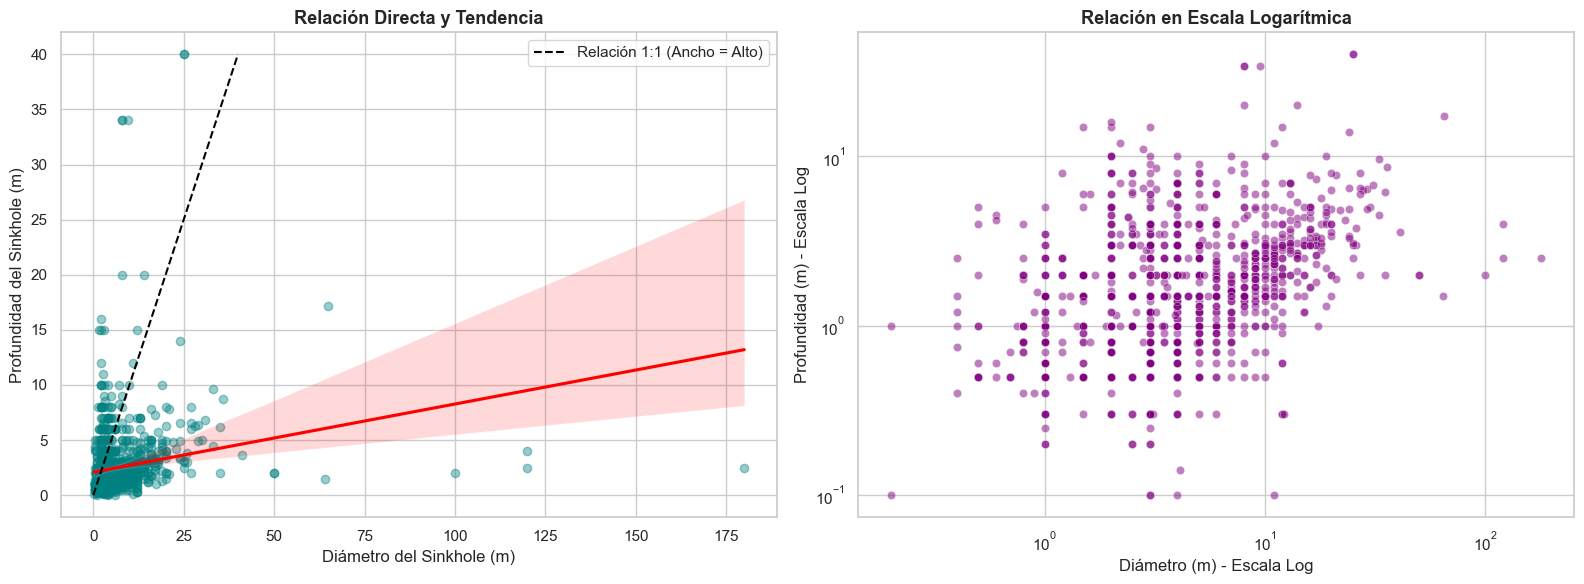


--- RESULTADOS ESTADÍSTICOS ---
Total de casos analizados: 1158
Correlación de Pearson (Lineal): 0.191 (Rango de -1 a 1)
Correlación de Spearman (Ranking): 0.380 (Rango de -1 a 1)

--- FORMA GEOMÉTRICA DOMINANTE ---
Más anchos que profundos (Forma de Plato): 889 casos (76.8%)
Más profundos que anchos (Forma Chimenea): 189 casos (16.3%)
Totalmente simétricos (Diámetro = Profundidad): 80 casos (6.9%)


In [205]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("--- ANÁLISIS DE RELACIÓN: DIÁMETRO VS PROFUNDIDAD ---")

# 1. Filtramos los datos válidos (eliminamos nulos en estas dos columnas específicas)
df_relacion = df_mag.dropna(subset=['diameter_sinkhole_clean', 'depth_sinkhole_clean']).copy()

# 2. Configuración del lienzo
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.set_theme(style="whitegrid")

# GRÁFICO 1: Escala Normal con Línea de Tendencia
sns.regplot(data=df_relacion, x='diameter_sinkhole_clean', y='depth_sinkhole_clean', 
            ax=axes[0], scatter_kws={'alpha':0.4, 'color':'teal'}, line_kws={'color':'red'})

# Añadimos la línea 1:1 (donde Diámetro = Profundidad)
max_val = min(df_relacion['diameter_sinkhole_clean'].max(), df_relacion['depth_sinkhole_clean'].max())
axes[0].plot([0, max_val], [0, max_val], color='black', linestyle='--', label='Relación 1:1 (Ancho = Alto)')

axes[0].set_title('Relación Directa y Tendencia', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Diámetro del Sinkhole (m)')
axes[0].set_ylabel('Profundidad del Sinkhole (m)')
axes[0].legend()

# GRÁFICO 2: Escala Logarítmica 
# (Ayuda a ver la concentración de la "nube" cuando hay muchos eventos pequeños y pocos gigantes)
sns.scatterplot(data=df_relacion, x='diameter_sinkhole_clean', y='depth_sinkhole_clean', 
                ax=axes[1], alpha=0.5, color='purple')

axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_title('Relación en Escala Logarítmica', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Diámetro (m) - Escala Log')
axes[1].set_ylabel('Profundidad (m) - Escala Log')

plt.tight_layout()
plt.show()

# 3. Pruebas Matemáticas de Correlación
corr_pearson = df_relacion['diameter_sinkhole_clean'].corr(df_relacion['depth_sinkhole_clean'])
corr_spearman = df_relacion['diameter_sinkhole_clean'].corr(df_relacion['depth_sinkhole_clean'], method='spearman')

print("\n--- RESULTADOS ESTADÍSTICOS ---")
print(f"Total de casos analizados: {len(df_relacion)}")
print(f"Correlación de Pearson (Lineal): {corr_pearson:.3f} (Rango de -1 a 1)")
print(f"Correlación de Spearman (Ranking): {corr_spearman:.3f} (Rango de -1 a 1)")

# 4. Análisis de Proporción (Forma del Sinkhole)
mas_anchos = len(df_relacion[df_relacion['diameter_sinkhole_clean'] > df_relacion['depth_sinkhole_clean']])
mas_profundos = len(df_relacion[df_relacion['depth_sinkhole_clean'] > df_relacion['diameter_sinkhole_clean']])
simetricos = len(df_relacion[df_relacion['diameter_sinkhole_clean'] == df_relacion['depth_sinkhole_clean']])

print("\n--- FORMA GEOMÉTRICA DOMINANTE ---")
print(f"Más anchos que profundos (Forma de Plato): {mas_anchos} casos ({(mas_anchos/len(df_relacion))*100:.1f}%)")
print(f"Más profundos que anchos (Forma Chimenea): {mas_profundos} casos ({(mas_profundos/len(df_relacion))*100:.1f}%)")
print(f"Totalmente simétricos (Diámetro = Profundidad): {simetricos} casos ({(simetricos/len(df_relacion))*100:.1f}%)")

In [206]:
import pandas as pd
import numpy as np

print("--- RECALCULANDO MAGNITUD (GEOMETRÍA PURA) ---")

df_geom = df_mag.copy()

# 1. Puntaje del Diámetro (Ajusta los límites -bins- en metros si es necesario)
bins_dia = [-1, 1, 5, 1000]
df_geom['Score_Dia'] = pd.cut(df_geom['diameter_sinkhole_clean'], bins=bins_dia, labels=[1, 2, 3]).astype(float)

# 2. Puntaje de la Profundidad (Ajusta los límites -bins- en metros si es necesario)
bins_dep = [-1, 1, 3, 1000]
df_geom['Score_Dep'] = pd.cut(df_geom['depth_sinkhole_clean'], bins=bins_dep, labels=[1, 2, 3]).astype(float)

# 3. Suma Geométrica (Rango de 2 a 6)
df_geom['Suma_Geometrica'] = df_geom['Score_Dia'] + df_geom['Score_Dep']

# 4. Traducción a Magnitud (2-3: Baja | 4: Media | 5-6: Alta)
bins_mag = [0, 3.5, 4.5, 10]
labels_mag = ['1_Baja', '2_Media', '3_Alta']
df_geom['Magnitud_Real_Pura'] = pd.cut(df_geom['Suma_Geometrica'], bins=bins_mag, labels=labels_mag)

# Mostramos el cambio en la distribución
df_geom.info()

print("\nDistribución NUEVA de Magnitudes (Geometría Pura):")
print(df_geom['Magnitud_Real_Pura'].value_counts().sort_index())

--- RECALCULANDO MAGNITUD (GEOMETRÍA PURA) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   id_bd_sinkhole           1868 non-null   object  
 1   x_laea                   1868 non-null   float64 
 2   y_laea                   1868 non-null   float64 
 3   length_diameter_m        1724 non-null   object  
 4   depth_of_the_sinkhole_m  1642 non-null   object  
 5   origin_of_collapse       1778 non-null   object  
 6   number_of_sinkholes      1841 non-null   object  
 7   number_sinkholes_clean   1835 non-null   float64 
 8   diameter_sinkhole_clean  1263 non-null   float64 
 9   depth_sinkhole_clean     1547 non-null   float64 
 10  origin_collapse_clean    1353 non-null   string  
 11  score_diam               1263 non-null   float64 
 12  score_depth              1547 non-null   float64 
 13  score_number    

In [207]:
# Unimos las variables predictoras con la Magnitud_Real_Pura
df_modelo_mag = df_pred_magnitud.merge(
    df_geom[['id_bd_sinkhole', 'Magnitud_Real_Pura']], 
    on='id_bd_sinkhole', 
    how='left')

In [208]:
columnas_modelo = ['Magnitud_Real_Pura', 'working_thickness_numeric', 'dip_clean', 'overburden_resistance_numeric']
df_modelo_mag[columnas_modelo].dropna().info()

<class 'pandas.core.frame.DataFrame'>
Index: 814 entries, 75 to 1867
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   Magnitud_Real_Pura             814 non-null    category
 1   working_thickness_numeric      814 non-null    float64 
 2   dip_clean                      814 non-null    float64 
 3   overburden_resistance_numeric  814 non-null    float64 
dtypes: category(1), float64(3)
memory usage: 26.4 KB


In [209]:
import pandas as pd
import numpy as np

print("--- GENERANDO EL MODELO PREDICTIVO FINAL (PROBABILIDAD CONDICIONAL 3D) ---")

# 1. Filtramos los datos válidos (Intersección estricta de Predictores + Nueva Magnitud)
columnas_modelo = ['Magnitud_Real_Pura', 'working_thickness_numeric', 'dip_clean', 'overburden_resistance_numeric']
df_modelo_final = df_modelo_mag.dropna(subset=columnas_modelo).copy()

# 2. DISCRETIZACIÓN DE PREDICTORES (Con los cortes matemáticos validados)
# A. Espesor (Límite optimizado por Entropía a 3.25m)
bins_thick = [-1, 2.0, 3.25, 100]
labels_thick = ['1_Delgada (<2.0m)', '2_Media (2.0-3.25m)', '3_Gruesa (>3.25m)']
df_modelo_final['Cat_Thickness'] = pd.cut(df_modelo_final['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

# B. Buzamiento (Límites normativos geológicos)
bins_dip = [-1, 5, 15, 90]
labels_dip = ['1_Plano (0-5°)', '2_Suave (5-15°)', '3_Inclinado (>15°)']
df_modelo_final['Cat_Dip'] = pd.cut(df_modelo_final['dip_clean'], bins=bins_dip, labels=labels_dip)

# C. Resistencia del Terreno
df_modelo_final['Cat_Resistance'] = 'Clase_' + df_modelo_final['overburden_resistance_numeric'].astype(int).astype(str)

# 3. CREACIÓN DE LA MATRIZ DE BÚSQUEDA (Lookup Table)
# Contamos cuántos colapsos cayeron en cada nueva magnitud para cada escenario
matriz_conteos = df_modelo_final.groupby(['Cat_Thickness', 'Cat_Dip', 'Cat_Resistance'])['Magnitud_Real_Pura'].value_counts().unstack(fill_value=0)

# Convertimos a Probabilidades (Porcentajes horizontales)
matriz_prob = matriz_conteos.div(matriz_conteos.sum(axis=1), axis=0) * 100

# Limpieza: Redondear a 1 decimal y eliminar escenarios que nunca han ocurrido
matriz_prob = matriz_prob.round(1).replace(0.0, np.nan).dropna(how='all')

# Agregamos la columna vital de Confianza Estadística
matriz_prob['Casos_Historicos'] = matriz_conteos.sum(axis=1)

# Ordenamos las columnas para lectura intuitiva
columnas_ordenadas = ['1_Baja', '2_Media', '3_Alta', 'Casos_Historicos']
matriz_prob = matriz_prob[[col for col in columnas_ordenadas if col in matriz_prob.columns]]

print("\n=========================================================================================")
print("         MATRIZ DE PROBABILIDAD CONDICIONAL DE MAGNITUD (VERSIÓN GEOMÉTRICA PURA)        ")
print("=========================================================================================")
print(matriz_prob.to_string())
print("=========================================================================================")

# 4. Guardado del modelo listo para implementar en GIS o software de minería
matriz_prob.to_csv('Modelo_Predictivo_Sinkholes_Geometria_Pura.csv')
print("\n¡Modelo final exportado exitosamente como 'Modelo_Predictivo_Sinkholes_Geometria_Pura.csv'!")

--- GENERANDO EL MODELO PREDICTIVO FINAL (PROBABILIDAD CONDICIONAL 3D) ---

         MATRIZ DE PROBABILIDAD CONDICIONAL DE MAGNITUD (VERSIÓN GEOMÉTRICA PURA)        
Magnitud_Real_Pura                                     1_Baja  2_Media  3_Alta  Casos_Historicos
Cat_Thickness       Cat_Dip            Cat_Resistance                                           
1_Delgada (<2.0m)   1_Plano (0-5°)     Clase_1           27.5     40.0    32.5                40
                    2_Suave (5-15°)    Clase_1           28.0     36.0    36.0               125
                                       Clase_2          100.0      NaN     NaN                 1
                                       Clase_3           16.7     50.0    33.3                 6
                    3_Inclinado (>15°) Clase_1           25.6     37.2    37.2                43
                                       Clase_2           50.0      NaN    50.0                 2
2_Media (2.0-3.25m) 1_Plano (0-5°)     Clase_1           4

C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\2171077690.py:26: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  matriz_conteos = df_modelo_final.groupby(['Cat_Thickness', 'Cat_Dip', 'Cat_Resistance'])['Magnitud_Real_Pura'].value_counts().unstack(fill_value=0)


## MODELO FINAL

Se concluyó que se va a crear la variable categorica de Magnitud solo de acuerdo a la Profundidad y el Diametro del sinkhole. Se define la magnitud por el peor de los casos. Es decir, se escoge el valor maximo de uno de los dos y se define la categoria de acuerdo a la tabla heuristica.

In [210]:
import pandas as pd
import numpy as np

print("--- 1. CREACIÓN DE MAGNITUD (ENFOQUE DEL PEOR ESCENARIO) ---")

# A. Puntaje del Diámetro (1: <3m | 2: 3-8m | 3: >8m) - Ajusta si es necesario
bins_dia = [-1, 3, 8, 1000]
df_geom['Score_Dia'] = pd.cut(df_geom['diameter_sinkhole_clean'], bins=bins_dia, labels=[1, 2, 3]).astype(float)

# B. Puntaje de la Profundidad (1: <1m | 2: 1-3m | 3: >3m) - Ajusta si es necesario
bins_dep = [-1, 1, 3, 1000]
df_geom['Score_Dep'] = pd.cut(df_geom['depth_sinkhole_clean'], bins=bins_dep, labels=[1, 2, 3]).astype(float)

# C. Lógica del Peor Escenario: Extraemos el máximo valor entre los dos puntajes
df_geom['Score_Max'] = df_geom[['Score_Dia', 'Score_Dep']].max(axis=1)

# D. Traducción directa a Categorías
mapa_magnitud = {1.0: '1_Baja', 2.0: '2_Media', 3.0: '3_Alta'}
df_geom['Magnitud_Real_Peor_Caso'] = df_geom['Score_Max'].map(mapa_magnitud)

--- 1. CREACIÓN DE MAGNITUD (ENFOQUE DEL PEOR ESCENARIO) ---


In [211]:
# Unimos las variables predictoras con la Magnitud_Real_Pura
df_modelo_mag_simple = df_pred_magnitud.merge(
    df_geom[['id_bd_sinkhole', 'Magnitud_Real_Peor_Caso']], 
    on='id_bd_sinkhole', 
    how='left')

In [225]:
print("\n--- 2. GENERANDO MATRIZ PREDICTIVA 3D ACTUALIZADA ---")

# Filtramos los datos listos para el modelo
columnas_modelo = ['Magnitud_Real_Peor_Caso', 'working_thickness_numeric', 'dip_clean']
df_modelo_final = df_modelo_mag_simple.dropna(subset=columnas_modelo).copy()

# Discretización validada
bins_thick = [-1, 2.0, 3.25, 100]
labels_thick = ['1_Delgada (<2.0m)', '2_Media (2.0-3.25m)', '3_Gruesa (>3.25m)']
df_modelo_final['Cat_Thickness'] = pd.cut(df_modelo_final['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

bins_dip = [-1, 5, 15, 90]
labels_dip = ['1_Plano (0-5°)', '2_Suave (5-15°)', '3_Inclinado (>15°)']
df_modelo_final['Cat_Dip'] = pd.cut(df_modelo_final['dip_clean'], bins=bins_dip, labels=labels_dip)

#df_modelo_final['Cat_Resistance'] = 'Clase_' + df_modelo_final['overburden_resistance_numeric'].astype(int).astype(str)

# Construcción de la Matriz Condicional
matriz_conteos = df_modelo_final.groupby(['Cat_Thickness', 'Cat_Dip'])['Magnitud_Real_Peor_Caso'].value_counts().unstack(fill_value=0)
matriz_prob_magnitud = matriz_conteos.div(matriz_conteos.sum(axis=1), axis=0) * 100
matriz_prob_magnitud = matriz_prob_magnitud.round(1).replace(0.0, np.nan).dropna(how='all')
matriz_prob_magnitud['Casos_Historicos'] = matriz_conteos.sum(axis=1)

columnas_ordenadas = ['1_Baja', '2_Media', '3_Alta', 'Casos_Historicos']
matriz_prob_magnitud = matriz_prob_magnitud[[col for col in columnas_ordenadas if col in matriz_prob_magnitud.columns]]

print("\n=========================================================================================")
print("  MATRIZ DE PROBABILIDAD CONDICIONAL (ENFOQUE: PEOR CASO GEOMÉTRICO)                     ")
print("=========================================================================================")
print(matriz_prob_magnitud.to_string())
print("=========================================================================================")

# Guardado
matriz_prob_magnitud.to_csv('Modelo_Predictivo_Peor_Caso_final.csv')


--- 2. GENERANDO MATRIZ PREDICTIVA 3D ACTUALIZADA ---

  MATRIZ DE PROBABILIDAD CONDICIONAL (ENFOQUE: PEOR CASO GEOMÉTRICO)                     
Magnitud_Real_Peor_Caso                 1_Baja  2_Media  3_Alta  Casos_Historicos
Cat_Thickness       Cat_Dip                                                      
1_Delgada (<2.0m)   1_Plano (0-5°)        24.4     48.9    26.7                45
                    2_Suave (5-15°)       17.1     46.4    36.4               140
                    3_Inclinado (>15°)    14.9     59.6    25.5                47
2_Media (2.0-3.25m) 1_Plano (0-5°)        47.6     31.0    21.4                42
                    2_Suave (5-15°)       24.1     51.9    24.1               133
                    3_Inclinado (>15°)    33.3     16.7    50.0                 6
3_Gruesa (>3.25m)   1_Plano (0-5°)        30.8     61.5     7.7                13
                    2_Suave (5-15°)        9.5     36.4    54.0               420


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\2734639355.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  matriz_conteos = df_modelo_final.groupby(['Cat_Thickness', 'Cat_Dip'])['Magnitud_Real_Peor_Caso'].value_counts().unstack(fill_value=0)


### Exportacion de resultados para empaquetamiento

Estos archivos .parquet contienen los datasets procesados con los calculos realizados durante este estudio. Se pretende que estos archivos sirvan en caso que se quiera actualizar los parametros de los modelos de susceptibilidad y magnitud y a su vez éstos se puedan actualizar automaticamente usando la data final, es decir, la data de los .parquet. Esto evita que se guarden valores estaticos, como la tabla cruzada del modelo de magnitud.

Esto se debe integrar en el archivo train_and_package.py, en el cual se van a realizar las actualizaciones de los parametros y a su vez, estos van a generar los archivos .pkl que va a guardar la informacion empaquetada de los parametros de los modelos. 

In [214]:
# DF del modelo de magnitud para parquet
columnas = ['id_bd_sinkhole', 'Magnitud_Real_Peor_Caso', 'working_thickness_numeric', 'dip_clean', 'overburden_resistance_numeric']
df_magnitud_parquet = df_modelo_mag_simple[columnas]

In [215]:
import os

# 1. Definimos la ruta relativa (subir un nivel, entrar a data/processed)
ruta_procesados = '../data/processed/'

# 2. Asegurar que la carpeta exista
os.makedirs(ruta_procesados, exist_ok=True)

# 3. Exportar ambos DataFrames a formato Parquet
df_ml.to_parquet(ruta_procesados + 'df_ml.parquet', index=False)
modelo_granular_susceptibilidad.to_parquet(ruta_procesados + 'modelo_granular.parquet', index=False)
df_magnitud_parquet.to_parquet(ruta_procesados + 'modelo_magnitud.parquet', index=False)

print(f"✅ Archivos exportados exitosamente en: {ruta_procesados}")

✅ Archivos exportados exitosamente en: ../data/processed/


# EMPAQUETADO E INTEGRACION DE MODELOS

In [226]:
import pickle
import numpy as np
import jenkspy

print("Empaquetando el Motor SIRIMA Definitivo (Susceptibilidad + Magnitud)...")

# 1. PARÁMETROS DE NORMALIZACIÓN (Profundidad y Espesor)
# 1.1. Para profundidad (Log-Inverse Min-Max)
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'].dropna())
log_min_depth, log_max_depth = log_depth.min(), log_depth.max()

# 1.2. Para espesor (Normalizacion linear Min-Max)
thick_min = modelo_granular_susceptibilidad['working_thickness_numeric'].min()
thick_max = modelo_granular_susceptibilidad['working_thickness_numeric'].max()

# 1.3. UMBRALES MAESTROS JENKS (usando TODOS los datos de la base de datos o catalogo)
scores_finales = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna().values
master_breaks = jenkspy.jenks_breaks(scores_finales, n_classes=3)

# 2. PARAMETROS DE MODELO DE MAGNITUD (PROBABILIDAD CONDICIONAL)
# Convertimos la matriz 3D de magnitud en un diccionario nativo de Python para búsquedas ultrarrápidas
diccionario_magnitud = matriz_prob_magnitud.to_dict('index')

# Construcción del Gran Diccionario Maestro V3
pipeline_sirima = {
    'version': '3.0_SIRIMA_Full_Hazard',
    
    # --- 1. MÓDULO GEOLÓGICO SUPERVISADO (NLP) ---
    'nlp_vectorizer': vectorizer,
    'nlp_classifier': rf_classifier,
    
    # --- 2. MÓDULO DE SUSCEPTIBILIDAD ---
    'pesos': {'alpha': 0.4, 'beta': 0.3, 'gamma': 0.3},
    'mapeo_res_a_peso': {1: 0.70, 2: 0.35, 3: 0.10},
    'parametros_normalizacion': {
        'depth_log_min': log_min_depth,
        'depth_log_max': log_max_depth,
        'thick_min': thick_min, 
        'thick_max': thick_max
    },
    'umbrales_jenks': {'L1': master_breaks[1], 'L2': master_breaks[2]},
    
    # --- 3. MÓDULO DE MAGNITUD ---
    'matriz_magnitud': diccionario_magnitud,
    'bins_magnitud': {
        'thick_bins': [-1, 2.0, 3.25, 100],
        'thick_labels': ['1_Delgada (<2.0m)', '2_Media (2.0-3.25m)', '3_Gruesa (>3.25m)'],
        'dip_bins': [-1, 5, 15, 90],
        'dip_labels': ['1_Plano (0-5°)', '2_Suave (5-15°)', '3_Inclinado (>15°)']
    }
}

nombre_archivo_v3 = 'pipeline_sirima_completo.pkl'

with open(nombre_archivo_v3, 'wb') as f:
    pickle.dump(pipeline_sirima, f)

print(f"✅ ¡Pipeline Integral exportado exitosamente en: {nombre_archivo_v3}!")

Empaquetando el Motor SIRIMA Definitivo (Susceptibilidad + Magnitud)...
✅ ¡Pipeline Integral exportado exitosamente en: pipeline_sirima_completo.pkl!


In [227]:
matriz_prob_magnitud

Magnitud_Real_Peor_Caso                 1_Baja  2_Media  3_Alta  \
Cat_Thickness       Cat_Dip                                       
1_Delgada (<2.0m)   1_Plano (0-5°)        24.4     48.9    26.7   
                    2_Suave (5-15°)       17.1     46.4    36.4   
                    3_Inclinado (>15°)    14.9     59.6    25.5   
2_Media (2.0-3.25m) 1_Plano (0-5°)        47.6     31.0    21.4   
                    2_Suave (5-15°)       24.1     51.9    24.1   
                    3_Inclinado (>15°)    33.3     16.7    50.0   
3_Gruesa (>3.25m)   1_Plano (0-5°)        30.8     61.5     7.7   
                    2_Suave (5-15°)        9.5     36.4    54.0   

Magnitud_Real_Peor_Caso                 Casos_Historicos  
Cat_Thickness       Cat_Dip                               
1_Delgada (<2.0m)   1_Plano (0-5°)                    45  
                    2_Suave (5-15°)                  140  
                    3_Inclinado (>15°)                47  
2_Media (2.0-3.25m) 1_Plano (0-5°)                    42  
                    2_Suave (5-15°)                  133  
                    3_Inclinado (>15°)                 6  
3_Gruesa (>3.25m)   1_Plano (0-5°)                    13  
                    2_Suave (5-15°)                  420

In [217]:
df_geom.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   id_bd_sinkhole           1868 non-null   object  
 1   x_laea                   1868 non-null   float64 
 2   y_laea                   1868 non-null   float64 
 3   length_diameter_m        1724 non-null   object  
 4   depth_of_the_sinkhole_m  1642 non-null   object  
 5   origin_of_collapse       1778 non-null   object  
 6   number_of_sinkholes      1841 non-null   object  
 7   number_sinkholes_clean   1835 non-null   float64 
 8   diameter_sinkhole_clean  1263 non-null   float64 
 9   depth_sinkhole_clean     1547 non-null   float64 
 10  origin_collapse_clean    1353 non-null   string  
 11  score_diam               1263 non-null   float64 
 12  score_depth              1547 non-null   float64 
 13  score_number             1835 non-null   float64 
 14  Magnitud

In [218]:
# Reemplaza 'id_comun' por el nombre real de la columna que conecta ambos DataFrames
df_modelo_mag_simple = df_modelo_mag_simple.merge(
    df_mag_predictoras[['id_bd_sinkhole', 'origin_collapse_grouped']], 
    on='id_bd_sinkhole', 
    how='left' 
)

In [219]:
df_modelo_mag_simple.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1868 entries, 0 to 1867
Data columns (total 33 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   id_bd_sinkhole                                1868 non-null   object  
 1   x_wgs84                                       1868 non-null   float64 
 2   y_wgs84                                       1868 non-null   float64 
 3   number_of_sinkholes                           1841 non-null   object  
 4   length_diameter_m                             1724 non-null   object  
 5   depth_of_the_sinkhole_m                       1642 non-null   object  
 6   in-situ_measurement_or_estimation             1683 non-null   object  
 7   date_of_appearance_of_the_sinkhole            1867 non-null   object  
 8   origin_of_collapse                            1778 non-null   object  
 9   start_date_of_the_mining                      1838 n

--- MULTIVARIATE EVALUATION: PREDICTIVE STRENGTH OF THE 5 FACTORS ---

--- FINAL PREDICTOR VARIABLES RANKING ---
                      Variable        Original_Column      P-Value  Cramers_V
Material Overburden Resistance         Cat_Resistance 1.418857e-95   0.369745
            Origin of Collapse             Cat_Origin 2.578568e-76   0.331016
             Working Thickness          Cat_Thickness 8.027782e-21   0.227304
              Dip of the layer   Buzamiento_Predictor 3.664954e-13   0.168447
            Depth of the Drift              Cat_Depth 4.894907e-06   0.106084
     Mining Type (Drift/Shaft) Tipo_Galeria_Predictor 1.153468e-02   0.075269


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_19764\2110889713.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Cramers_V', y='Variable', data=df_resultados, palette='viridis')


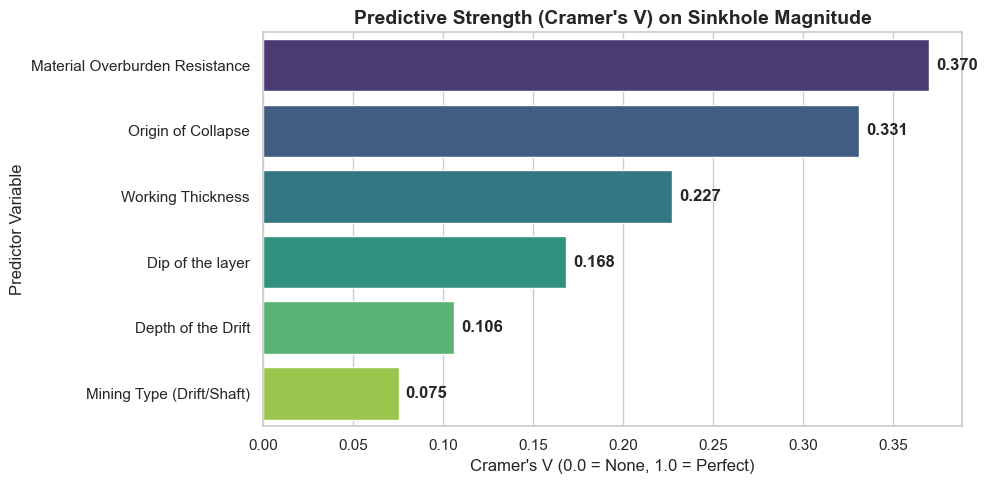

In [220]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

print("--- MULTIVARIATE EVALUATION: PREDICTIVE STRENGTH OF THE 5 FACTORS ---")

# 1. Filter data that has the actual Magnitude defined (N cases)
df_modelo = df_modelo_mag_simple.dropna(subset=['Magnitud_Real_Peor_Caso']).copy() 

# ---------------------------------------------------------
# 2. VARIABLE DISCRETIZATION (Using your exact thresholds)
# ---------------------------------------------------------
# A. Mining Type (Shaft/Drift)
df_modelo['Tipo_Galeria_Predictor'] = np.where(df_modelo['type_mining_clean'].str.contains('shaft'), '1_Shaft',
                                 np.where(df_modelo['type_mining_clean'].str.contains('drift'), '2_Drift', None))

# B. Dip
# Discretized into logical geomechanical classes
bins_dip = [-1, 5, 15, 90]
labels_dip = ['1_Flat (0-5°)', '2_Gentle (5-15°)', '3_Inclined (>15°)']
df_modelo['Buzamiento_Predictor'] = pd.cut(df_modelo['dip_clean'], bins=bins_dip, labels=labels_dip)

# C. Drift Depth (Utilizando la variable limpia: depth_drift_clean)
bins_depth = [-1, 30, 60, 2000]
labels_depth = ['1_Shallow (0-30m)', '3_Deep (30-60m)', '4_Very_Deep (>60m)']
df_modelo['Cat_Depth'] = pd.cut(df_modelo['depth_drift_clean'], bins=bins_depth, labels=labels_depth)

# D. Working Thickness
bins_thick = [-1, 2, 3.25, 100]
labels_thick = ['1_Thin (0-2m)', '2_Medium (2-3.25m)', '3_Thick (>3.25m)']
df_modelo['Cat_Thickness'] = pd.cut(df_modelo['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

# E. Overburden Resistance 
df_modelo['Cat_Resistance'] = df_modelo['overburden_resistance_numeric'].astype(str)

# F. Origin of collapse
df_modelo['Cat_Origin'] = df_modelo['origin_collapse_grouped'].astype(str)

# ---------------------------------------------------------
# 3. STATISTICAL ENGINE (Cramer's V)
# ---------------------------------------------------------
def calcular_cramers_v(confusion_matrix):
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    if min((kcorr-1), (rcorr-1)) == 0: return 0.0
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

def evaluar_fuerza(df, col_predictor, col_objetivo):
    # Generates cross-tabulation ignoring column-specific nulls
    tabla_cont = pd.crosstab(df[col_predictor], df[col_objetivo])
    if tabla_cont.empty or tabla_cont.sum().sum() < 5: return None, None
    chi2, p, dof, expected = chi2_contingency(tabla_cont)
    v_cramer = calcular_cramers_v(tabla_cont)
    return p, v_cramer

# ---------------------------------------------------------
# 4. EXECUTION AND RANKING
# ---------------------------------------------------------
# Exact mapping dictionary translated to English for the final plot
variables = {
    'Mining Type (Drift/Shaft)': 'Tipo_Galeria_Predictor', 
    'Dip of the layer': 'Buzamiento_Predictor', 
    'Depth of the Drift': 'Cat_Depth',
    'Working Thickness': 'Cat_Thickness',
    'Material Overburden Resistance': 'Cat_Resistance',
    'Origin of Collapse': 'Cat_Origin'
}

resultados = []

for nombre, col in variables.items():
    if col in df_modelo.columns:
        p_val, v_cramer = evaluar_fuerza(df_modelo, col, 'Magnitud_Real')
        if p_val is not None:
            resultados.append({
                'Variable': nombre, 
                'Original_Column': col,
                'P-Value': p_val, 
                'Cramers_V': v_cramer
            })

# Create results DataFrame and sort by predictive influence
df_resultados = pd.DataFrame(resultados).sort_values(by='Cramers_V', ascending=False)

print("\n--- FINAL PREDICTOR VARIABLES RANKING ---")
print(df_resultados.to_string(index=False))

# ---------------------------------------------------------
# 5. RANKING VISUALIZATION
# ---------------------------------------------------------
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")
ax = sns.barplot(x='Cramers_V', y='Variable', data=df_resultados, palette='viridis')

plt.title("Predictive Strength (Cramer's V) on Sinkhole Magnitude", fontweight='bold', fontsize=14)
plt.xlabel("Cramer's V (0.0 = None, 1.0 = Perfect)", fontsize=12)
plt.ylabel('Predictor Variable', fontsize=12)

for p in ax.patches:
    ax.annotate(f"{p.get_width():.3f}", 
                (p.get_width(), p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', xytext=(5, 0), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()